# Loan Default Prediction
## MIT Applied Data Science Program | Capstone Project

#### Rob Shypitka

---

Home equity lending is an important revenue stream for retail banks. Customers borrow against the value of their property, the bank earns interest over time, and when the credit performs as expected, both sides benefit. The issue is when the borrower defaults. Non-performing assets, or NPAs, are accounts that stop generating income for the bank. They reduce profit, tie up capital, and can create risk across the lending portfolio if they grow too large.

Traditionally, banks manage this risk through manual underwriting. A credit analyst reviews the application, looks at the borrower's financial history, and makes a decision. That process can work, but it has real limitations. It is slow, hard to scale, and dependent on individual judgment. Two analysts may review the same borrower and reach different conclusions. There is also a fairness concern: if past decisions were influenced by factors unrelated to creditworthiness, a manual process can carry those patterns forward without anyone noticing.

This project uses the Home Equity dataset, or HMEQ, to build a classification model that predicts whether a borrower is likely to default. The dataset covers recent home equity lending activity and contains input variables including financial history, outstanding debt, credit behavior, and employment information.

Two requirements shape the analysis. First, the model needs to be explainable. Under the Equal Credit Opportunity Act, adverse credit decisions such as denial or less favorable terms must be tied to objective financial factors. A model that performs well but cannot explain its decisions would not be useful in this setting. Second, the model should not simply repeat the weaknesses of the manual process. If historical decisions included judgment errors or bias, the goal is not to automate those same patterns, but to build something measurable, consistent, and auditable.

The main measure of success is Recall. In this problem, missing a borrower who later defaults is more costly than flagging someone for additional review. A false negative can mean the bank misses a high-risk loan, while a false positive usually means extra manual review. That tradeoff drives the model selection, threshold decisions, and performance comparisons that follow.

## Contents

1. Business Problem Overview
2. Setup & Library Imports
3. Data Understanding & Audit
4. Exploratory Data Analysis
5. Feature Engineering & Validation

   5.1 Important Insights from EDA

6. Preprocessing
7. Modeling
8. Model Evaluation & Selection
9. Threshold Tuning 
10. Feature Importance & Explainability 
11. Risk Tiers 
12. Generative AI Layer 
13. Recommendations 
14. Conclusions & Executive Summary 
15. Appendix: Data Dictionary

---

**Note to Evaluator**

This is the final submission notebook. Sections 1 through 8 cover the milestone scope: problem definition, data exploration, feature engineering, preprocessing, modeling, and model selection. Sections 9 through 14 extend that work for the final submission: threshold tuning, SHAP explainability, risk tiering, a generative AI layer for adverse action notices, business recommendations, and an executive summary. All sections are complete and the notebook runs clean end to end.

---

## 1. Business Problem Overview

**Industry Context**

The risk of loan default is not theoretical for retail banks. It is a direct hit to revenue, capital, and portfolio health. The manual underwriting process that banks have relied on to manage that risk does not scale, and it is difficult to audit. This project is an attempt to replace judgment-based decisions with a model that is measurable, consistent, and explainable.

**The Regulatory Requirement**

The Equal Credit Opportunity Act, or ECOA, sets a clear standard. Any adverse credit decision must be justified using objective financial criteria. Protected characteristics such as race, gender, national origin, and age cannot be factors, directly or indirectly. This matters for modeling because a high-accuracy model that cannot explain its decisions would not satisfy that requirement. The model needs to be interpretable, and any declined applicant should be able to receive a clear, specific explanation grounded in their financial profile.

**Objectives**

The objective of this project is to build a binary classification model that predicts whether a home equity applicant is likely to default, using their financial history and credit profile at the time of application. Predictive accuracy is important, but explainability at the individual level is equally important.

**Key Questions**

- Which applicant characteristics are most predictive of default?
- How do we handle a dataset where defaulters are underrepresented, without the model simply predicting the majority class?
- What is the right performance metric given the cost difference between the two types of errors?
- Which modeling approach best balances predictive performance with the interpretability requirement?
- At what probability threshold should an applicant be flagged as high risk?

**Problem Formulation**

This is a supervised binary classification problem. The target variable is BAD, where 1 indicates the applicant defaulted or became severely delinquent, and 0 indicates the credit was repaid. The dataset covers recent home equity lending activity and contains 12 input features including loan characteristics, property values, employment, and credit history.

The primary metric is Recall. A false negative means the model cleared an applicant who later defaulted, costing the bank the full outstanding balance plus collection expenses. A false positive means the model flagged an applicant who would have repaid, costing one additional manual review. Those two errors are not equal, and the metric choice reflects that. Maximizing Recall, while keeping Precision above a floor that makes the model operationally useful, is the approach applied throughout this analysis.

---

## 2. Setup & Library Imports

All libraries are loaded here and grouped by function. A few imports are included
now but used in later sections: `shap` and `SHAP`-related display utilities are
reserved for Section 10 (explainability), `Markdown` for Section 12 and beyond,
and `precision_recall_curve`, `roc_curve`, and `mtick` for Section 9 (threshold
tuning). Loading everything upfront keeps the notebook clean and avoids scattered
imports later.

In [1]:
# Standard library
import warnings
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick          # threshold and rate charts, Sections 9+
import seaborn as sns

# Explainability
import shap                                # feature explainability, Section 10

# Display utilities
from IPython.display import Markdown, display   # rich output formatting, Section 12+

# Scikit-learn: data prep
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

# Scikit-learn: models
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Scikit-learn: evaluation metrics
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_recall_curve,    # threshold analysis, Section 9
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,                 # ROC visualization, Section 9
)

# Gradient boosting (XGBoost)
from xgboost import XGBClassifier

# Global settings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 150
sns.set_theme(style="whitegrid", palette="muted")

# Version check
import xgboost
print(f"numpy       {np.__version__}")
print(f"pandas      {pd.__version__}")
print(f"sklearn     {__import__('sklearn').__version__}")
print(f"xgboost     {xgboost.__version__}")
print(f"shap        {shap.__version__}")
print("Environment ready.")

numpy       2.4.4
pandas      3.0.1
sklearn     1.8.0
xgboost     3.2.0
shap        0.51.0
Environment ready.


In [2]:
# DataFrame table alignment -- left-align all tables for consistent HTML rendering
import pandas as pd
from IPython.display import display, HTML

pd.set_option('display.max_colwidth', None)

display(HTML("""
<style>
  /* Left-align all DataFrame tables */
  .dataframe { margin-left: 0 !important; margin-right: auto !important; }
  .dataframe th { text-align: left !important; }
  .dataframe td { text-align: left !important; }
  /* Override Jupyter center-alignment on output areas */
  .output_html { text-align: left !important; }
  table { margin-left: 0 !important; }
</style>
"""))


In [3]:
# Disable MathJax dollar sign processing -- all $ in this notebook are currency, not LaTeX
from IPython.display import display, HTML
display(HTML("""
<script>
  window.MathJax = {
    tex: { inlineMath: [] },
    options: { skipHtmlTags: ['script','noscript','style','textarea','pre','code'] }
  };
</script>
"""))


---

## 3. Data Understanding & Audit

Before any analysis begins, the first step is a structural review. The goal is to confirm the data loaded correctly, understand what each column contains, and identify any immediate quality issues such as missing values, unexpected data types, or duplicate records. What surfaces here shapes the decisions made later in preprocessing.

In [4]:
# Read the CSV into a DataFrame
data_path = Path("hmeq.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Dataset not found at {data_path.resolve()}. "
        "Place hmeq.csv in the same folder as this notebook."
    )

data = pd.read_csv(data_path)

# Preview the first five rows to confirm the dataset loaded correctly
print('Dataset Preview (First 5 Rows)')
display(data.head())

# Shape & Structure
# Check on dimensions and column data types
print(f'\nDataset contains {data.shape[0]} rows and {data.shape[1]} columns.')
print('\nColumn Types & Non-Null Counts')
print()
data.info()

# Confirm data completeness, missing values
null_summary = pd.DataFrame(data.isnull().sum(), columns=['Missing Values'])
null_summary['% Missing'] = (null_summary['Missing Values'] / len(data) * 100).round(2)
print('\nMissing Value Check')
display(null_summary)

# Check for duplicates
print(f'Duplicate rows: {data.duplicated().sum()}')

# Summary Statistics
# Split numeric and categorical data, combined describe()
# tables can be more difficult to read
print('\nNumeric Features: Summary Statistics')
display(data.describe().T)

# Summarize categorical features to review counts, unique values, and most common categories
print('\nCategorical Features: Value Counts')
display(data.describe(include='object').T)

# Confirm target variable BAD contains only binary values before modeling
print(f"Target values: {[int(v) for v in sorted(data['BAD'].unique())]}")

Dataset Preview (First 5 Rows)


,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.00,39025.00,HomeImp,Other,10.50,0.00,0.00,94.37,1.00,9.00,NaN
1,1,1300,70053.00,68400.00,HomeImp,Other,7.00,0.00,2.00,121.83,0.00,14.00,NaN
2,1,1500,13500.00,16700.00,HomeImp,Other,4.00,0.00,0.00,149.47,1.00,10.00,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.00,112000.00,HomeImp,Office,3.00,0.00,0.00,93.33,0.00,14.00,NaN



Dataset contains 5960 rows and 13 columns.

Column Types & Non-Null Counts

<class 'pandas.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   str    
 5   JOB      5681 non-null   str    
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), str(2)
memory usage: 675.4 KB

Missing Value Check


,Missing Values,% Missing
BAD,0,0.00
LOAN,0,0.00
MORTDUE,518,8.69
VALUE,112,1.88
REASON,252,4.23
JOB,279,4.68
YOJ,515,8.64
DEROG,708,11.88
DELINQ,580,9.73
CLAGE,308,5.17


Duplicate rows: 0

Numeric Features: Summary Statistics


,count,mean,std,min,25%,50%,75%,max
BAD,5960.00,0.20,0.40,0.00,0.00,0.00,0.00,1.00
LOAN,5960.00,18607.97,11207.48,1100.00,11100.00,16300.00,23300.00,89900.00
MORTDUE,5442.00,73760.82,44457.61,2063.00,46276.00,65019.00,91488.00,399550.00
VALUE,5848.00,101776.05,57385.78,8000.00,66075.50,89235.50,119824.25,855909.00
YOJ,5445.00,8.92,7.57,0.00,3.00,7.00,13.00,41.00
DEROG,5252.00,0.25,0.85,0.00,0.00,0.00,0.00,10.00
DELINQ,5380.00,0.45,1.13,0.00,0.00,0.00,0.00,15.00
CLAGE,5652.00,179.77,85.81,0.00,115.12,173.47,231.56,1168.23
NINQ,5450.00,1.19,1.73,0.00,0.00,1.00,2.00,17.00
CLNO,5738.00,21.30,10.14,0.00,15.00,20.00,26.00,71.00



Categorical Features: Value Counts


,count,unique,top,freq
REASON,5708,2,DebtCon,3928
JOB,5681,6,Other,2388


Target values: [0, 1]


#### Observations

5,960 records, 13 columns, no duplicates. The dataset loaded cleanly and `BAD` contains only binary values as expected.

`BAD` and `LOAN` are the only complete columns. Every other feature has missing values. `DEBTINC` has the largest gap at 21.26%, followed by `DEROG` at 11.88% and `DELINQ` at 9.73%. The remaining numeric features range between 1.88% and 8.69% missing. `REASON` and `JOB` are missing 4.23% and 4.68% respectively.

A few things worth flagging before EDA. `DEROG` and `DELINQ` both show a 75th percentile of zero, meaning most applicants have no derogatory marks or delinquencies. `CLAGE` reaches a maximum of 1,168 months, roughly 97 years, and `DEBTINC` reaches 203.31. Both will need outlier treatment before modeling.

---

### Feature Type Separation

Separating numeric and categorical columns upfront keeps the analysis code cleaner throughout. `BAD` is excluded from the numeric list since it is the target.

In [5]:
# Separate numeric and categorical features
num_cols = data.select_dtypes(include="number").columns.drop("BAD")
cat_cols = data.select_dtypes(include=["object", "string"]).columns.tolist()

print("Numeric features:")
print(num_cols)

print("\nCategorical features:")
print(cat_cols)

Numeric features:
Index(['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ',
       'CLNO', 'DEBTINC'],
      dtype='str')

Categorical features:
['REASON', 'JOB']


---

## 4. Exploratory Data Analysis

The audit confirmed the structure. The focus here is on what the data actually contains. The target distribution, individual feature behavior, relationships between features, and missing data patterns are all examined here. What comes out of this section drives the feature engineering and preprocessing decisions that follow.

### Univariate Analysis

#### Target Distribution

Target Variable Distribution


,Count,% Share
No Default (0),4771,80.05
Default (1),1189,19.95


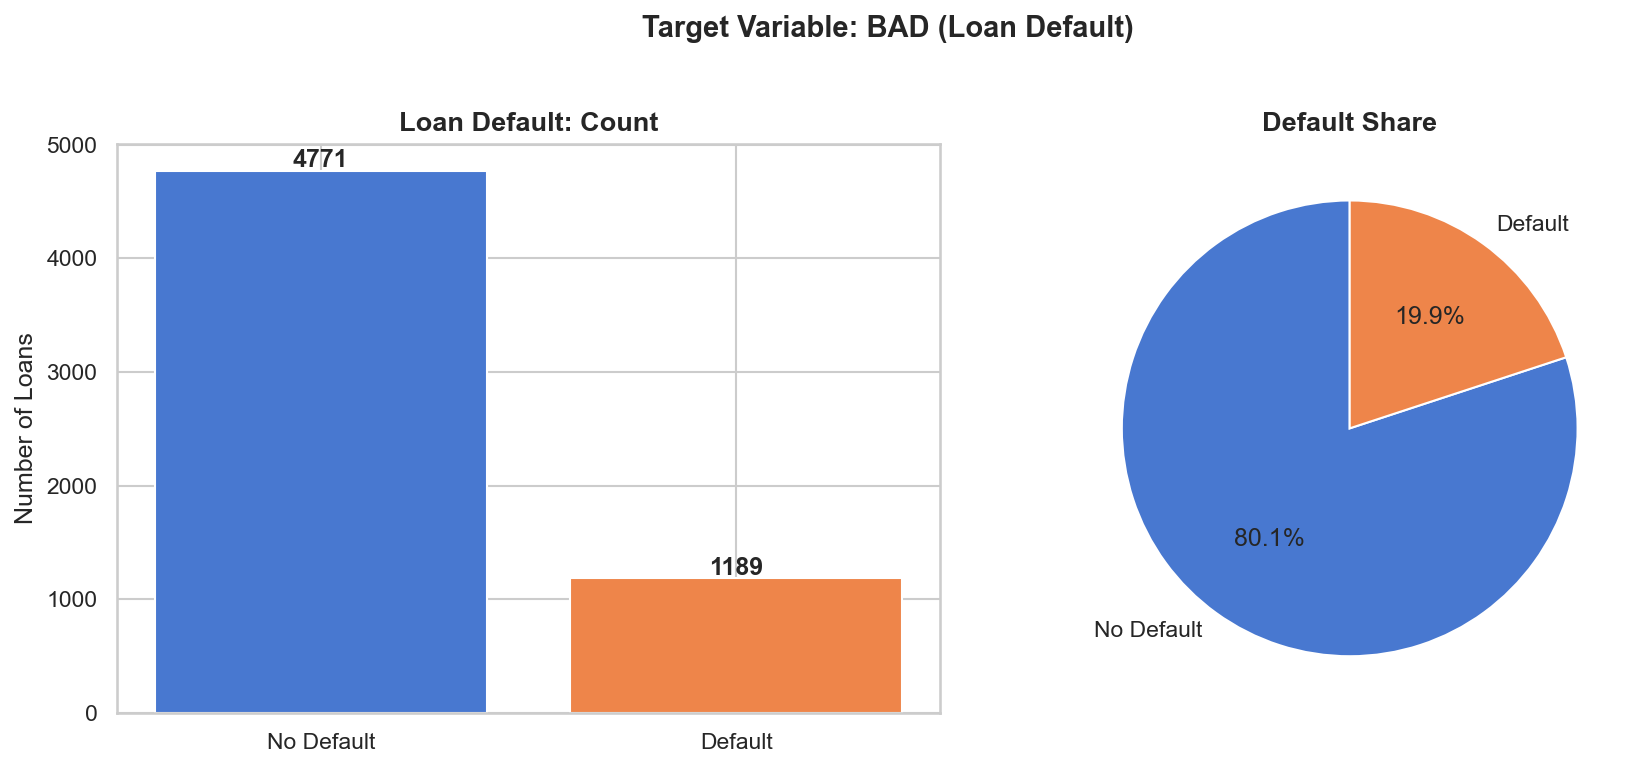

In [6]:
# Target Distribution (BAD)
# Review class balance before modeling because accuracy can be misleading with imbalanced data

# Count and percentage breakdown of the target variable
target_counts = data["BAD"].value_counts().sort_index()
target_pct = data["BAD"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "% Share": target_pct.round(2)
})

# Rename target values for readability
target_summary.index = ["No Default (0)", "Default (1)"]

print("Target Variable Distribution")
display(target_summary)

# Visualize the class split using both counts and percentages
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart showing raw counts by class
axes[0].bar(
    ["No Default", "Default"],
    target_counts.values,
    color=sns.color_palette("muted")[0:2]
)

axes[0].set_title(
    "Loan Default: Count",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel("Number of Loans")

# Add count labels above each bar
for i, v in enumerate(target_counts.values):
    axes[0].text(
        i,
        v + 30,
        str(v),
        ha="center",
        fontweight="bold"
    )

# Pie chart showing class proportions
axes[1].pie(
    target_counts.values,
    labels=["No Default", "Default"],
    autopct="%1.1f%%",
    colors=sns.color_palette("muted")[0:2],
    startangle=90
)

axes[1].set_title(
    "Default Share",
    fontsize=13,
    fontweight="bold"
)

plt.suptitle(
    "Target Variable: BAD (Loan Default)",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

#### Observations

4,771 applicants did not default (80.05%) and 1,189 did (19.95%), a ratio of roughly 4:1. That imbalance matters for modeling. A classifier that predicts No Default on every record would be 80% accurate without learning anything useful. Accuracy alone is not a meaningful measure of performance here.

All models in this analysis use class weighting to give the minority class proportional influence during training. Recall is the primary evaluation metric throughout.

---

#### Numeric Features

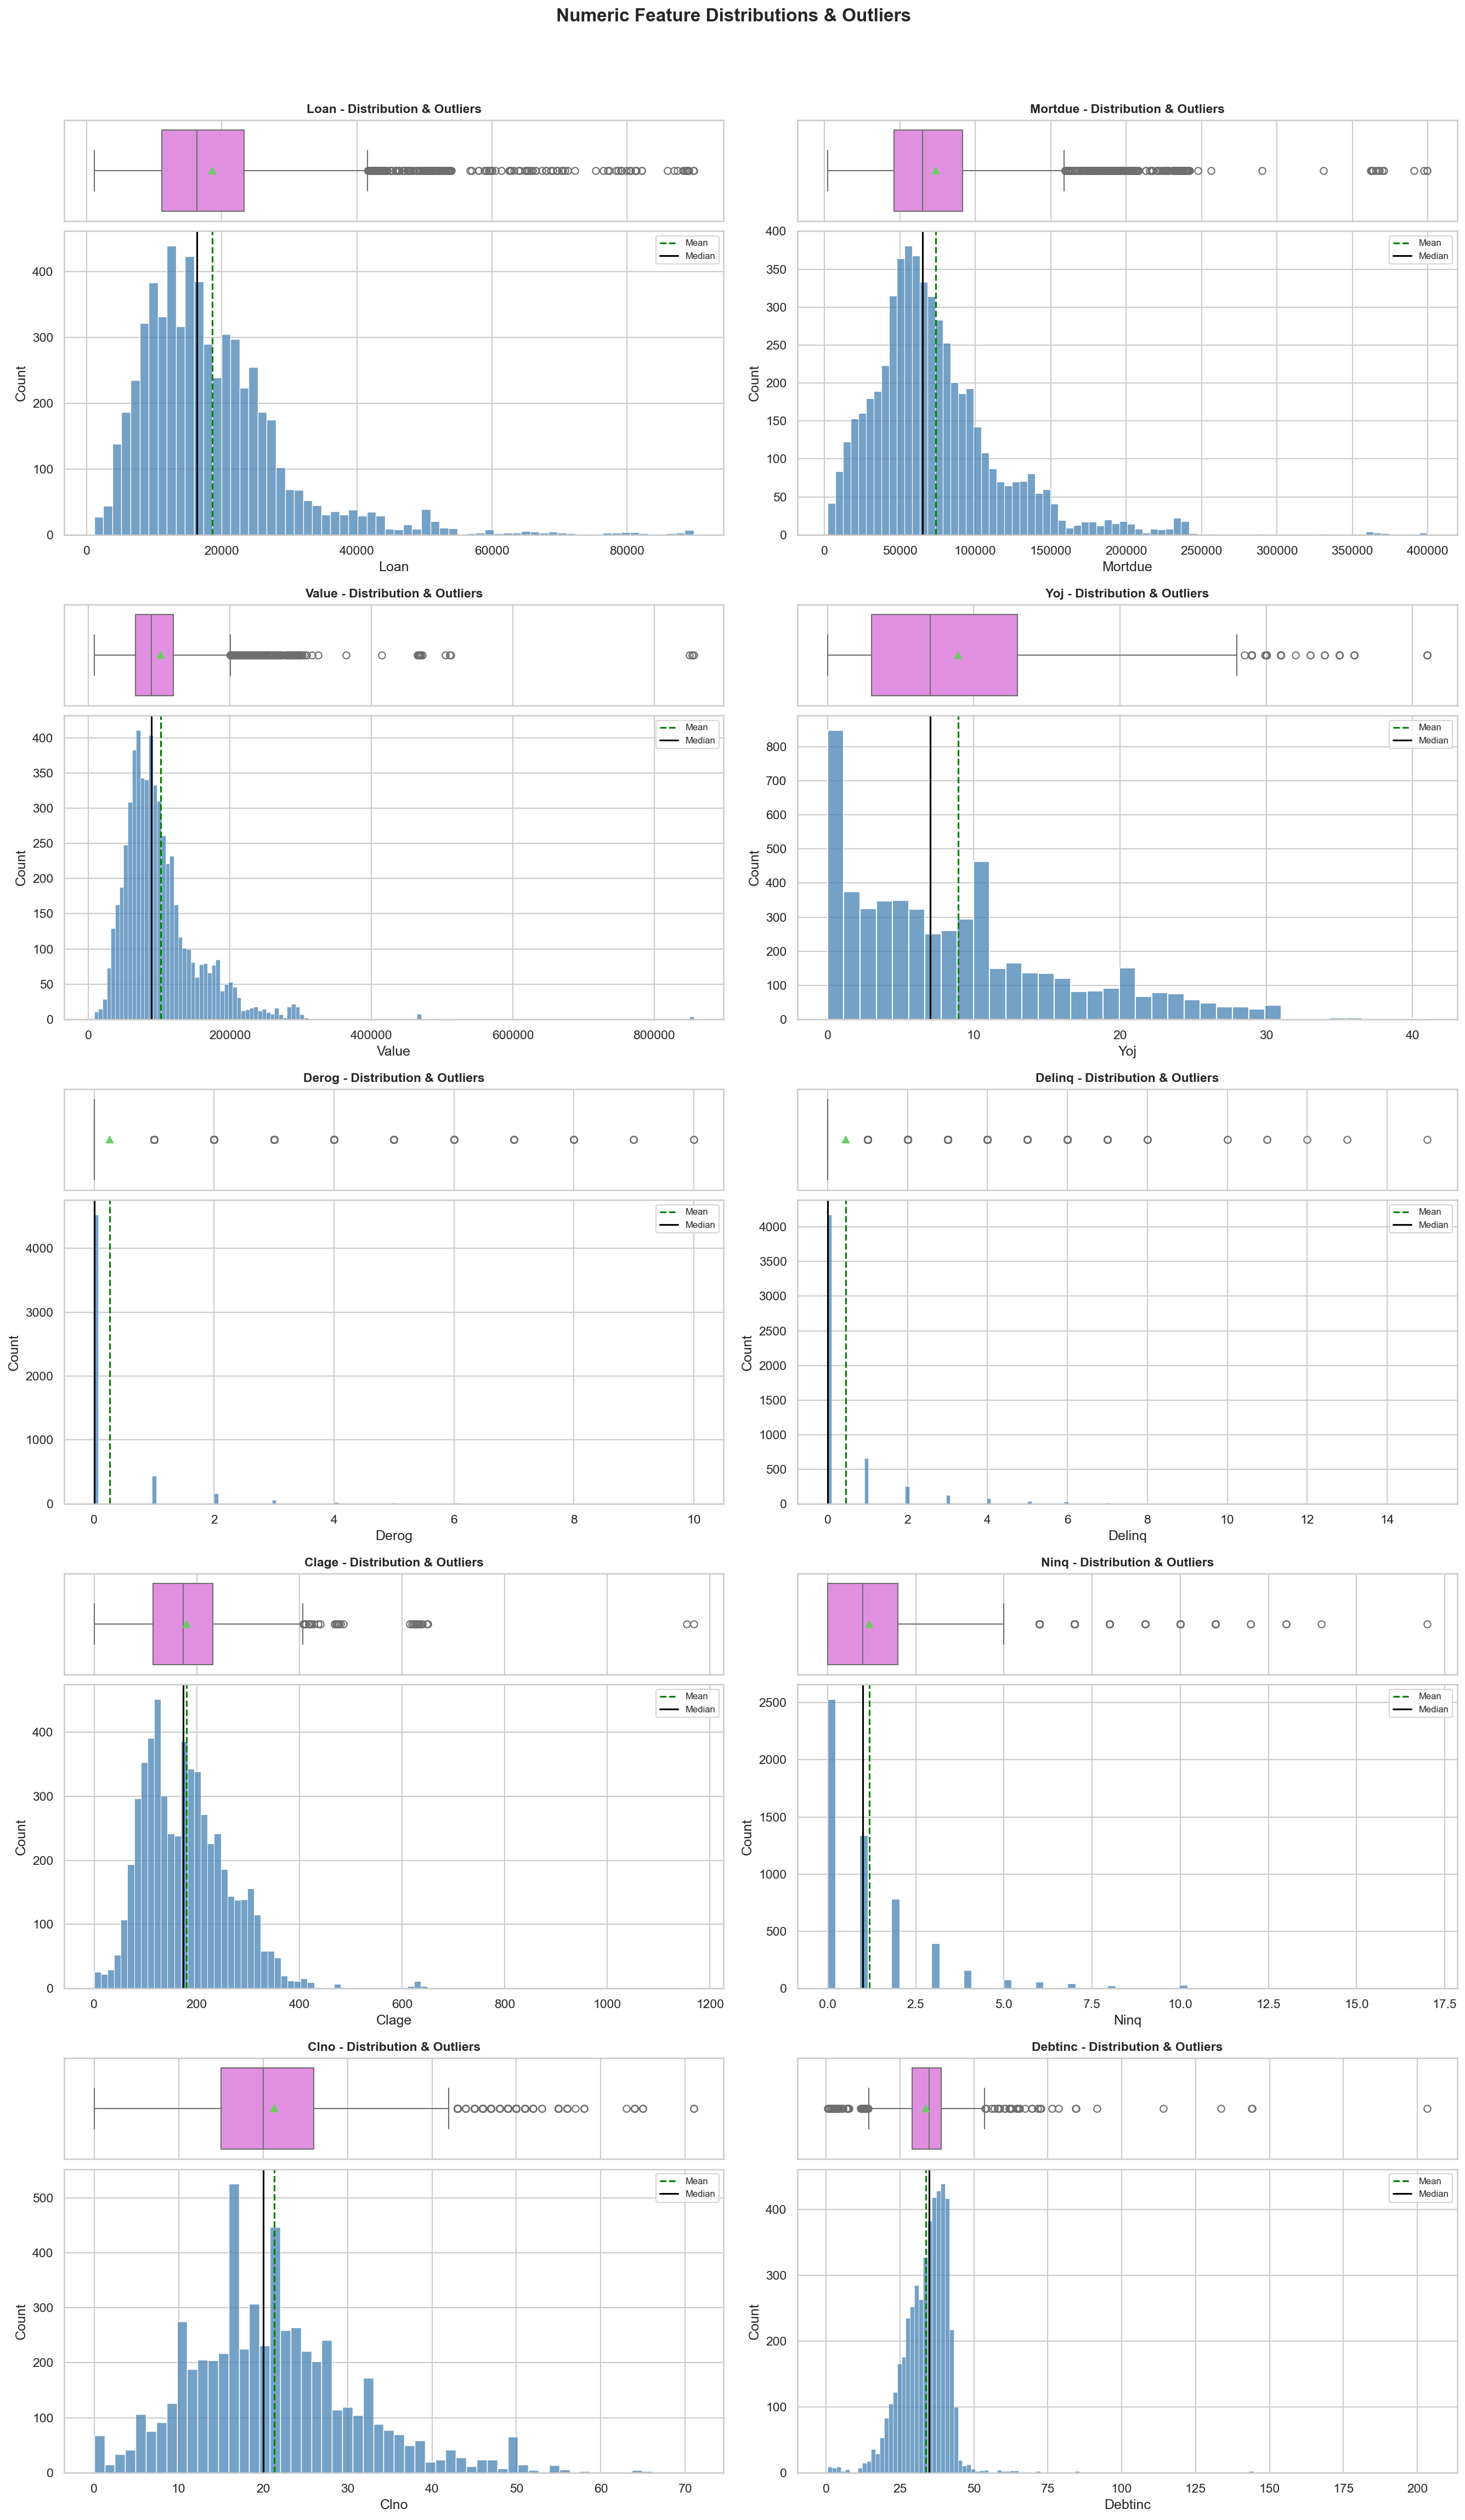

In [7]:
# Histogram & Boxplot Distributions
# Create a 5x2 layout so each numeric feature has its own distribution view
n_cols = 2
n_rows = 5

fig = plt.figure(figsize=(18, 30))

# Create the outer grid for the ten numeric features
outer_grid = fig.add_gridspec(n_rows, n_cols)

for i, feature in enumerate(num_cols):

    row = i // n_cols
    col = i % n_cols

    # Create a stacked layout for each feature: boxplot on top, histogram below
    inner_grid = outer_grid[row, col].subgridspec(
        2,
        1,
        height_ratios=[0.25, 0.75],
        hspace=0.05
    )

    ax_box = fig.add_subplot(inner_grid[0])
    ax_hist = fig.add_subplot(inner_grid[1], sharex=ax_box)

    # Boxplot shows spread and potential outliers
    sns.boxplot(
        data=data,
        x=feature,
        ax=ax_box,
        showmeans=True,
        color="violet"
    )

    # Histogram shows the feature distribution
    sns.histplot(
        data=data,
        x=feature,
        kde=False,
        ax=ax_hist,
        color="steelblue"
    )

    # Add mean and median reference lines for easier comparison
    ax_hist.axvline(
        data[feature].mean(),
        color="green",
        linestyle="--",
        label="Mean"
    )

    ax_hist.axvline(
        data[feature].median(),
        color="black",
        linestyle="-",
        label="Median"
    )

    ax_box.set_title(
        f"{feature.replace('_', ' ').title()} - Distribution & Outliers",
        fontsize=11,
        fontweight="bold"
    )

    ax_box.set_xlabel("")
    ax_hist.set_xlabel(feature.replace("_", " ").title())

    ax_box.tick_params(axis="x", labelbottom=False)
    ax_hist.legend(fontsize=8)

fig.suptitle(
    "Numeric Feature Distributions & Outliers",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

#### Observations

Most numeric features are right-skewed. `LOAN`, `MORTDUE`, `VALUE`, and `YOJ` all show the mean sitting above the median, with a longer tail of higher values pulling the distribution to the right.

`DEROG` and `DELINQ` are different from the continuous features. Both are concentrated almost entirely at zero, with a smaller group of applicants carrying one or more derogatory marks or delinquencies. That zero-heavy structure matters because treating these as ordinary continuous variables would risk losing the signal at the first nonzero value.

`CLAGE` reaches a maximum of 1,168 months, roughly 97 years, and `DEBTINC` reaches 203.31. Those upper-end values are large enough to justify outlier treatment before modeling. Several other continuous features also show high-end tails, so capping will be considered as a conservative stabilization step rather than as a claim that every large value is a data error.

`CLNO` is the most balanced numeric feature in the set. It still has some high values, but the distribution is less extreme than the credit-event counts or the property and debt variables.

---

#### Categorical Features

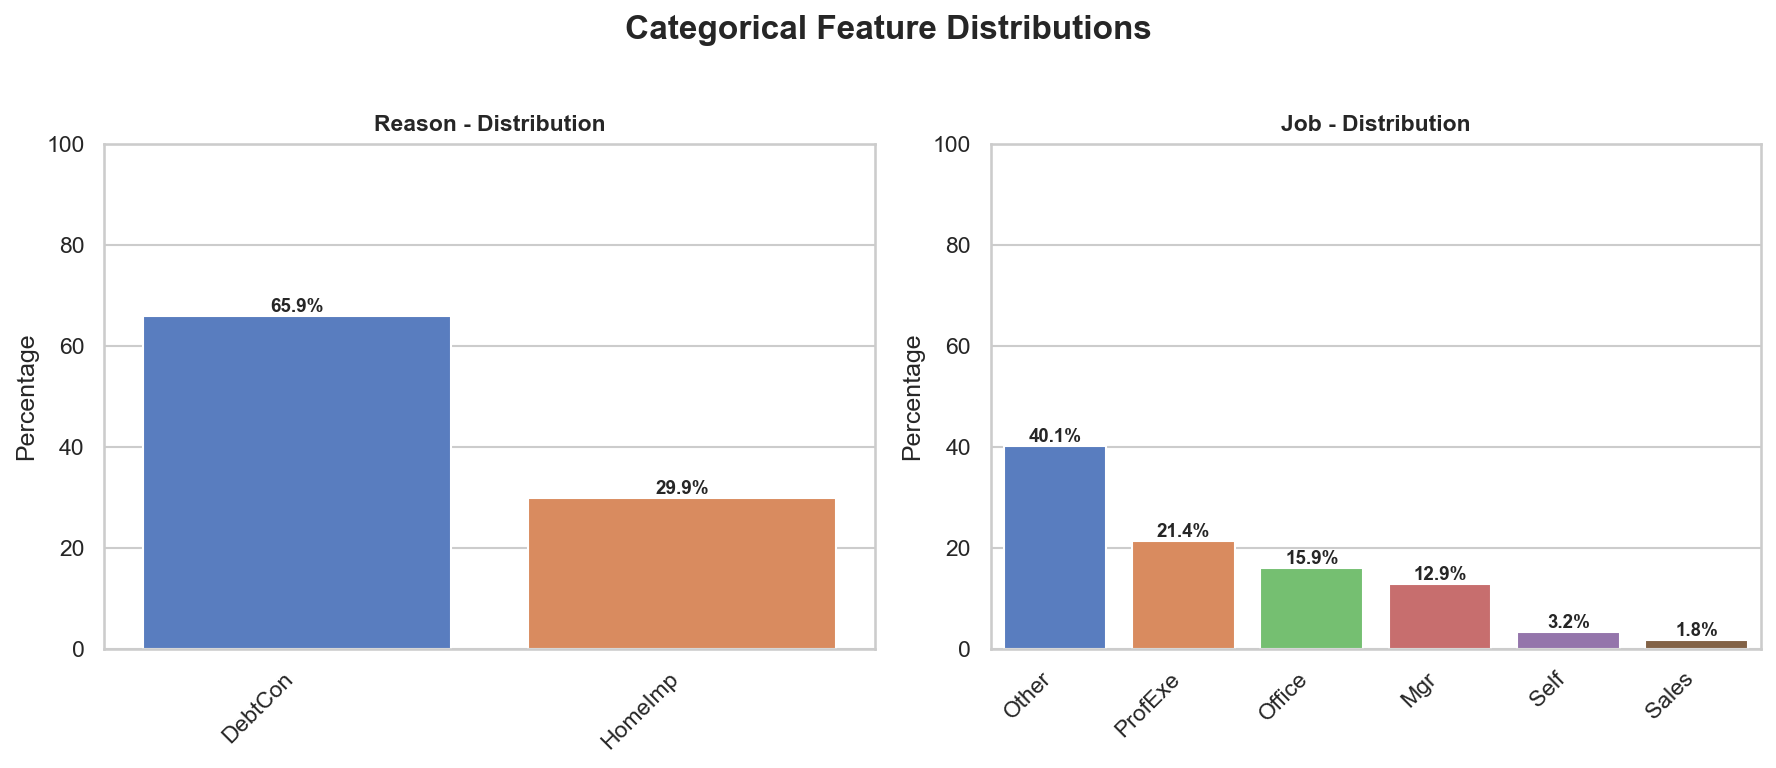

In [8]:
# Categorical Feature Distributions
# Plot each categorical feature as a percentage-based countplot for easier comparison

n_cols = 2
n_rows = 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 5))
axes = axes.flatten()

for i, feature in enumerate(cat_cols):

    # Order categories by frequency so the largest groups appear first
    order = data[feature].value_counts().index

    ax = sns.countplot(
        data=data,
        x=feature,
        hue=feature,
        order=order,
        hue_order=order,
        stat="percent",
        palette="muted",
        legend=False,
        ax=axes[i]
    )

    # Add percentage labels on top of each bar
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(
        f"{feature.replace('_', ' ').title()} - Distribution",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel("Percentage")
    ax.set_ylim(0, 100)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

    # Align rotated labels for readability
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

fig.suptitle(
    "Categorical Feature Distributions",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

# Hide any unused subplot panels
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

#### Observations

`REASON` splits between debt consolidation at 65.9% and home improvement at 29.9%. The remaining roughly 4% are missing, consistent with the audit. The dataset skews heavily toward borrowers consolidating existing debt.

`JOB` has more spread. Other accounts for 40.1% of applicants and functions as a catch-all for occupation types that do not fit the five specific categories. ProfExe comes in second at 21.4%, followed by Office at 15.9% and Mgr at 12.9%. Sales and Self-employed are thinly represented at 1.8% and 3.2% respectively.

Whether these categorical features carry meaningful predictive signal will become clearer in the multivariate analysis.

---

### Multivariate Analysis

#### Correlation Analysis

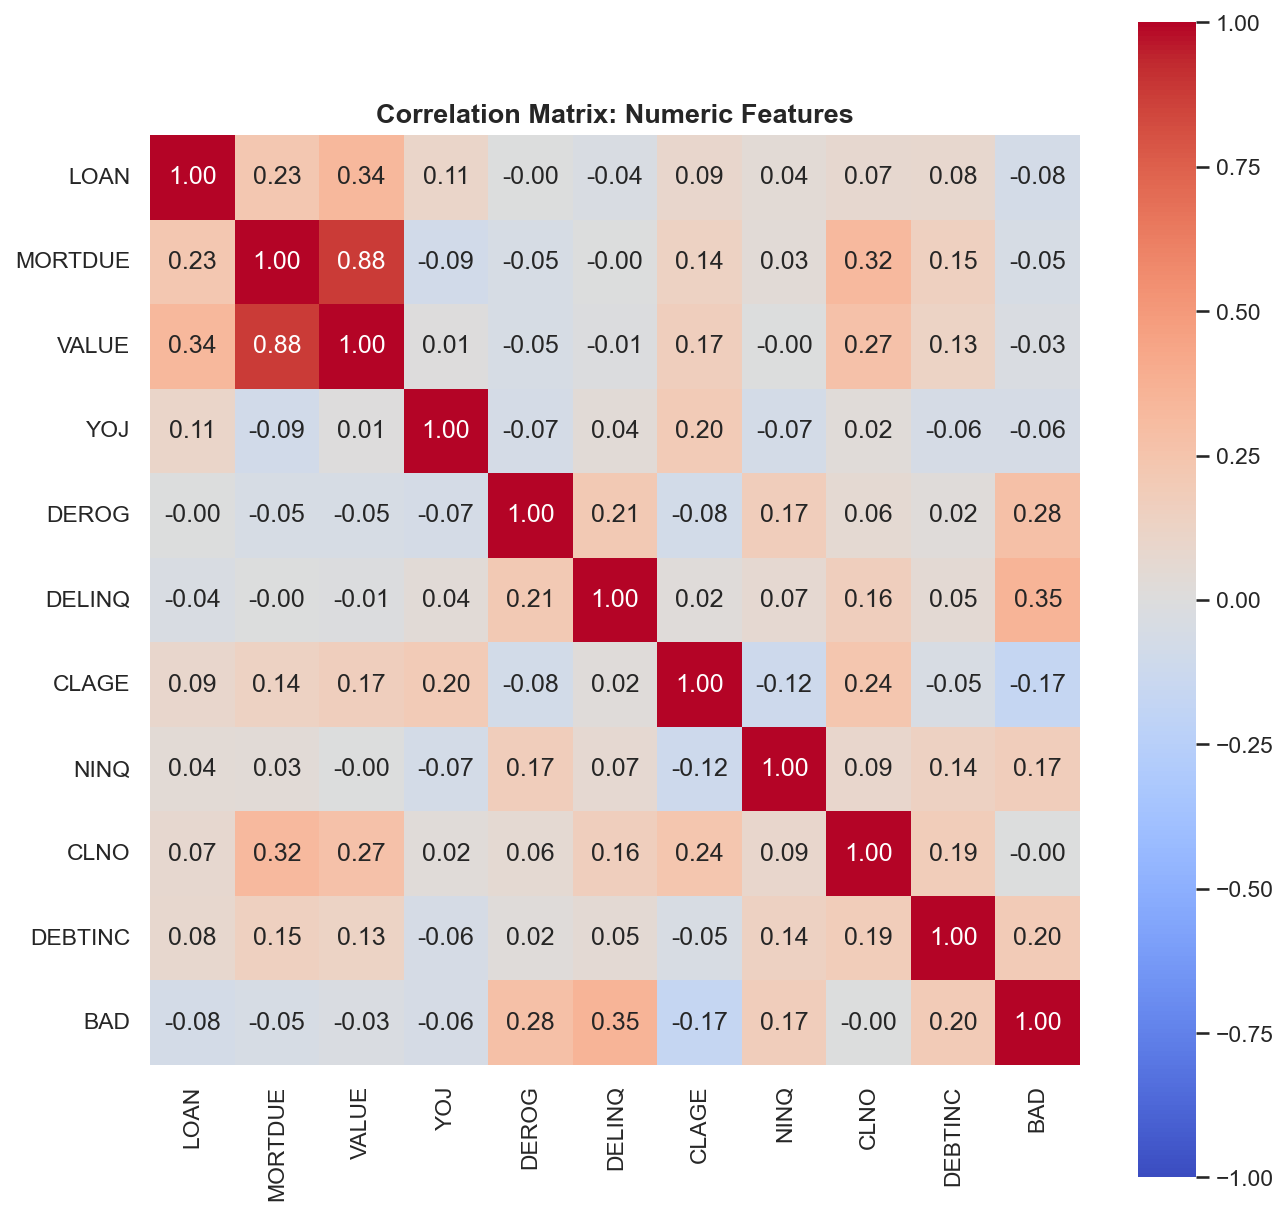

In [9]:
# Correlation matrix for numeric features and target variable
corr_features = num_cols.tolist() + ["BAD"]
corr_matrix = data[corr_features].corr()

plt.figure(figsize=(10, 10))

# Plot correlations to identify relationships between numeric features and default status
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Matrix: Numeric Features", fontsize=13, fontweight="bold")
plt.show()

#### Observations

No feature has a strong linear correlation with `BAD`. Credit default relationships tend to be nonlinear, and a correlation matrix only captures the linear component.

`DELINQ` has the highest correlation with the target at 0.35, followed by `DEROG` at 0.28 and `DEBTINC` at 0.20. `CLAGE` shows a modest negative correlation of -0.17, meaning longer credit history associates with lower default likelihood. The remaining features show minimal linear relationship with `BAD`.

The strongest feature-to-feature relationship is between `MORTDUE` and `VALUE` at 0.88. That is expected since the amount owed on a mortgage and the value of the underlying property tend to move together. Tree-based models handle this collinearity reasonably well, but it is something to keep in mind when interpreting feature contributions.

The weak linear correlations across the board suggest that a linear model will have a limited ceiling here, and that tree-based approaches are better suited to capturing the actual structure in the data.

---

#### Default Rates by Category

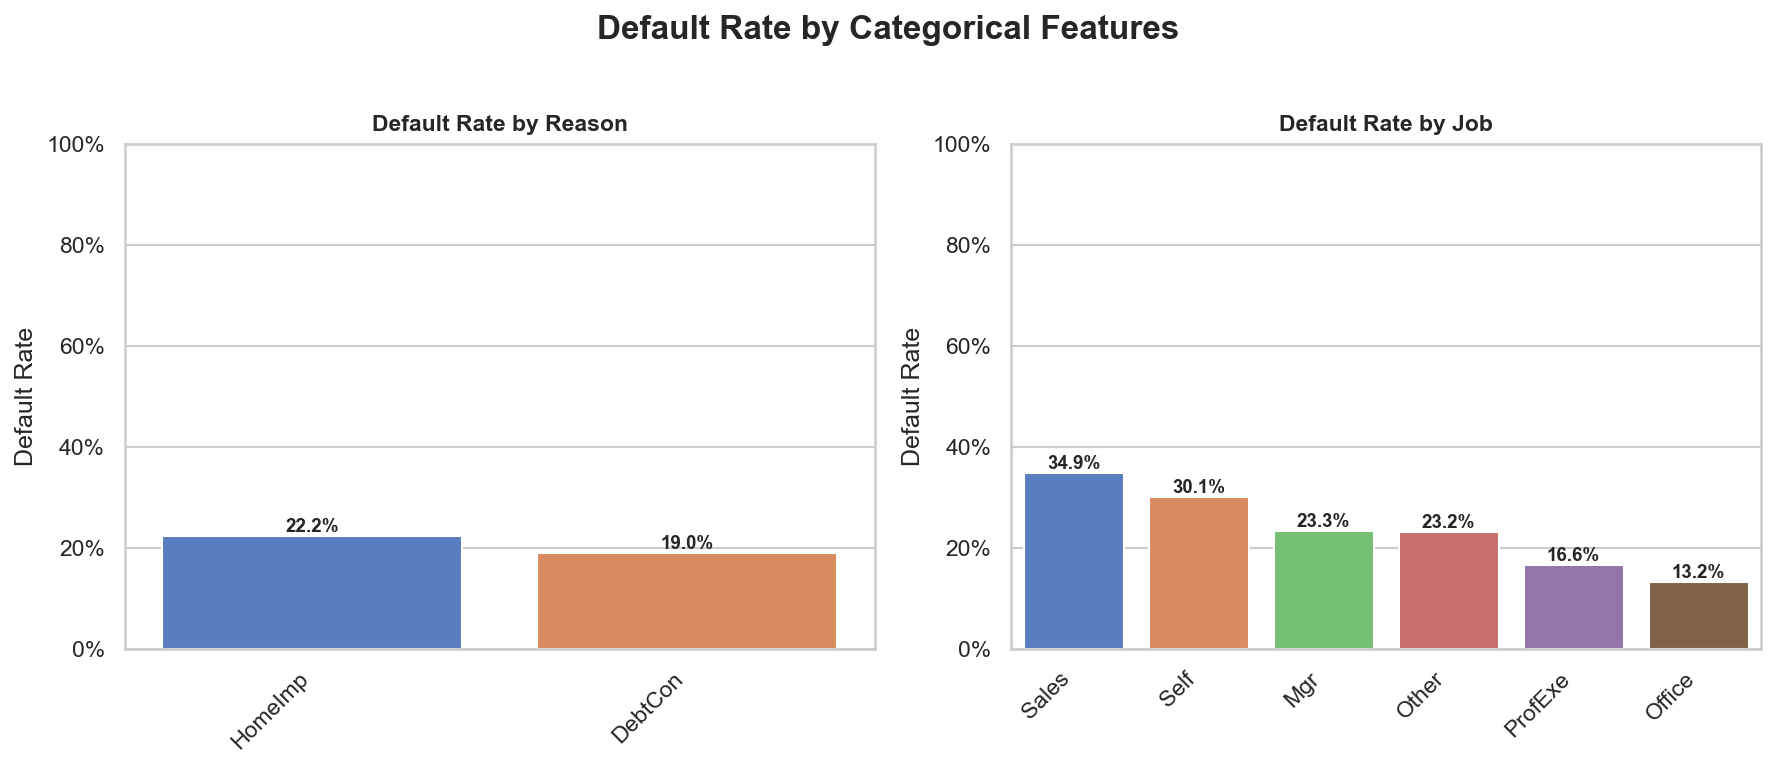

In [10]:
# Categorical Features vs Target Variable
# Plot default rate for each categorical feature on the same chart grid

n_cols = 2
n_rows = 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 5))
axes = axes.flatten()

for i, feature in enumerate(cat_cols):

    # Default rate per category
    default_rates = (
        data.groupby(feature)["BAD"]
        .mean()
        .reset_index()
    )

    # Sort categories by default rate from highest to lowest
    order = default_rates.sort_values("BAD", ascending=False)[feature]

    ax = sns.barplot(
        data=default_rates,
        x=feature,
        y="BAD",
        hue=feature,
        order=order,
        hue_order=order,
        palette="muted",
        legend=False,
        ax=axes[i]
    )

    # Add percentage labels on top of each bar
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height() * 100:.1f}%",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(
        f"Default Rate by {feature.replace('_', ' ').title()}",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel("Default Rate")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

    # Align rotated labels for readability
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

fig.suptitle(
    "Default Rate by Categorical Features",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

# Hide any unused subplot panels
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

#### Observations

`REASON` shows almost no separation. HomeImp defaults at 22.2% and DebtCon at 19.0%, a 3.2 percentage point difference. Both sit close to the overall dataset default rate of roughly 20%. Loan purpose alone does not carry much predictive weight.

`JOB` shows more spread. Sales leads at 34.9%, followed by Self-employed at 30.1%. Both are above the dataset average, though these are the two smallest categories by volume at 1.8% and 3.2% respectively. Those rates are based on thin samples and should be interpreted carefully. Office sits at the other end at 13.2%, with ProfExe at 16.6%.

Neither categorical feature is a strong standalone predictor. Their value in the model will likely come in combination with the credit history features.

---

#### Numeric Features vs. Default

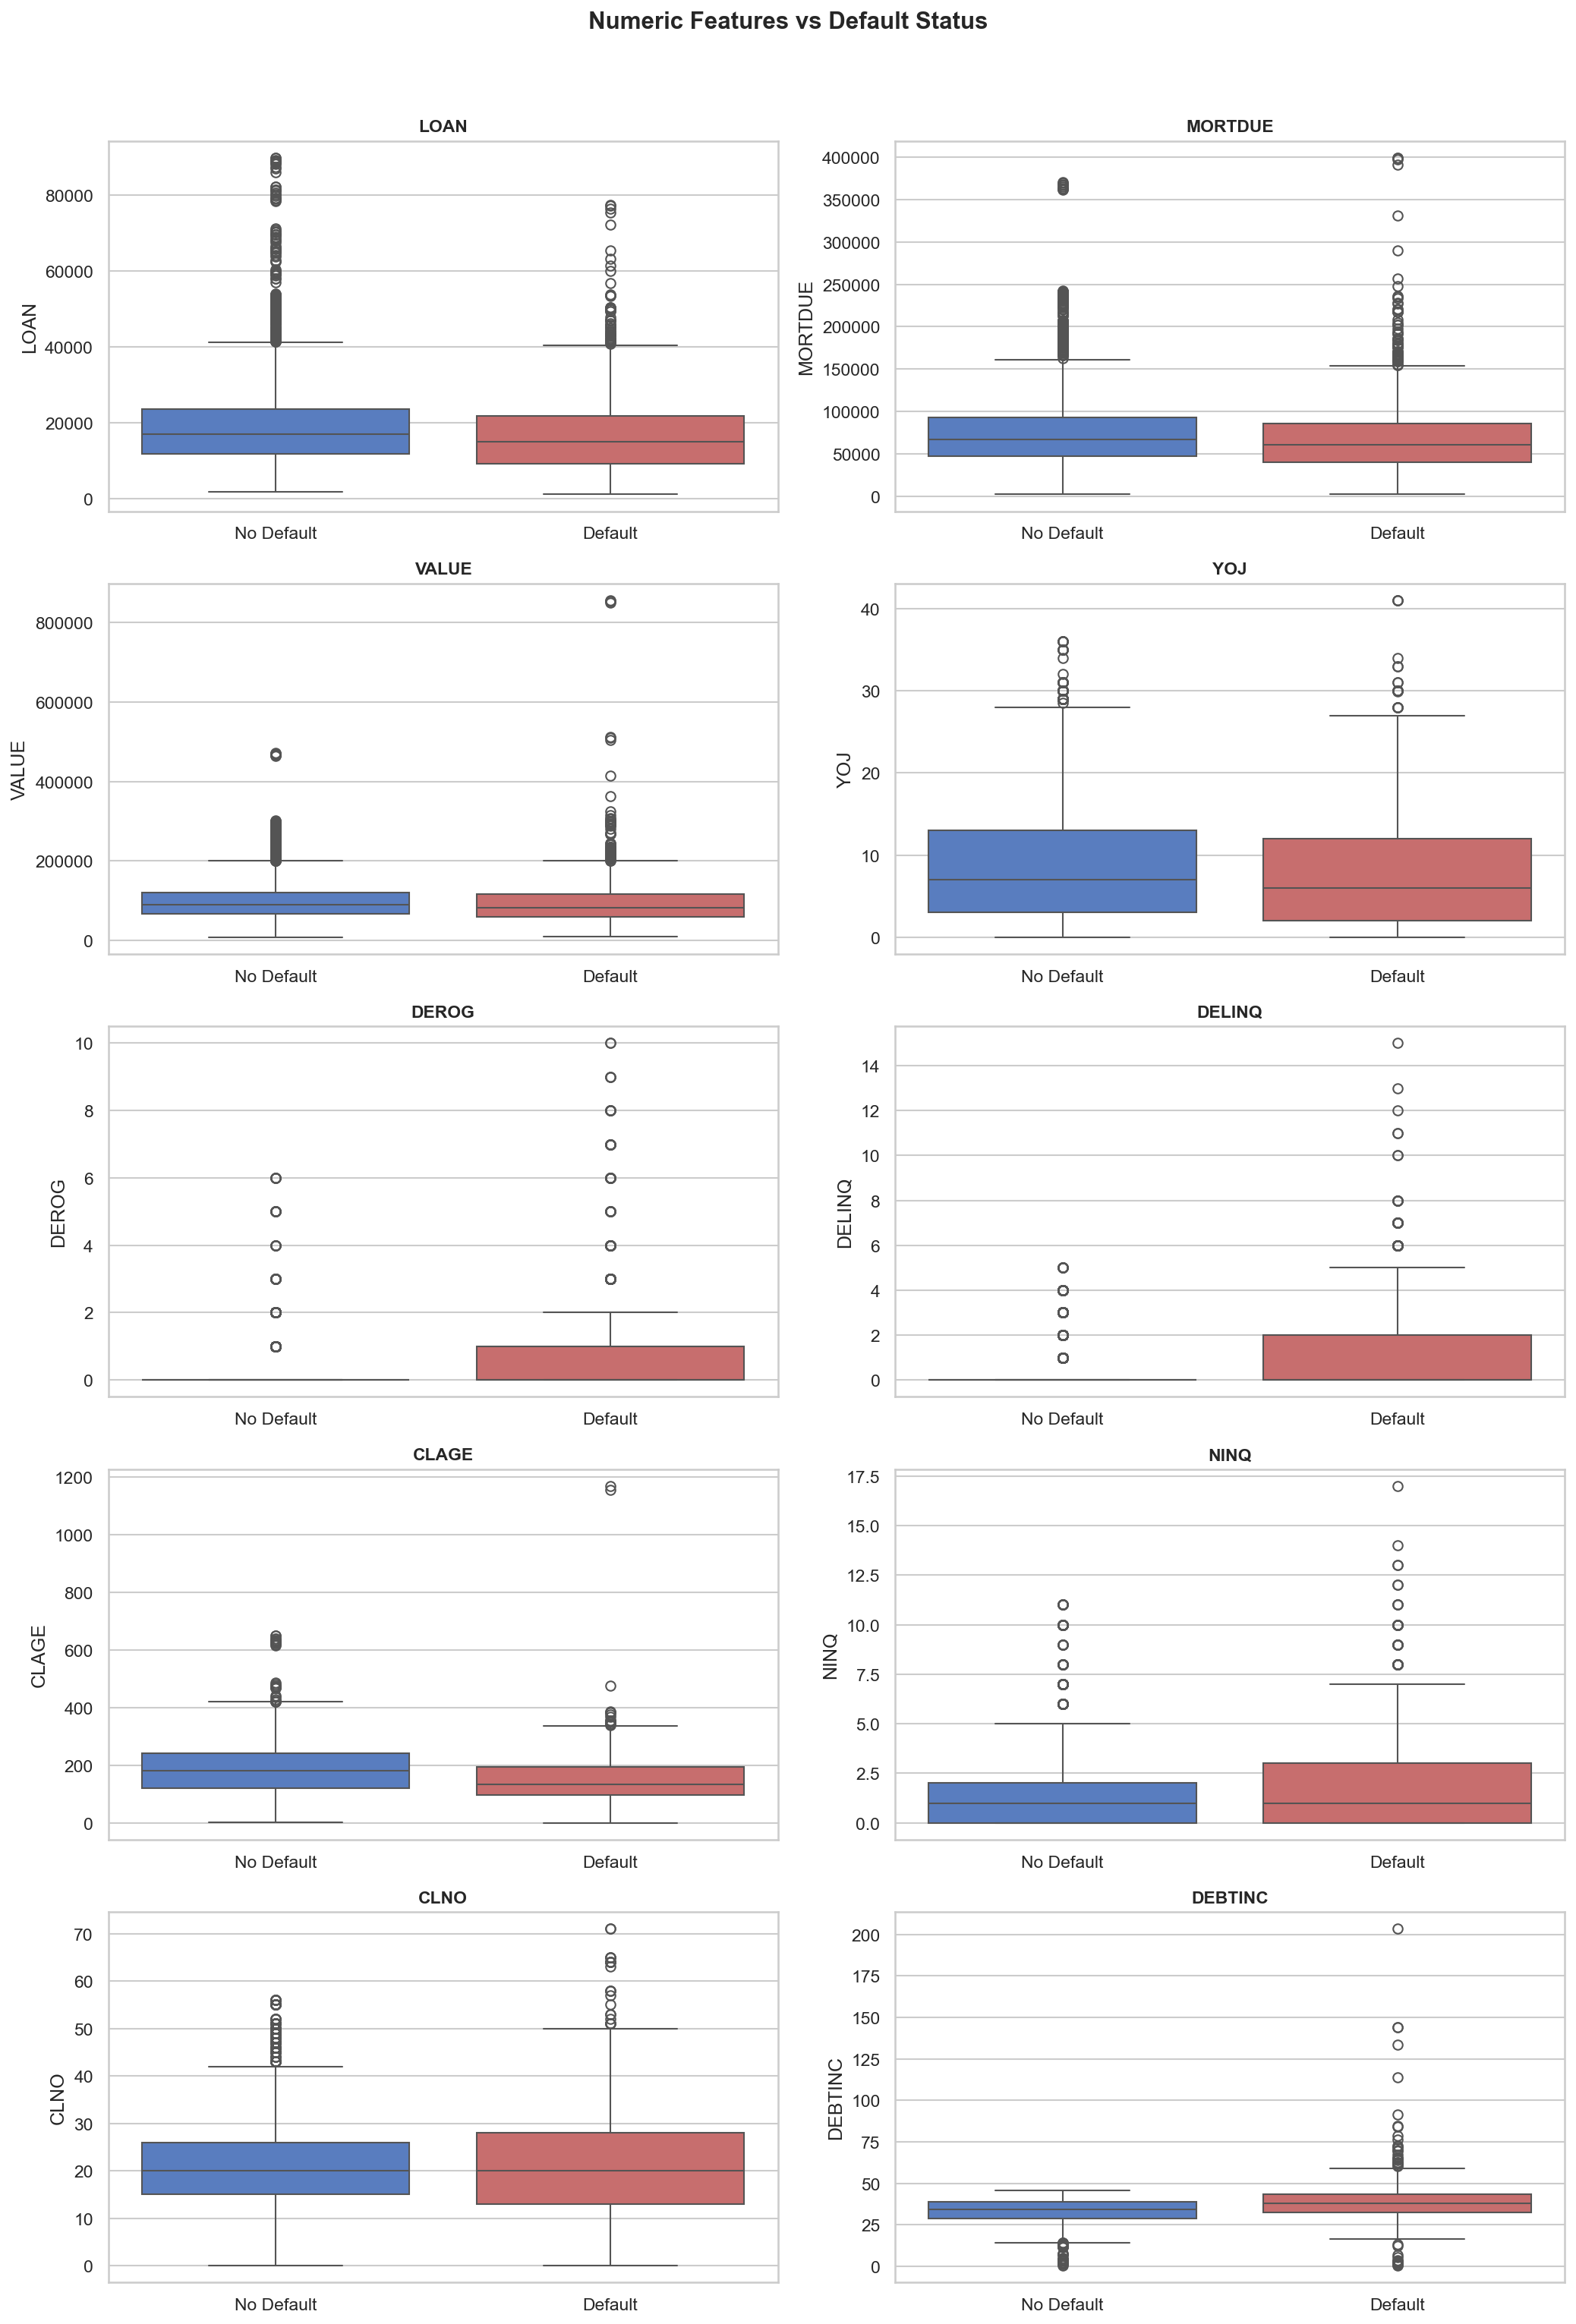

In [11]:
# Compare numeric feature distributions by default status
# Each numeric feature is shown as a side-by-side boxplot for No Default vs Default

# Set grid layout based on the number of numeric features
n_cols = 2
n_rows = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 4))
axes = axes.flatten()

# Use consistent colors for the two target classes
palette = {
    0: sns.color_palette("muted")[0],
    1: sns.color_palette("muted")[3]
}

for i, feature in enumerate(num_cols):
    
    # Plot each numeric feature against the default status
    sns.boxplot(
        data=data,
        x="BAD",
        y=feature,
        hue="BAD",
        palette=palette,
        legend=False,
        ax=axes[i]
    )
    
    # Format subplot labels
    axes[i].set_title(
        feature, 
        fontsize=11, 
        fontweight="bold"
    )
    
    axes[i].set_xlabel("")
    axes[i].set_xticklabels(["No Default", "Default"])


fig.suptitle(
    "Numeric Features vs Default Status", 
    fontsize=15, 
    fontweight="bold",
    y=1.02
)

# Hide any unused subplot panels
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
    
plt.tight_layout()
plt.show()

#### Observations

`CLAGE` shows the clearest separation. Non-defaulters have a noticeably higher median credit line age than defaulters. Longer credit history consistently associates with lower default likelihood.

`DEROG` and `DELINQ` follow a similar pattern. Both are anchored near zero for non-defaulters, while defaulters show a higher median and wider spread. Even one derogatory mark or delinquent credit line shifts the distribution meaningfully.

`DEBTINC` shows a modest upward shift in median for defaulters, though the overlap between the two groups is substantial. It likely contributes more in combination with other features than on its own.

`LOAN`, `MORTDUE`, `VALUE`, `YOJ`, `NINQ`, and `CLNO` show minimal visual separation. Their distributions are similar across both classes, consistent with the weak correlations seen earlier.

---

#### Loan Amount Bucket vs Default Rate

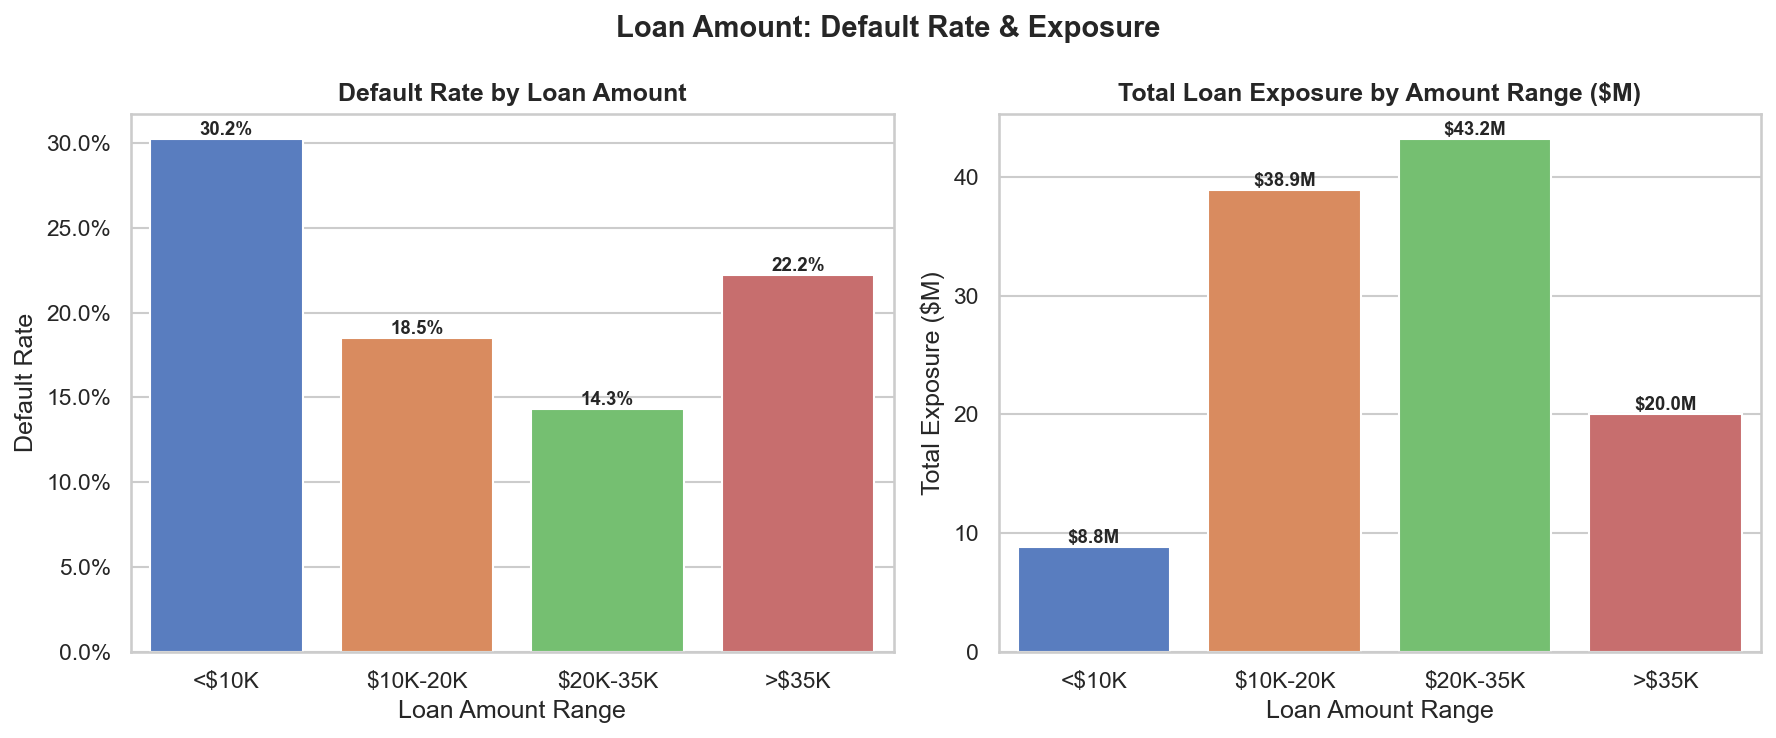

Loan Bucket Summary


,loan_range,Total_Loans,Default_Rate_Pct,Total_Exposure_M
0,<$10K,1211,30.20,8.85
1,$10K-20K,2620,18.50,38.85
2,$20K-35K,1715,14.30,43.17
3,>$35K,414,22.20,20.03


In [12]:
# Default rate by loan amount bucket
# Bin LOAN into ranges to show whether default risk concentrates in smaller or larger loans
loan_bins = [0, 10000, 20000, 35000, 90000]
loan_labels = ["<$10K", "$10K-20K", "$20K-35K", ">$35K"]

loan_bucket = data.copy()
loan_bucket["loan_range"] = pd.cut(
    loan_bucket["LOAN"],
    bins=loan_bins,
    labels=loan_labels
)

bucket_summary = loan_bucket.groupby("loan_range", observed=True).agg(
    Default_Rate=("BAD", "mean"),
    Total_Loans=("BAD", "count"),
    Total_Exposure=("LOAN", "sum")
).reset_index()

bucket_summary["Default_Rate_Pct"] = (bucket_summary["Default_Rate"] * 100).round(1)
bucket_summary["Total_Exposure_M"] = (bucket_summary["Total_Exposure"] / 1_000_000).round(2)

# Two-panel chart: default rate and total exposure side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Default rate by bucket
sns.barplot(
    data=bucket_summary,
    x="loan_range",
    y="Default_Rate",
    hue="loan_range",
    palette="muted",
    legend=False,
    dodge=False,
    ax=axes[0]
)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title("Default Rate by Loan Amount", fontweight="bold")
axes[0].set_xlabel("Loan Amount Range")
axes[0].set_ylabel("Default Rate")

# Add default-rate labels
for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height() * 100:.1f}%",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# Total exposure by bucket
sns.barplot(
    data=bucket_summary,
    x="loan_range",
    y="Total_Exposure_M",
    hue="loan_range",
    palette="muted",
    legend=False,
    dodge=False,
    ax=axes[1]
)
axes[1].set_title("Total Loan Exposure by Amount Range ($M)", fontweight="bold")
axes[1].set_xlabel("Loan Amount Range")
axes[1].set_ylabel("Total Exposure ($M)")

# Add exposure labels
for p in axes[1].patches:
    axes[1].annotate(
        f"${p.get_height():.1f}M",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

fig.suptitle(
    "Loan Amount: Default Rate & Exposure",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Loan Bucket Summary")
display(bucket_summary[["loan_range", "Total_Loans", "Default_Rate_Pct", "Total_Exposure_M"]])

#### Observations

Smaller loans default at the highest rate. The under $10K bucket carries a 30.2% default rate, well above the dataset average of roughly 20%. That drops to 18.5% and 14.3% in the two middle buckets before rising again to 22.2% for loans above $35K.

The exposure picture runs in the opposite direction. The under $10K bucket represents only $8.8M in total loan volume, so despite the high default rate the dollar risk is limited. The $20K to $35K bucket carries the largest exposure at $43.2M with the lowest default rate at 14.3%. The over $35K bucket is the one worth watching: $20.0M in exposure at a 22.2% default rate, meaning roughly $4.4M of that portfolio is at elevated risk.

The model predicts who defaults. This analysis begins to quantify what a missed default actually costs depending on where in the loan range it sits. That context carries into the recommendations section.

---

### Missing Data Pattern Analysis

Before moving to preprocessing, checking whether the missing data is random or whether it concentrates in one class matters. If nulls in a key feature like `DEBTINC` cluster among defaulters, that pattern carries signal and affects how imputation is handled.

Missing Rate by Default Status


,Overall %,BAD=0 %,BAD=1 %,Diff (1 - 0)
DEBTINC,21.26,10.08,66.11,56.03
VALUE,1.88,0.15,8.83,8.68
CLAGE,5.17,4.82,6.56,1.74
CLNO,3.72,3.54,4.46,0.92
MORTDUE,8.69,8.64,8.92,0.28
REASON,4.23,4.28,4.04,-0.24
NINQ,8.56,9.12,6.31,-2.81
JOB,4.68,5.37,1.93,-3.44
YOJ,8.64,9.43,5.47,-3.96
DELINQ,9.73,10.65,6.06,-4.59


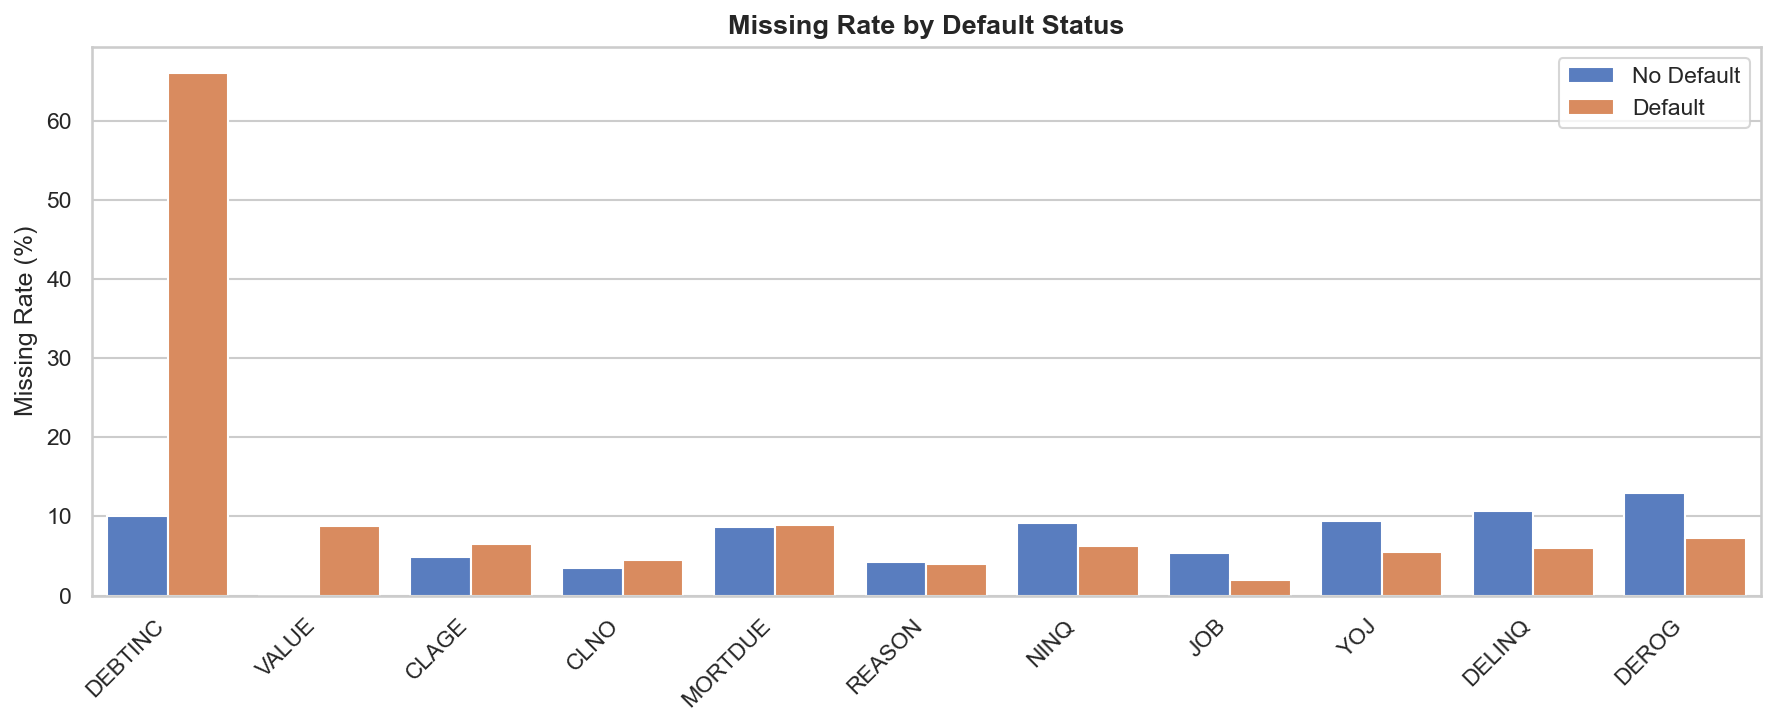

In [13]:
# Check whether null rates differ between defaulters and non-defaulters
missing_cols = [col for col in data.columns if data[col].isnull().any()]

missing_by_class = pd.DataFrame({
    'Overall %':   (data[missing_cols].isnull().mean() * 100).round(2),
    'BAD=0 %':     (data[data['BAD'] == 0][missing_cols].isnull().mean() * 100).round(2),
    'BAD=1 %':     (data[data['BAD'] == 1][missing_cols].isnull().mean() * 100).round(2),
})
missing_by_class['Diff (1 - 0)'] = (missing_by_class['BAD=1 %'] - missing_by_class['BAD=0 %']).round(2)
missing_by_class = missing_by_class.sort_values('Diff (1 - 0)', ascending=False)

print('Missing Rate by Default Status')
display(missing_by_class)

# Grouped bar chart -- more readable than a heatmap, directly shows where nulls cluster
missing_plot = missing_by_class[['BAD=0 %', 'BAD=1 %']].reset_index()
missing_plot = missing_plot.rename(columns={'index': 'Feature'})
missing_plot = missing_plot.melt(
    id_vars='Feature',
    value_vars=['BAD=0 %', 'BAD=1 %'],
    var_name='Class',
    value_name='Missing %'
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=missing_plot,
    x='Feature',
    y='Missing %',
    hue='Class',
    palette='muted'
)
plt.title('Missing Rate by Default Status', fontsize=13, fontweight='bold')
plt.xlabel('')
plt.ylabel('Missing Rate (%)')
handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles, labels=['No Default', 'Default'], title='')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### Observations

`DEBTINC` is the standout. It is missing at 10.1% among non-defaulters and 66.1% among defaulters. Every other feature shows similar missing rates across both classes, or slightly higher rates among non-defaulters.

`VALUE` shows a smaller directional skew toward defaulters, missing at roughly 9% for defaults versus near zero for non-defaulters. The remaining features show modest and fairly symmetric missing rates, suggesting their nulls are closer to random.

`DEBTINC` nullness is not a data quality problem to be corrected. It is a signal. A binary flag capturing whether `DEBTINC` was present at application time must be created before imputation runs. That is the first step in the feature engineering section that follows.

---

## 5. Feature Engineering & Validation

EDA identified several patterns where a transformed or derived feature may carry more signal than the raw column. Before committing to any of them, each is validated against the data. Nothing gets added to the feature set without a number behind it.

In [14]:
# DEBTINC missing flag -- default rate where present vs null
debtinc_check = data.groupby(data["DEBTINC"].isnull())["BAD"].agg(["mean", "count"])
debtinc_check.index = ["DEBTINC Present", "DEBTINC Missing"]
debtinc_check.columns = ["Default Rate", "Count"]
debtinc_check["Default Rate"] = (debtinc_check["Default Rate"] * 100).round(1).astype(str) + "%"

print("DEBTINC: Default Rate by Null Status")
display(debtinc_check)

# DEROG flag validation -- keep missing values separate from confirmed zero
derog_status = pd.Series(
    np.select(
        [
            data["DEROG"].isna(),
            data["DEROG"] > 0
        ],
        [
            "DEROG Missing",
            "DEROG > 0"
        ],
        default="DEROG = 0"
    ),
    index=data.index
)

derog_check = data.groupby(derog_status)["BAD"].agg(["mean", "count"])
derog_check = derog_check.reindex(["DEROG = 0", "DEROG > 0", "DEROG Missing"])
derog_check.index.name = None
derog_check.columns = ["Default Rate", "Count"]
derog_check["Default Rate"] = (derog_check["Default Rate"] * 100).round(1).astype(str) + "%"

print("\nDEROG: Default Rate by Known Zero, Positive, and Missing")
display(derog_check)

# DELINQ flag validation -- keep missing values separate from confirmed zero
delinq_status = pd.Series(
    np.select(
        [
            data["DELINQ"].isna(),
            data["DELINQ"] > 0
        ],
        [
            "DELINQ Missing",
            "DELINQ > 0"
        ],
        default="DELINQ = 0"
    ),
    index=data.index
)

delinq_check = data.groupby(delinq_status)["BAD"].agg(["mean", "count"])
delinq_check = delinq_check.reindex(["DELINQ = 0", "DELINQ > 0", "DELINQ Missing"])
delinq_check.index.name = None
delinq_check.columns = ["Default Rate", "Count"]
delinq_check["Default Rate"] = (delinq_check["Default Rate"] * 100).round(1).astype(str) + "%"

print("\nDELINQ: Default Rate by Known Zero, Positive, and Missing")
display(delinq_check)

DEBTINC: Default Rate by Null Status


,Default Rate,Count
DEBTINC Present,8.6%,4693
DEBTINC Missing,62.0%,1267



DEROG: Default Rate by Known Zero, Positive, and Missing


,Default Rate,Count
DEROG = 0,16.7%,4527
DEROG > 0,48.0%,725
DEROG Missing,12.3%,708



DELINQ: Default Rate by Known Zero, Positive, and Missing


,Default Rate,Count
DELINQ = 0,14.0%,4179
DELINQ > 0,44.5%,1201
DELINQ Missing,12.4%,580


#### Observations

All three checks confirm that the engineered flags are justified.

`DEBTINC` missing carries a 62.0% default rate against 8.6% where the value is present. That is a 53-point gap across 1,267 records. The nullness itself is the signal, not just the missing numeric value.

`DEROG` shows a clear step change among known values. Applicants with confirmed zero derogatory reports default at approximately 16.7%, while applicants with at least one derogatory report default at 48.0%. Missing `DEROG` values are kept separate in the validation because unknown credit history should not be treated as the same thing as a confirmed clean record.

`DELINQ` follows the same pattern. Applicants with confirmed zero delinquencies default at approximately 14.0%, while applicants with one or more delinquent credit lines default at 44.5%. Again, missing values are preserved separately until the imputer handles them downstream.

`mortgage_to_value_ratio` is a standard credit-risk metric and does not require the same threshold validation. It will be included in preprocessing as a ratio feature that captures existing mortgage debt relative to property value.

---

## 5.1 Important Insights from EDA

The exploratory analysis surfaced several patterns that directly shaped the preprocessing and modeling decisions that follow. The table below consolidates those findings in one place.

| Feature / Pattern | Key Finding | Decision Made |
|---|---|---|
| Class imbalance | 80.05% No Default, 19.95% Default. A naive classifier predicting No Default on every record would be 80% accurate without learning anything. | All models use class weighting. Recall is the primary evaluation metric throughout. |
| DEBTINC missingness | Missing at 66.1% among defaulters vs 10.1% among non-defaulters. A 56-point gap across 1,267 records. | Created `DEBTINC_missing` binary flag before imputation. The nullness itself is a credit risk signal. |
| DEROG threshold | Among known values, applicants with DEROG > 0 default at approximately 48.0%, compared with approximately 16.7% for applicants with confirmed DEROG = 0. Missing DEROG values are preserved separately until imputation. | Created `derog_flag`. Excluded DEROG from IQR capping to preserve the zero-inflated count structure and avoid erasing positive credit-event history. |
| DELINQ threshold | Among known values, applicants with DELINQ > 0 default at approximately 44.5%, compared with approximately 14.0% for applicants with confirmed DELINQ = 0. Missing DELINQ values are preserved separately until imputation. | Created `delinq_flag`. Excluded DELINQ from IQR capping for the same reason. |
| CLAGE separation | Clearest bivariate separation of any numeric feature. Non-defaulters have meaningfully higher median credit line age. | Retained as a continuous feature. IQR capping applied to handle the 1,168-month maximum. |
| DEBTINC and CLAGE extremes | DEBTINC reaches 203.31 and CLAGE reaches 1,168 months, roughly 97 years. Both are implausible at the upper extreme. | IQR capping applied to both features. Bounds fit on training data only. |
| NINQ and YOJ skewness | Both features are right-skewed. A small number of applicants have unusually high inquiry counts or tenure values. | log1p applied to both. NINQ is capped first, then transformed. YOJ is transformed only. High tenure is plausible, not an error. |
| Weak linear correlations | No feature exceeds 0.35 linear correlation with BAD. DELINQ leads at 0.35, DEROG at 0.28. | Tree-based models prioritized. Logistic Regression included as a linear baseline for comparison. |
| MORTDUE and VALUE collinearity | Correlation of 0.88 between the two property value features. | Noted but retained both. `mortgage_to_value_ratio` engineered to capture the relationship directly. |
| Loan size and default rate | Under $10K loans default at 30.2%, well above the 20% dataset average. Risk does not scale linearly with loan size. | LOAN retained as a feature. IQR capping applied as a conservative measure. |
| JOB and REASON predictive limits | Neither categorical feature shows strong standalone separation. REASON splits at 22.2% vs 19.0%. JOB Sales and Self show elevated rates but on thin sample sizes. | Both retained for encoding. Their value is expected in combination with credit history features rather than independently. |

## 6. Preprocessing

With the feature engineering decisions validated, the data is now prepared for modeling. The train/test split is performed first, before any preprocessing is fit. All learned values (IQR bounds, imputation medians and modes, and scaling parameters) are fit on the training data only and then applied to the test data to prevent leakage.

The preprocessing sequence is: feature engineering → outlier capping → skewness treatment → imputation → scaling and encoding. Missing-value flags are created in the feature engineering step before any values are filled, so null patterns are preserved as signals rather than erased.

In [15]:
# Custom transformer: feature engineering
class CreditFeatureBuilder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["DEBTINC_missing"] = X["DEBTINC"].isna().astype(int)
        X["derog_flag"] = np.where(
            X["DEROG"].isna(), np.nan, (X["DEROG"] > 0).astype(float)
        )
        X["delinq_flag"] = np.where(
            X["DELINQ"].isna(), np.nan, (X["DELINQ"] > 0).astype(float)
        )
        X["mortgage_to_value_ratio"] = X["MORTDUE"] / X["VALUE"].replace(0, np.nan)
        return X


# Custom transformer: IQR outlier capping
class IQRCapper(BaseEstimator, TransformerMixin):
    def __init__(self, features, multiplier=1.5):
        self.features = features
        self.multiplier = multiplier

    def fit(self, X, y=None):
        self.bounds_ = {}

        for col in self.features:
            q1 = X[col].quantile(0.25)
            q3 = X[col].quantile(0.75)
            iqr = q3 - q1

            self.bounds_[col] = (
                q1 - self.multiplier * iqr,
                q3 + self.multiplier * iqr,
            )

        return self

    def transform(self, X):
        X = X.copy()

        for col in self.features:
            lower, upper = self.bounds_[col]
            X[col] = X[col].clip(lower=lower, upper=upper)

        return X


# Custom transformer: log1p skewness treatment
class Log1pTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, features):
        self.features = features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.features:
            X[col] = np.log1p(X[col])
        return X

In [16]:
# Feature lists
cap_features = ["LOAN", "MORTDUE", "VALUE", "CLAGE", "DEBTINC", "NINQ"]
log_features  = ["NINQ", "YOJ"]

numeric_features = [
    "LOAN", "MORTDUE", "VALUE", "YOJ", "DEROG", "DELINQ",
    "CLAGE", "NINQ", "CLNO", "DEBTINC", "DEBTINC_missing",
    "derog_flag", "delinq_flag", "mortgage_to_value_ratio",
]
categorical_features = ["REASON", "JOB"]

# Train/test split
X = data.drop(columns="BAD")
y = data["BAD"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

# Numeric and categorical sub-pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer",  SimpleImputer(strategy="most_frequent")),
    ("encoder",  OneHotEncoder(handle_unknown="ignore", drop="first")),
])

preprocessor = ColumnTransformer([
    ("numeric",     numeric_pipeline,     numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

# Full model pipeline factory
def make_model_pipeline(model):
    return Pipeline([
        ("features",    CreditFeatureBuilder()),
        ("capper",      IQRCapper(features=cap_features)),
        ("log1p",       Log1pTransformer(features=log_features)),
        ("preprocess",  clone(preprocessor)),
        ("model",       model),
    ])

# Preview pipeline to verify preprocessing output before modeling
preview_pipeline = Pipeline([
    ("features",   CreditFeatureBuilder()),
    ("capper",     IQRCapper(features=cap_features)),
    ("log1p",      Log1pTransformer(features=log_features)),
    ("preprocess", clone(preprocessor)),
])

X_train_preview = preview_pipeline.fit_transform(X_train)
X_test_preview  = preview_pipeline.transform(X_test)
feature_names   = preview_pipeline.named_steps["preprocess"].get_feature_names_out()

print(f"Remaining train nulls: {np.isnan(X_train_preview).sum()}")
print(f"Remaining test nulls:  {np.isnan(X_test_preview).sum()}")
print(f"\nTrain shape: {X_train_preview.shape}")
print(f"Test shape:  {X_test_preview.shape}")
print(f"\nTrain default rate: {y_train.mean():.3f}")
print(f"Test default rate:  {y_test.mean():.3f}")
print(f"\nFinal feature set ({len(feature_names)} columns):")
print(feature_names.tolist())
print("\nPreprocessing pipeline ready.")

Remaining train nulls: 0
Remaining test nulls:  0

Train shape: (4172, 20)
Test shape:  (1788, 20)

Train default rate: 0.199
Test default rate:  0.200

Final feature set (20 columns):
['numeric__LOAN', 'numeric__MORTDUE', 'numeric__VALUE', 'numeric__YOJ', 'numeric__DEROG', 'numeric__DELINQ', 'numeric__CLAGE', 'numeric__NINQ', 'numeric__CLNO', 'numeric__DEBTINC', 'numeric__DEBTINC_missing', 'numeric__derog_flag', 'numeric__delinq_flag', 'numeric__mortgage_to_value_ratio', 'categorical__REASON_HomeImp', 'categorical__JOB_Office', 'categorical__JOB_Other', 'categorical__JOB_ProfExe', 'categorical__JOB_Sales', 'categorical__JOB_Self']

Preprocessing pipeline ready.


#### Observations

The preprocessing pipeline ran without errors. Zero nulls remain in either set after the full preprocessing workflow.

IQR capping used the standard 1.5 multiplier, with bounds fit on the training data only. Capping was applied to `LOAN`, `MORTDUE`, `VALUE`, `CLAGE`, `DEBTINC`, and `NINQ`. `DEROG` and `DELINQ` were intentionally excluded. Both are zero-inflated credit count variables where the IQR upper bound collapses to zero, which would erase meaningful derogatory and delinquency history.

The engineered `derog_flag` and `delinq_flag` preserve missing values until the imputer runs. That keeps unknown credit-event status separate from confirmed clean records during feature creation. The original count variables are also preserved, so the model can use both the count and the threshold signal.

`NINQ` and `YOJ` received `log1p` transformation to reduce right skew. `NINQ` was capped first, then transformed. `YOJ` was transformed only because high job-tenure values are plausible and were not treated as outliers.

Median imputation was applied to all numeric features after capping and skewness treatment. Mode imputation was applied to `REASON` and `JOB`. One-hot encoding added dummy variables for both categorical features with reference categories dropped. The final feature set contains 20 columns across 4,172 training records and 1,788 test records. The stratified split preserved the 19.9% / 20.0% default rate across train and test.

---

## 7. Modeling

Five models are trained here in order of increasing complexity, starting with Logistic 
Regression as a linear baseline and ending with XGBoost. Each model is evaluated on the 
test set immediately after training so the results are visible side by side in the next 
section.

**Why these model families were selected:**
Logistic Regression is included as a linear baseline. It is interpretable, fast, and 
sets a floor for what a simple model can achieve on this problem. If a complex 
model cannot meaningfully beat it, that is a useful finding in itself.

Decision Tree is included to show how a single tree handles the class imbalance and 
nonlinear relationships in this data. Its primary value here is interpretability; 
the tree structure visually confirms which features drive early splits.

Random Forest and Gradient Boosting are ensemble methods well-suited to this problem. 
The data is tabular, the relationships between features and default risk are nonlinear, 
and missing values and skewed distributions are common. Ensemble methods handle all of 
these without requiring the same level of preprocessing that linear models need. Both 
also support class weighting, which is critical for the 4:1 imbalance in this dataset.

XGBoost is included as the strongest tree-based candidate. It adds regularization, 
handles missing values natively during training, and typically achieves the best ranking 
performance on structured credit data. It handles class imbalance through 
`scale_pos_weight` rather than resampling, which preserves the original data distribution.

All models are configured to account for the 4:1 class imbalance. For scikit-learn 
models this is handled through `class_weight='balanced'`. Gradient Boosting does not 
support that parameter directly, so sample weights are computed and passed at fit time. 
XGBoost handles imbalance natively through `scale_pos_weight`, set to the ratio of 
negative to positive class examples in the training set.

A shared helper function is used to display confusion matrices consistently across all 
models.

### Helper Function

In [17]:
# Confusion matrix display helper
# Shows how many applicants were correctly or incorrectly classified
def show_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=("No Default", "Default")
    )

    disp.plot(cmap="Blues")
    plt.title(title, fontsize=13, fontweight="bold")
    disp.ax_.set_xlabel("Predicted")
    disp.ax_.set_ylabel("True")
    plt.tight_layout()
    plt.show()

### Logistic Regression

Logistic Regression
              precision    recall  f1-score   support

  No Default       0.94      0.85      0.89      1431
     Default       0.57      0.80      0.66       357

    accuracy                           0.84      1788
   macro avg       0.76      0.82      0.78      1788
weighted avg       0.87      0.84      0.85      1788

ROC-AUC : 0.8819
PR-AUC  : 0.7258


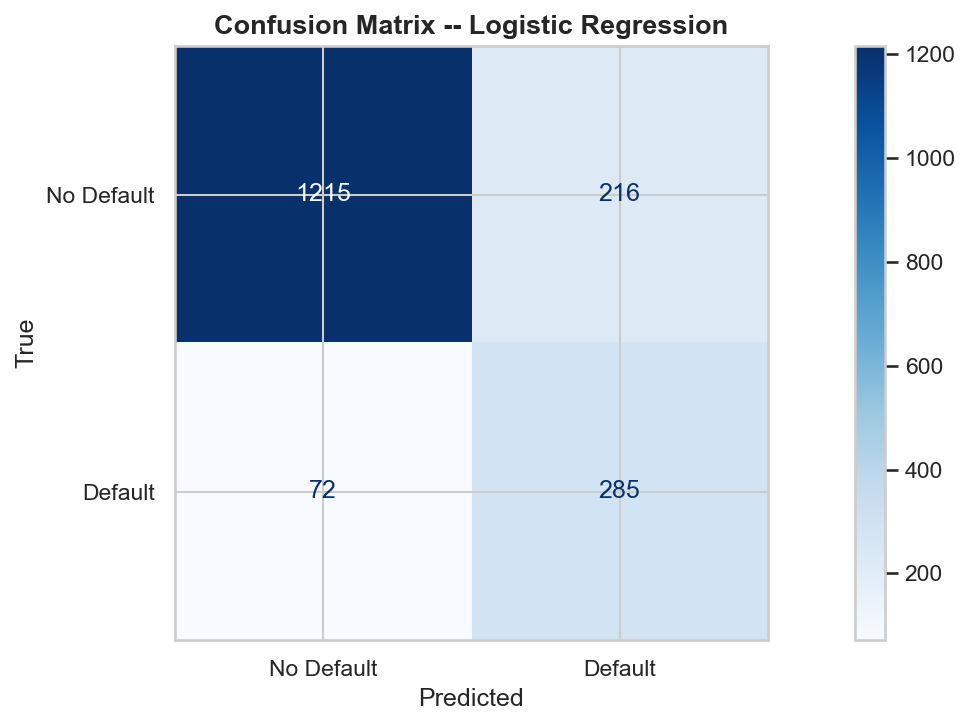

In [18]:
# Logistic Regression
lr = make_model_pipeline(LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42,
))
model = lr

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Logistic Regression")
print(classification_report(y_test, y_pred, target_names=["No Default", "Default"]))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_prob):.4f}")

y_pred_lr, y_prob_lr = y_pred, y_prob
show_confusion(y_test, y_pred_lr, "Confusion Matrix -- Logistic Regression")

#### Observations

Recall on the Default class is 0.80, meaning the model correctly identified 285 of 357 actual defaulters. The 72 missed cases are false negatives, which carry the highest cost in this problem.

The tradeoff is Precision at 0.57. When the model flags an applicant as a likely default, it is wrong about 43% of the time. That means more applicants get sent to manual review than actually needed. That is an acceptable cost given the asymmetry between a missed defaulter and an unnecessary review.

ROC-AUC of 0.88 and PR-AUC of 0.73 show solid overall ranking performance. Logistic Regression is a strong baseline and a legitimate contender on the primary metric.

---

### Decision Tree

Decision Tree
              precision    recall  f1-score   support

  No Default       0.91      0.93      0.92      1431
     Default       0.67      0.61      0.64       357

    accuracy                           0.86      1788
   macro avg       0.79      0.77      0.78      1788
weighted avg       0.86      0.86      0.86      1788

ROC-AUC : 0.7686
PR-AUC  : 0.4899


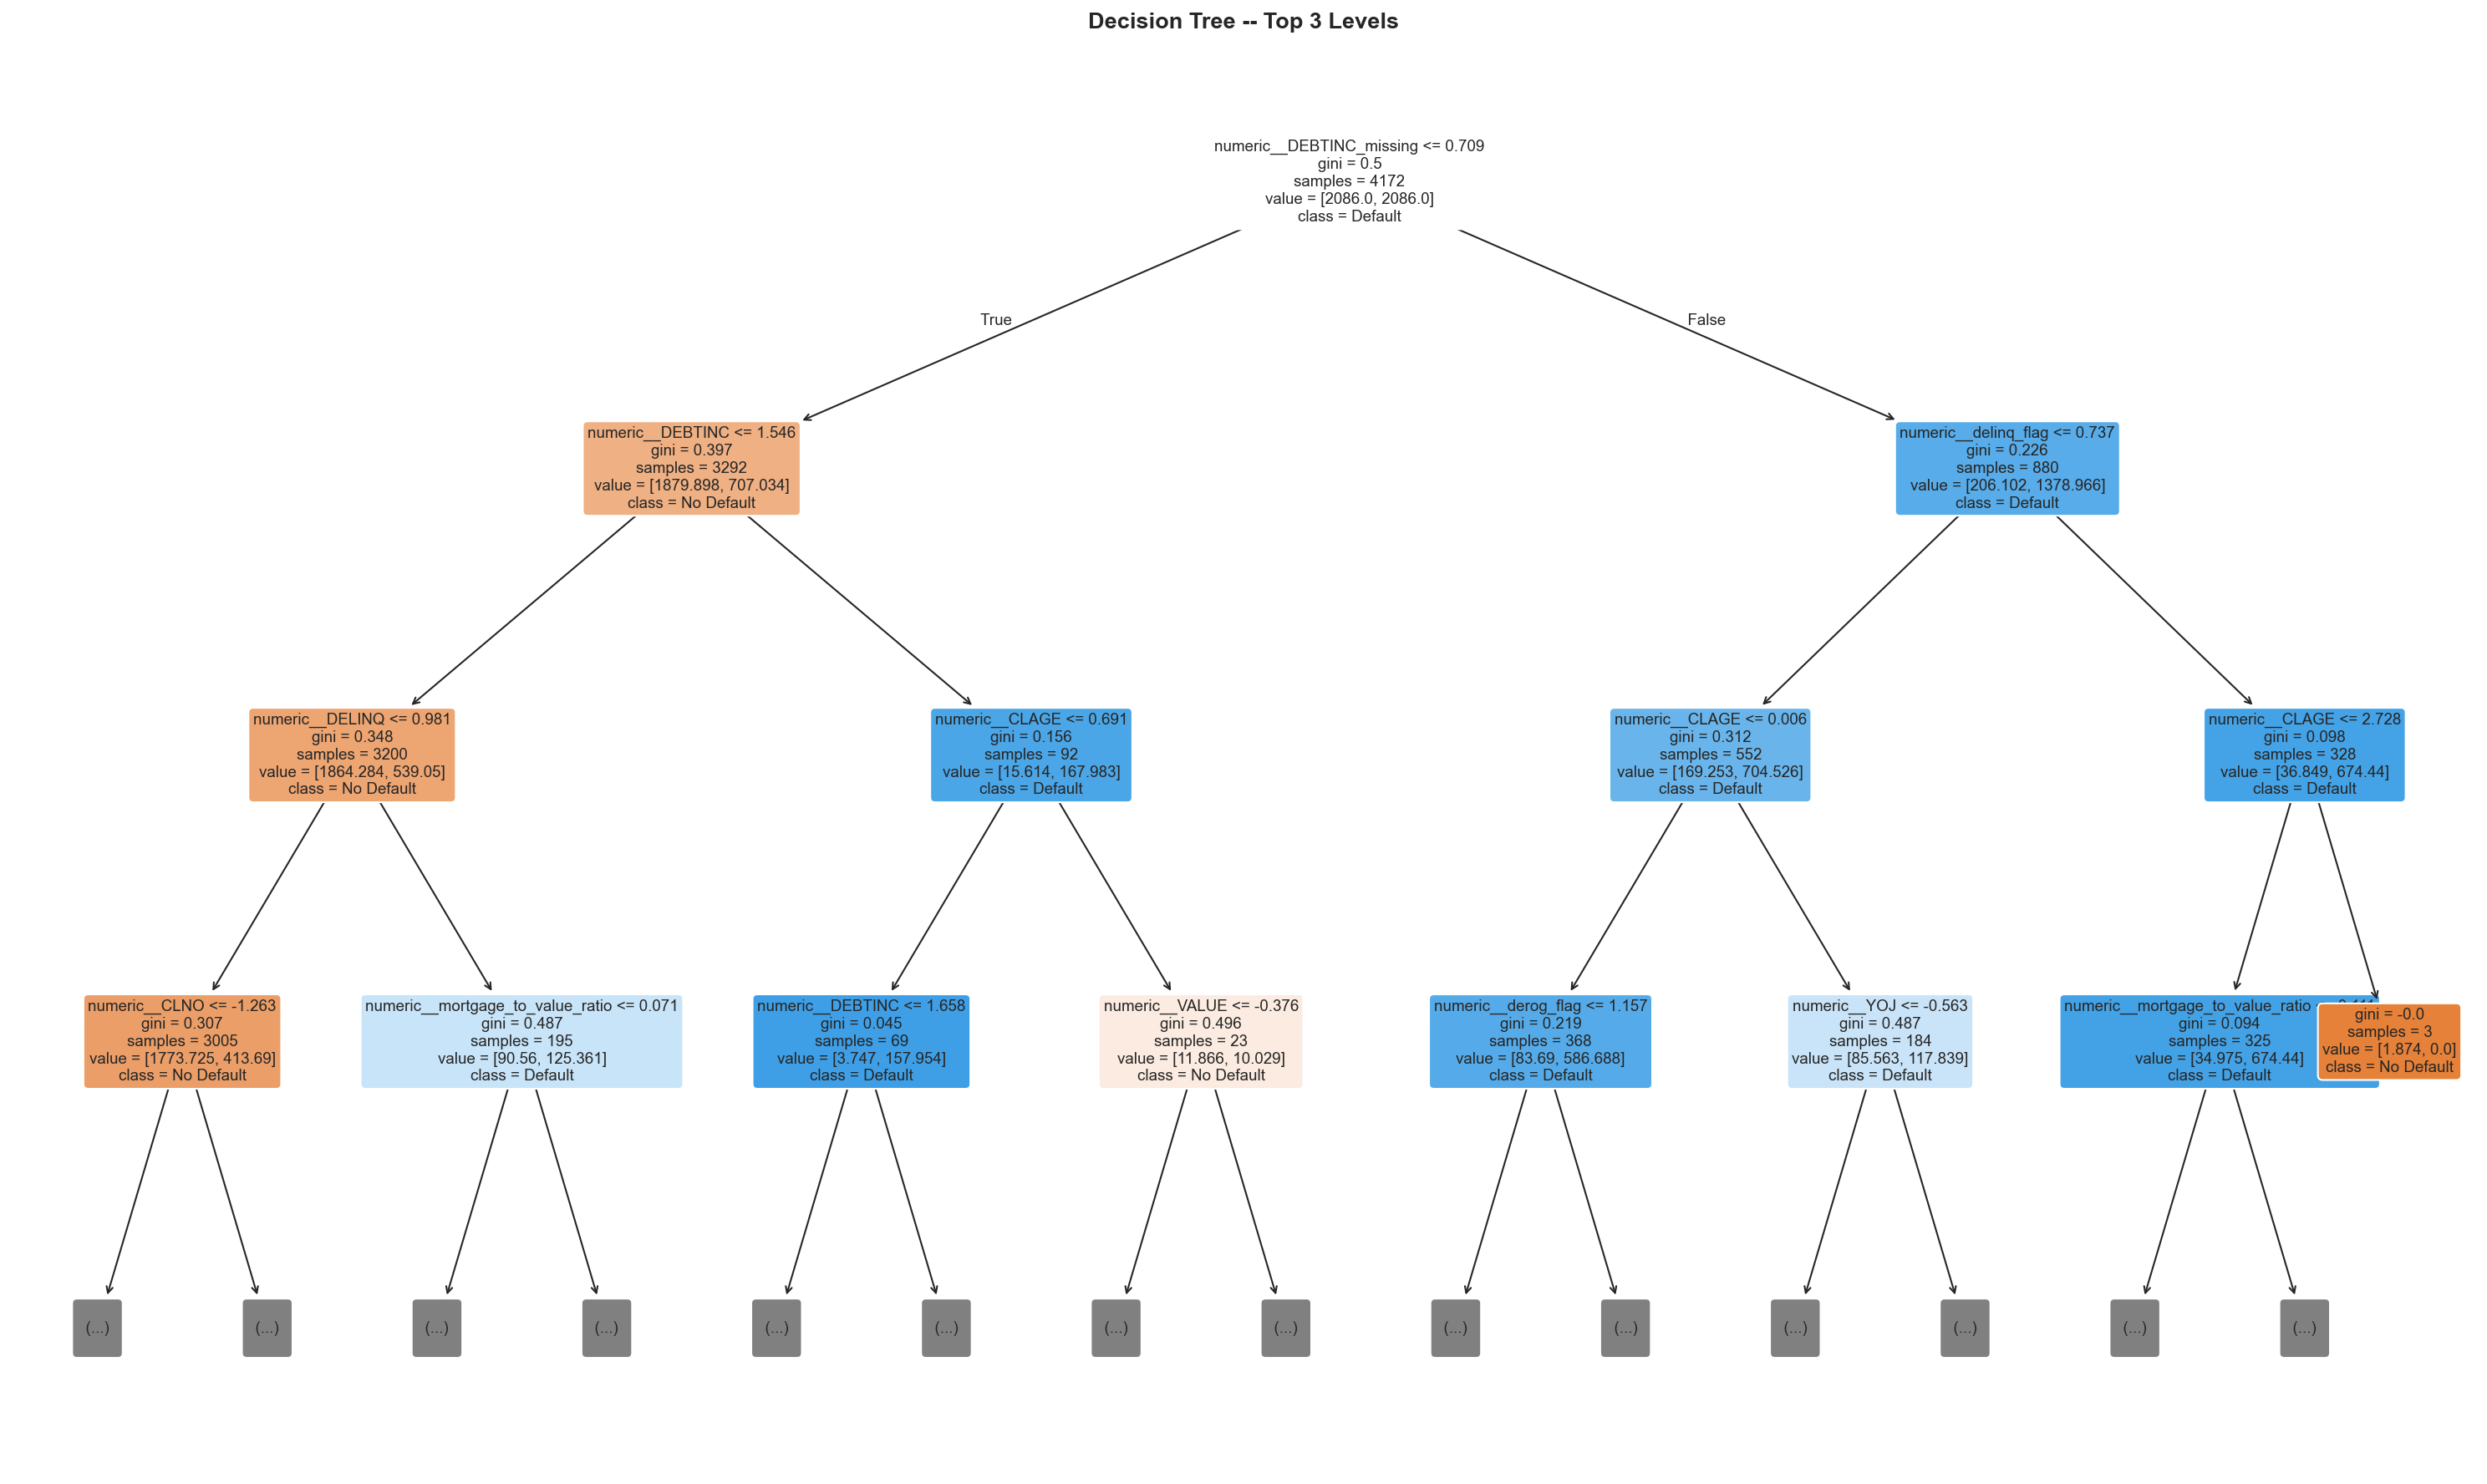

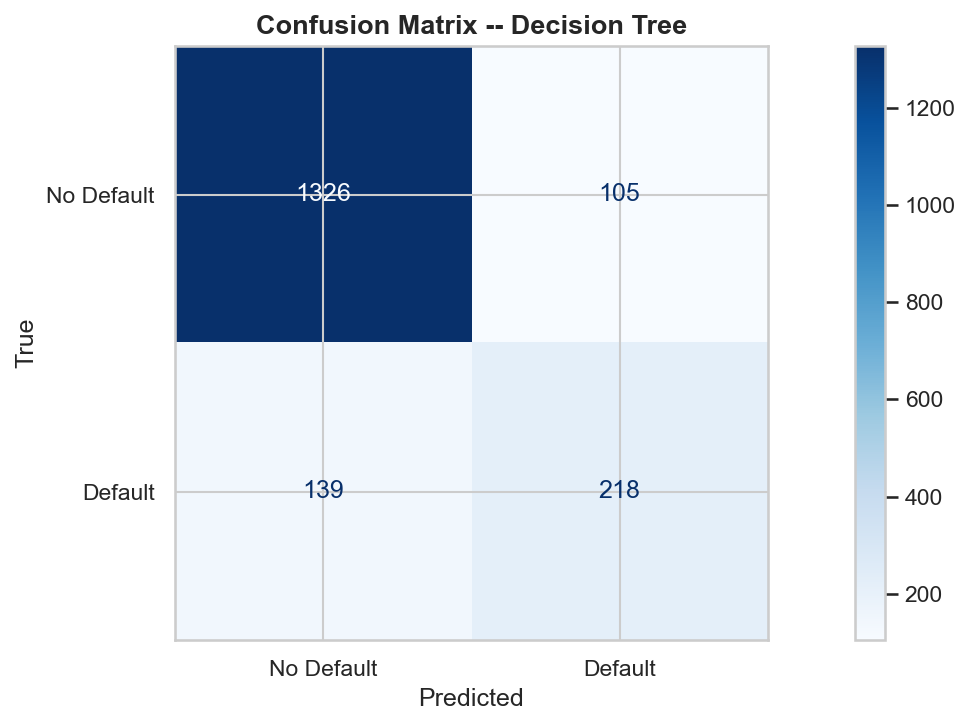

In [19]:
# Decision Tree
dt = make_model_pipeline(DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42,
))
model = dt

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Decision Tree")
print(classification_report(y_test, y_pred, target_names=["No Default", "Default"]))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_prob):.4f}")

y_pred_dt, y_prob_dt = y_pred, y_prob

tree_model = dt.named_steps["model"]
tree_features = dt.named_steps["preprocess"].get_feature_names_out()
plt.figure(figsize=(20, 12))
plot_tree(
    tree_model,
    max_depth=3,
    feature_names=tree_features,
    class_names=["No Default", "Default"],
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Decision Tree -- Top 3 Levels", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

show_confusion(y_test, y_pred_dt, "Confusion Matrix -- Decision Tree")

#### Observations

Recall on the Default class is 0.61, meaning the model correctly identified 218 of 357 actual defaulters and missed 139. That is the highest miss count of any model tested, which makes it the weakest option on the primary metric.

Precision is 0.67, so when the tree does flag an applicant as a likely default it is reasonably selective, but not selective enough to make up for the volume of missed cases.

ROC-AUC of 0.77 and PR-AUC of 0.49 are also the lowest of the group, meaning the model struggles to separate high-risk from low-risk applicants overall.

The tree visualization confirms something useful. The root split is on DEBTINC_missing, which confirms that the missing flag created in Section 5 is the single strongest signal in the dataset. That validation holds for every model that follows, even if the Decision Tree itself is not a strong final candidate.

---

### Random Forest

Random Forest
              precision    recall  f1-score   support

  No Default       0.91      0.96      0.94      1431
     Default       0.80      0.63      0.71       357

    accuracy                           0.89      1788
   macro avg       0.86      0.80      0.82      1788
weighted avg       0.89      0.89      0.89      1788

ROC-AUC : 0.9509
PR-AUC  : 0.8308


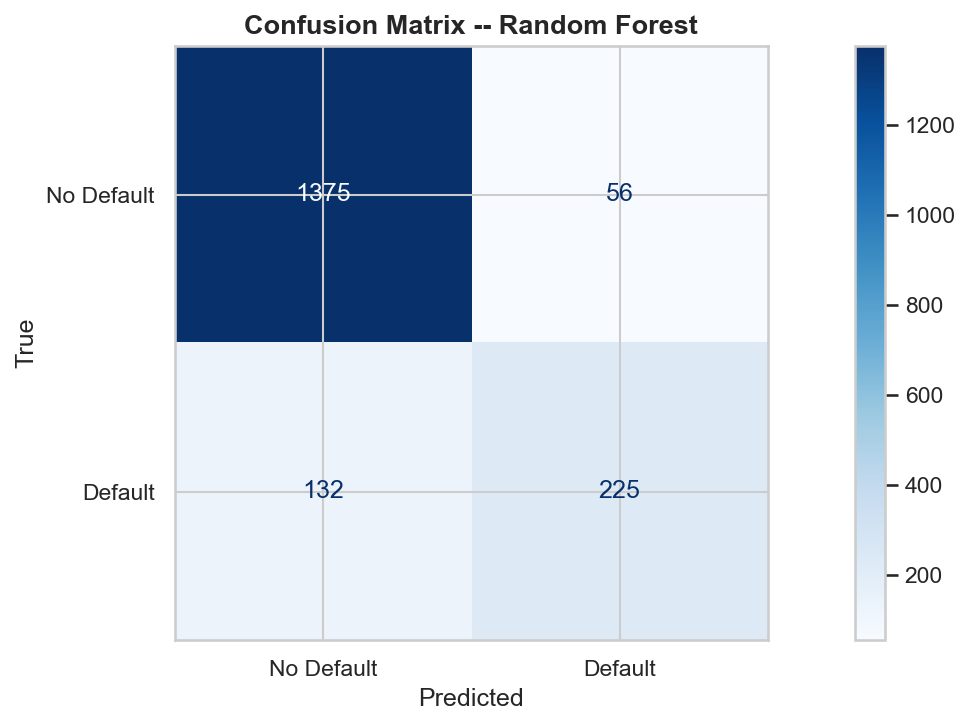

In [20]:
# Random Forest
rf = make_model_pipeline(RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
))
model = rf

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Random Forest")
print(classification_report(y_test, y_pred, target_names=["No Default", "Default"]))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_prob):.4f}")

y_pred_rf, y_prob_rf = y_pred, y_prob
show_confusion(y_test, y_pred_rf, "Confusion Matrix -- Random Forest")

#### Observations

Recall on the Default class is 0.63, meaning the model correctly identified 225 of 357 actual defaulters and missed 132. That is a meaningful improvement over a single Decision Tree, but it still leaves too many defaulters uncaught at the default threshold.

Precision is 0.80. When Random Forest flags an applicant as a likely default, it is usually right. The tradeoff is that it is conservative, so it flags fewer applicants overall and misses more of the ones that matter.

ROC-AUC of 0.95 and PR-AUC of 0.83 show that the model ranks applicants well. The issue is not the model's ability to separate risk, it is the 0.50 threshold. At that cutoff the model leans toward caution and sacrifices Recall in the process.

---

### Gradient Boosting

Gradient Boosting
              precision    recall  f1-score   support

  No Default       0.95      0.92      0.93      1431
     Default       0.70      0.79      0.74       357

    accuracy                           0.89      1788
   macro avg       0.82      0.85      0.84      1788
weighted avg       0.90      0.89      0.89      1788

ROC-AUC : 0.9334
PR-AUC  : 0.8240


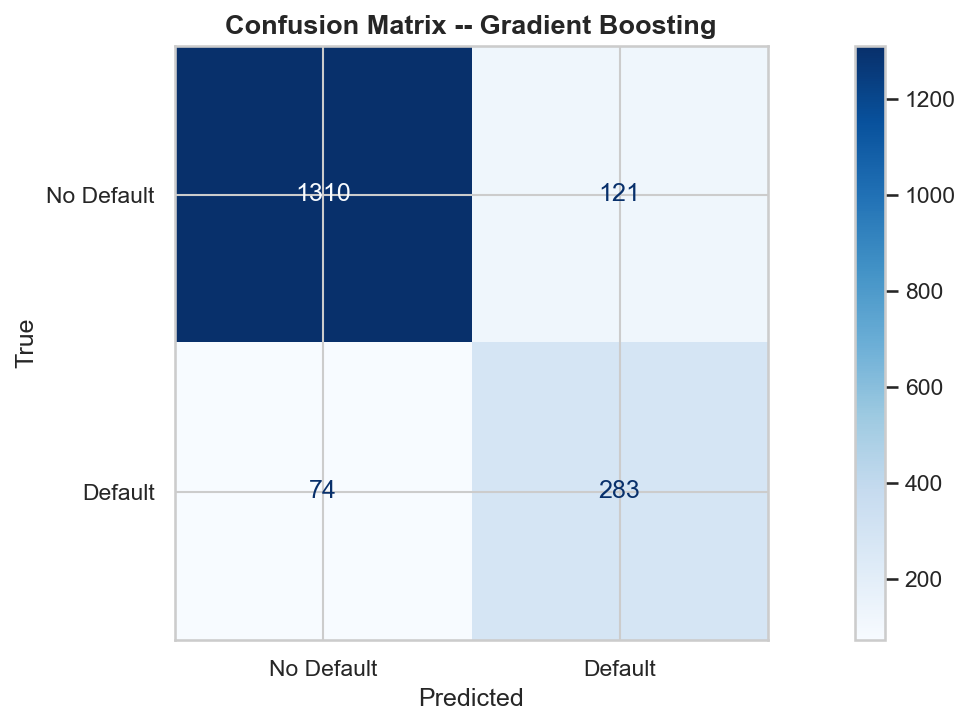

In [21]:
# Gradient Boosting -- sequential boosted tree ensemble
gb = make_model_pipeline(GradientBoostingClassifier(
    n_estimators=200,
    random_state=42,
))
gb_sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)
gb.fit(X_train, y_train, model__sample_weight=gb_sample_weights)

y_pred_gb = gb.predict(X_test)
y_prob_gb = gb.predict_proba(X_test)[:, 1]

print("Gradient Boosting")
print(classification_report(y_test, y_pred_gb, target_names=["No Default", "Default"]))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob_gb):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_prob_gb):.4f}")
show_confusion(y_test, y_pred_gb, "Confusion Matrix -- Gradient Boosting")

#### Observations

Recall on the Default class is 0.79, meaning the model correctly identified 283 of 357 actual defaulters and missed 74.

Precision is 0.70, which is a reasonable tradeoff. The model flags more applicants than Random Forest but catches more defaulters in return.

ROC-AUC of 0.93 and PR-AUC of 0.82 show strong overall ranking performance. At the baseline stage, Gradient Boosting sits just behind Logistic Regression on Recall but carries stronger Precision and ranking metrics. It remains a strong tuning candidate and the benchmark for the tree-based models.

---

### XGBoost

XGBoost
              precision    recall  f1-score   support

  No Default       0.94      0.96      0.95      1431
     Default       0.81      0.76      0.78       357

    accuracy                           0.92      1788
   macro avg       0.87      0.86      0.87      1788
weighted avg       0.91      0.92      0.92      1788

ROC-AUC : 0.9551
PR-AUC  : 0.8803


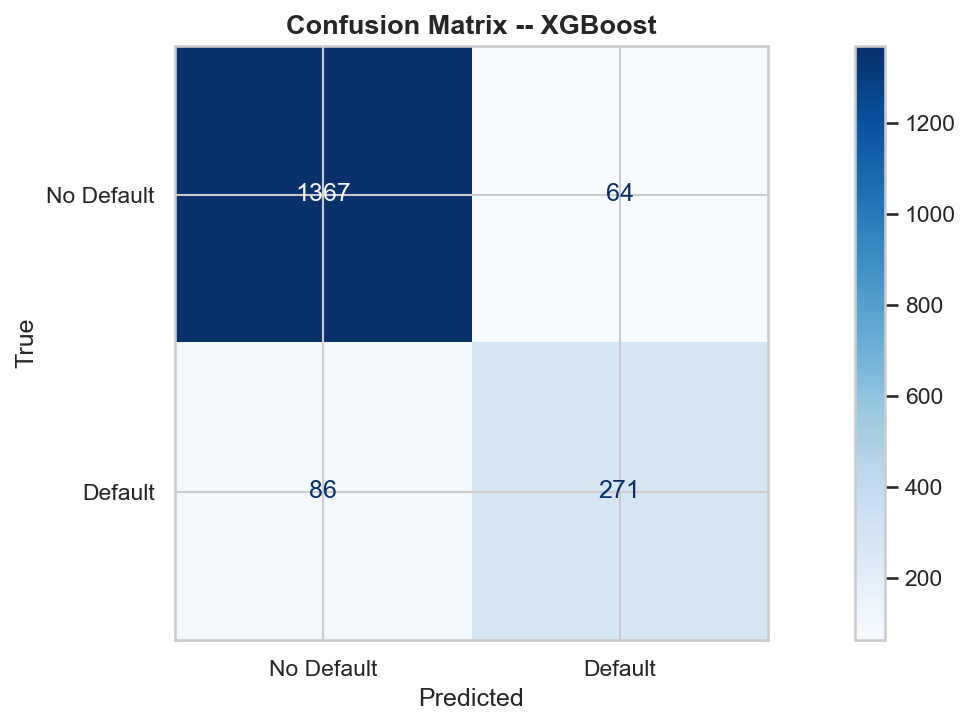

In [22]:
# XGBoost -- gradient boosting with built-in regularization
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos = neg / pos

xgb = make_model_pipeline(XGBClassifier(
    n_estimators=200,
    scale_pos_weight=scale_pos,
    tree_method="hist",
    random_state=42,
    eval_metric="logloss",
    verbosity=0,
))
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

print("XGBoost")
print(classification_report(y_test, y_pred_xgb, target_names=["No Default", "Default"]))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob_xgb):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_prob_xgb):.4f}")
show_confusion(y_test, y_pred_xgb, "Confusion Matrix -- XGBoost")

#### Observations

Recall on the Default class is 0.76, meaning the model correctly identified 271 of 357 actual defaulters and missed 86. That is lower than both Logistic Regression and Gradient Boosting at the baseline stage.

Where XGBoost stands out is Precision at 0.81 and overall ranking performance. ROC-AUC of 0.96 and PR-AUC of 0.88 are the strongest of any baseline model, meaning it does the best job of separating high-risk from low-risk applicants across all possible thresholds.

At the default 0.50 threshold, XGBoost is more conservative than the other models. It misses more defaulters but makes fewer unnecessary flags. Whether tuning can close that Recall gap while holding onto the strong precision and ranking performance is the key question heading into Section 8.

---

## 8. Model Evaluation & Selection

All five baseline models have been trained and scored. The results are put side by side 
here, tuning is run on the strongest tree-based candidates, and the final model 
is selected.

Recall remains the primary metric because missing an actual defaulter is the highest-cost 
error. However, the final decision cannot rely on Recall alone. Precision, F1, ROC-AUC, 
and PR-AUC are also reviewed to make sure the selected model is operationally useful and 
not just catching more defaulters by sending too many applicants to manual review.

Tuning uses `RandomizedSearchCV` scored on Recall with stratified 5-fold cross-validation. 
Random search covers large parameter spaces faster than grid search and is appropriate for 
this analysis. Model selection at this stage is based on the available baseline 
and tuned results, with the selected model carried forward into threshold tuning and 
explainability in the final notebook.

In [23]:
# Helper function to score any model consistently
# Returns a metrics dict given predictions and probabilities
def score_model(name, y_pred, y_prob):
    return {
        "Model":     name,
        "Recall":    recall_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "ROC-AUC":   roc_auc_score(y_test, y_prob),
        "PR-AUC":    average_precision_score(y_test, y_prob)
    }

def results_table(rows, title):
    df = pd.DataFrame(rows).set_index("Model").round(4)
    print(title)
    display(
        df.sort_values("Recall", ascending=False)
          .style.highlight_max(
              axis=0,
              props="background-color: #c6efce; color: #1a5c2e; font-weight: bold"
          )
          .format("{:.4f}")
    )
    return df

In [24]:
# Side-by-side baseline comparison for all five models
baseline_rows = [
    score_model("Logistic Regression", y_pred_lr,  y_prob_lr),
    score_model("Decision Tree",        y_pred_dt,  y_prob_dt),
    score_model("Random Forest",        y_pred_rf,  y_prob_rf),
    score_model("Gradient Boosting",    y_pred_gb,  y_prob_gb),
    score_model("XGBoost",              y_pred_xgb, y_prob_xgb)
]

results_df = results_table(baseline_rows, "Baseline Model Comparison")

Baseline Model Comparison


,Recall,Precision,F1,ROC-AUC,PR-AUC
Model,,,,,
Logistic Regression,0.7983,0.5689,0.6643,0.8819,0.7258
Gradient Boosting,0.7927,0.7005,0.7438,0.9334,0.8240
XGBoost,0.7591,0.8090,0.7832,0.9551,0.8803
Random Forest,0.6303,0.8007,0.7053,0.9509,0.8308
Decision Tree,0.6106,0.6749,0.6412,0.7686,0.4899


#### Observations

Logistic Regression leads on the primary metric with a Recall of 0.80, correctly identifying the largest share of actual defaulters at the baseline stage. The cost is Precision at 0.57, meaning it generates more false positives for every defaulter it catches.

Gradient Boosting sits just behind at 0.79 with much stronger Precision at 0.70 and better overall ranking metrics. It carries a better balance across all measures than Logistic Regression at the baseline stage.

XGBoost has the strongest overall ranking performance. ROC-AUC of 0.96 and PR-AUC of 0.88 are the best in the group. Its baseline Recall of 0.76 is lower than the top two, but those ranking numbers suggest there is room to close that gap through tuning.

Random Forest Recall of 0.63 means it is too conservative at the default threshold despite strong Precision at 0.80. Decision Tree is the weakest model across every metric and is not a viable final candidate.

Logistic Regression leads on raw Recall at baseline, but Gradient Boosting and XGBoost are the stronger tuning candidates given their better precision and ranking performance. Tuning will determine whether either can take the overall lead.

---

### Hyperparameter Tuning -- Random Forest

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best params: {'model__n_estimators': 500, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 5}
Best CV Recall: 0.7765

Tuned Random Forest -- Test Set
              precision    recall  f1-score   support

  No Default       0.94      0.88      0.91      1431
     Default       0.62      0.76      0.68       357

    accuracy                           0.86      1788
   macro avg       0.78      0.82      0.80      1788
weighted avg       0.87      0.86      0.86      1788

ROC-AUC : 0.8993
PR-AUC  : 0.7391


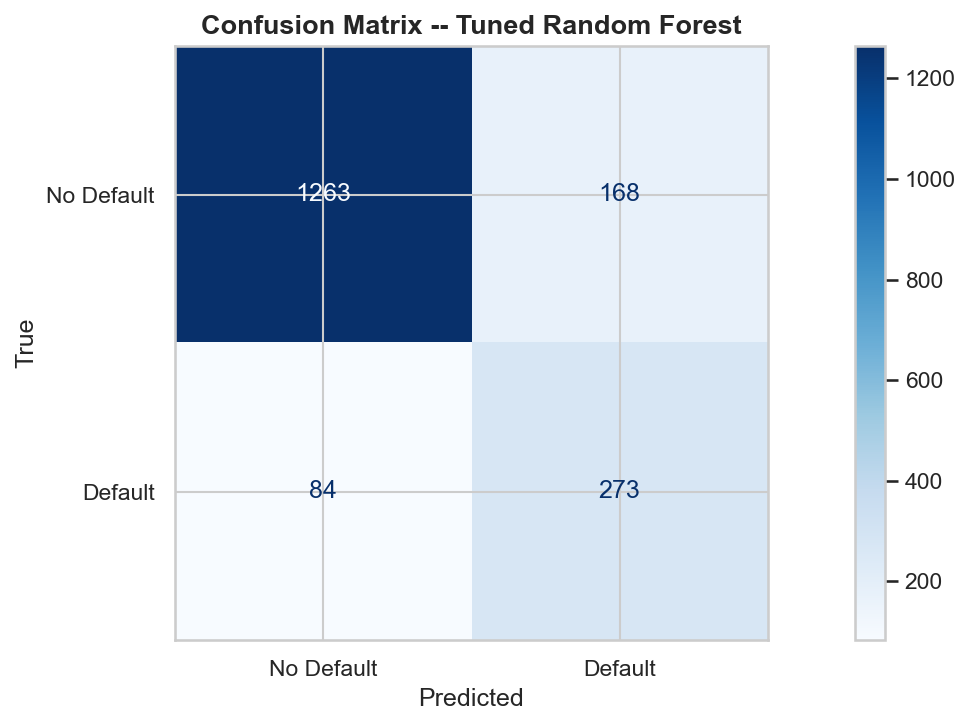

In [25]:
# Shared cross-validation strategy and scoring metric for tuning
recall_scorer = make_scorer(recall_score)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
}

rf_search = RandomizedSearchCV(
    estimator=make_model_pipeline(RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1,
    )),
    param_distributions=rf_param_grid,
    n_iter=40,
    scoring=recall_scorer,
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
rf_search.fit(X_train, y_train)

print(f"Best params: {rf_search.best_params_}")
print(f"Best CV Recall: {rf_search.best_score_:.4f}")

rf_tuned = rf_search.best_estimator_
y_pred_rf_t = rf_tuned.predict(X_test)
y_prob_rf_t = rf_tuned.predict_proba(X_test)[:, 1]

print("\nTuned Random Forest -- Test Set")
print(classification_report(y_test, y_pred_rf_t, target_names=["No Default", "Default"]))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob_rf_t):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_prob_rf_t):.4f}")
show_confusion(y_test, y_pred_rf_t, "Confusion Matrix -- Tuned Random Forest")

#### Observations

Tuning improved Recall from 0.63 to 0.76, correctly identifying 273 of 357 actual defaulters and missing 84. That is a 13-point gain over the baseline and a meaningful improvement, but it came with tradeoffs.

Precision dropped from 0.80 to 0.62, meaning the tuned model flags considerably more applicants as potential defaulters to achieve that Recall gain. ROC-AUC also dropped from 0.95 to 0.90 and PR-AUC from 0.83 to 0.74, so overall ranking quality weakened in exchange for better performance at the default threshold.

The best parameter set used 500 estimators, which was the upper limit of the search range. There may be marginal room to push further, but Random Forest is already trailing the stronger candidates and additional tuning is unlikely to change its standing.

---

### Hyperparameter Tuning -- Gradient Boosting

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best params: {'model__subsample': 1.0, 'model__n_estimators': 100, 'model__min_samples_leaf': 2, 'model__max_depth': 3, 'model__learning_rate': 0.2}
Best CV Recall: 0.8053

Tuned Gradient Boosting -- Test Set
              precision    recall  f1-score   support

  No Default       0.95      0.91      0.93      1431
     Default       0.69      0.79      0.74       357

    accuracy                           0.89      1788
   macro avg       0.82      0.85      0.83      1788
weighted avg       0.89      0.89      0.89      1788

ROC-AUC : 0.9310
PR-AUC  : 0.8179


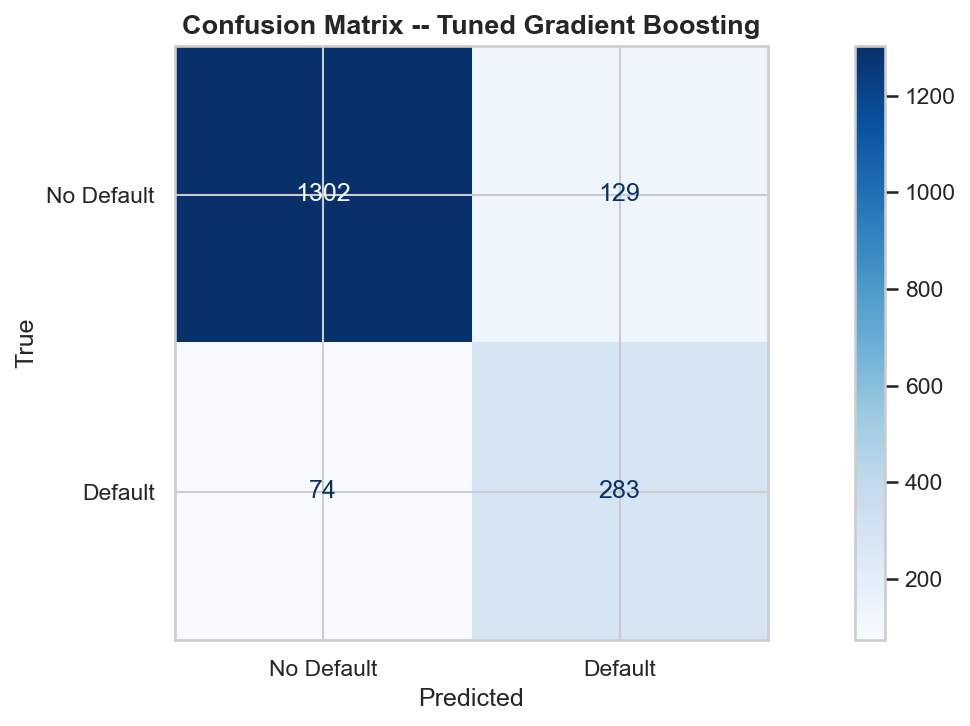

In [26]:
# Gradient Boosting tuning -- RandomizedSearchCV scored on Recall
gb_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "model__max_depth": [3, 4, 5, 6],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__min_samples_leaf": [1, 2, 5],
}

gb_search = RandomizedSearchCV(
    estimator=make_model_pipeline(GradientBoostingClassifier(random_state=42)),
    param_distributions=gb_param_grid,
    n_iter=40,
    scoring=recall_scorer,
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
)
gb_search.fit(X_train, y_train, model__sample_weight=gb_sample_weights)

print(f"Best params: {gb_search.best_params_}")
print(f"Best CV Recall: {gb_search.best_score_:.4f}")

gb_tuned = gb_search.best_estimator_
y_pred_gb_t = gb_tuned.predict(X_test)
y_prob_gb_t = gb_tuned.predict_proba(X_test)[:, 1]

print("\nTuned Gradient Boosting -- Test Set")
print(classification_report(y_test, y_pred_gb_t, target_names=["No Default", "Default"]))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob_gb_t):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_prob_gb_t):.4f}")
show_confusion(y_test, y_pred_gb_t, "Confusion Matrix -- Tuned Gradient Boosting")

#### Observations

Tuning produced no meaningful change. Recall held at 0.79, correctly identifying 283 of 357 actual defaulters and missing 74, identical to the baseline result. The model was already near its ceiling and the search confirmed it.

The best parameter set used 100 estimators, a learning rate of 0.2, and a max depth of 3. The lighter configuration reached the same performance as the 200-estimator baseline, which suggests the model is not particularly sensitive to these parameters within this range.

Gradient Boosting remains a strong model, but tuning created no separation from its baseline result. XGBoost is the last candidate to tune.

---

### Hyperparameter Tuning -- XGBoost

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best params: {'model__subsample': 0.8, 'model__reg_lambda': 1.5, 'model__reg_alpha': 1.0, 'model__n_estimators': 100, 'model__max_depth': 5, 'model__learning_rate': 0.2, 'model__colsample_bytree': 0.7}
Best CV Recall: 0.8053

Tuned XGBoost -- Test Set
              precision    recall  f1-score   support

  No Default       0.94      0.94      0.94      1431
     Default       0.75      0.76      0.75       357

    accuracy                           0.90      1788
   macro avg       0.85      0.85      0.85      1788
weighted avg       0.90      0.90      0.90      1788

ROC-AUC : 0.9482
PR-AUC  : 0.8531


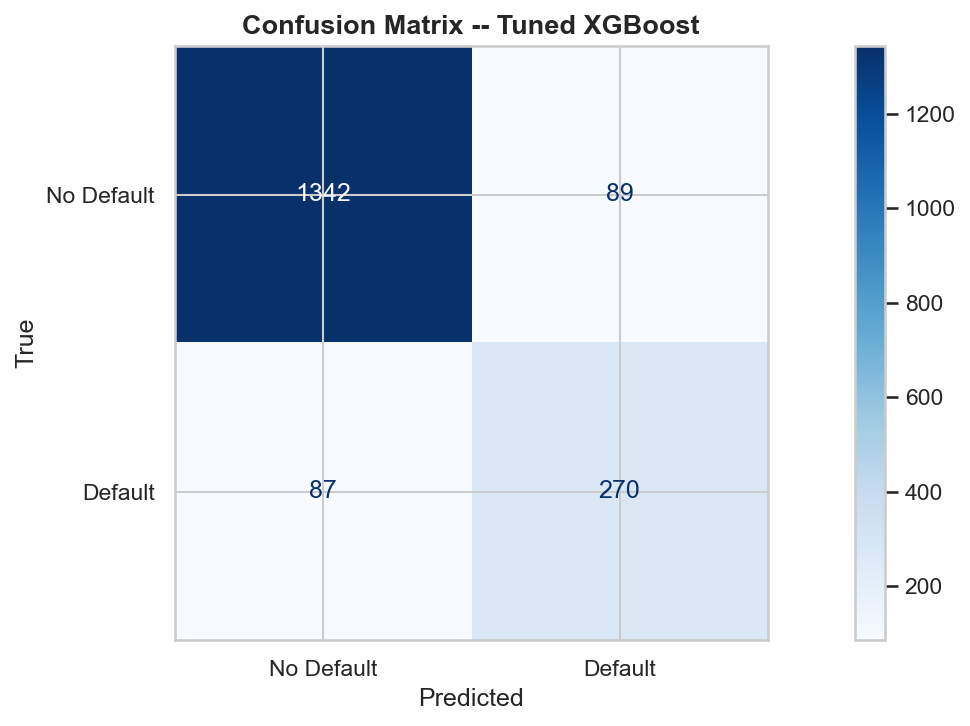

In [27]:
# XGBoost tuning -- RandomizedSearchCV scored on Recall
xgb_param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "model__max_depth": [3, 4, 5, 6],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 1.0],
    "model__reg_alpha": [0, 0.1, 0.5, 1.0],
    "model__reg_lambda": [1.0, 1.5, 2.0],
}

xgb_search = RandomizedSearchCV(
    estimator=make_model_pipeline(XGBClassifier(
        scale_pos_weight=scale_pos,
        tree_method="hist",
        random_state=42,
        eval_metric="logloss",
        verbosity=0,
    )),
    param_distributions=xgb_param_grid,
    n_iter=40,
    scoring=recall_scorer,
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
)

xgb_search.fit(X_train, y_train)

xgb_tuned = xgb_search.best_estimator_
y_pred_xgb_t = xgb_tuned.predict(X_test)
y_prob_xgb_t = xgb_tuned.predict_proba(X_test)[:, 1]

print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV Recall: {xgb_search.best_score_:.4f}")

print("\nTuned XGBoost -- Test Set")
print(classification_report(y_test, y_pred_xgb_t, target_names=["No Default", "Default"]))
print(f"ROC-AUC : {roc_auc_score(y_test, y_prob_xgb_t):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_prob_xgb_t):.4f}")
show_confusion(y_test, y_pred_xgb_t, "Confusion Matrix -- Tuned XGBoost")

#### Observations

Recall on the Default class is 0.76, correctly identifying 270 of 357 actual defaulters and missing 87. Precision improved to 0.75 over the baseline, and ROC-AUC of 0.95 and PR-AUC of 0.85 are the strongest ranking metrics of any tuned model.

The best parameter set used 100 estimators, well within the search range, confirming the search found a stable solution. The XGBoost tuned results are included in the final model selection comparison in the next section.

---

In [28]:
final_selection_rows = [
    score_model("Logistic Regression",  y_pred_lr,    y_prob_lr),
    score_model("Decision Tree",        y_pred_dt,    y_prob_dt),
    score_model("RF (baseline)",        y_pred_rf,    y_prob_rf),
    score_model("RF (tuned)",           y_pred_rf_t,  y_prob_rf_t),
    score_model("GB (baseline)",        y_pred_gb,    y_prob_gb),
    score_model("GB (tuned)",           y_pred_gb_t,  y_prob_gb_t),
    score_model("XGBoost (baseline)",   y_pred_xgb,   y_prob_xgb),
    score_model("XGBoost (tuned)",      y_pred_xgb_t, y_prob_xgb_t)
]

selection_df = results_table(
    final_selection_rows,
    "Final Model Selection Comparison"
)

# Select final model
final_model  = gb
y_pred_final = y_pred_gb
y_prob_final = y_prob_gb
final_name   = "Gradient Boosting (Baseline)"

print(f"\nFinal model selected: {final_name}")

Final Model Selection Comparison


,Recall,Precision,F1,ROC-AUC,PR-AUC
Model,,,,,
Logistic Regression,0.7983,0.5689,0.6643,0.8819,0.7258
GB (baseline),0.7927,0.7005,0.7438,0.9334,0.8240
GB (tuned),0.7927,0.6869,0.7360,0.9310,0.8179
RF (tuned),0.7647,0.6190,0.6842,0.8993,0.7391
XGBoost (baseline),0.7591,0.8090,0.7832,0.9551,0.8803
XGBoost (tuned),0.7563,0.7521,0.7542,0.9482,0.8531
RF (baseline),0.6303,0.8007,0.7053,0.9509,0.8308
Decision Tree,0.6106,0.6749,0.6412,0.7686,0.4899



Final model selected: Gradient Boosting (Baseline)


### Tuned Model Comparison

#### Observations

Logistic Regression has the highest raw Recall at 0.7983, correctly identifying 285 of 
357 actual defaulters. Gradient Boosting baseline is just behind at 0.7927, correctly 
identifying 283 of 357. That difference is only 2 defaulters across the full test set.

The reason Gradient Boosting is selected is the operating tradeoff. Logistic Regression 
catches 2 additional defaulters, but Precision is only 0.57, meaning 43% of flagged 
applicants would have repaid. Gradient Boosting has Precision of 0.70, meaning 30% of 
flagged applicants would have repaid. That is 13 percentage points fewer unnecessary 
reviews per flagged applicant, while giving up only 2 defaulters.

Tuning did not improve on the Gradient Boosting baseline. GB tuned matched baseline 
Recall exactly while losing Precision and ranking performance. XGBoost tuned produced 
lower Recall than its own baseline, making the tuning run a net negative on the primary 
metric. RF tuned improved over RF baseline but remained behind the top candidates.

XGBoost baseline has stronger Precision at 0.81, F1 at 0.78, ROC-AUC at 0.96, and 
PR-AUC at 0.88. The practical cost of choosing it over Gradient Boosting baseline is 12 
additional missed defaulters across the 1,788-record test set. At the average loan amount 
of roughly $18,600, those 12 missed defaults represent approximately $223,000 in 
additional at-risk exposure per test-set equivalent portfolio.

Gradient Boosting baseline is therefore the recommended final model. It gives up 
almost nothing to Logistic Regression on Recall, improves the review-list quality 
substantially, and catches more defaulters than XGBoost at the default threshold. 
Precision at 0.70 is operationally acceptable because the intended workflow is that every 
flagged applicant receives manual review with an explanation grounded in their financial 
profile.

---

#### Summary: Model Selection and Proposal

**Technique Comparison:** Five baseline models were evaluated and three tree-based
candidates were tuned. Logistic Regression had the highest raw Recall, while Gradient
Boosting baseline was within 2 defaulters of that result and produced a much stronger
Precision/Recall tradeoff. XGBoost had the strongest ranking metrics, but at the default
threshold it missed more defaulters than Gradient Boosting.

**Variable Significance:** The features that drove EDA insights continue to drive model
decisions post-modeling. The Decision Tree root split on `DEBTINC_missing` confirms it is
the single strongest predictor of default in the dataset. `CLAGE`, `DEBTINC`, `DELINQ`,
and `delinq_flag` are consistently important across all tree-based models. The engineered
features `derog_flag`, `delinq_flag`, and `mortgage_to_value_ratio` all contribute
meaningfully, confirming that the feature engineering decisions in Section 5 added
predictive value beyond the raw inputs. JOB and REASON remain weak standalone predictors
as identified in EDA, and their low feature importance post-modeling is consistent with
that finding.

**Feature Selection Approach:** Feature selection was addressed through the EDA and 
engineering process rather than post-modeling elimination. Features with weak standalone 
predictive power such as JOB and REASON were retained because tree-based models extract 
value from feature combinations that linear correlation does not capture. The Decision 
Tree root split on DEBTINC_missing and the consistent performance of the engineered 
features across all five models confirm the current feature set is contributing 
meaningfully. Section 10 examines individual feature contributions through SHAP analysis, 
which provides a post-modeling view of feature importance and identifies candidates for 
removal in future iterations.

**Key Insights:** Missing `DEBTINC` is one of the strongest default signals in the
dataset, with a 56-point missing-rate gap between defaulters and non-defaulters. Credit
history length, delinquency history, and debt burden are also important. Class imbalance
required explicit weighting across all models. Default risk is not driven by one field
alone; it is a combination of missingness, credit history, debt burden, and borrower
profile.

**Proposed Solution:** Gradient Boosting baseline is the recommended model for this project. It
provides the best balance on the primary objective: high Recall, stronger
Precision than Logistic Regression, and competitive ranking performance. At the current dataset
scale the pipeline is leakage-free, the preprocessing is
documented and reproducible, and every flagged applicant can receive a clear financial
explanation satisfying the ECOA requirement. The model flags for review, it does not make
the final credit decision. Sections 9 through 14 extend this model with threshold optimization,
individual-level explainability, risk tiering, and business recommendations.

**Scale Consideration:** GB baseline is the right choice for this dataset. In a larger or
more complex portfolio, XGBoost's superior ranking metrics (ROC-AUC 0.9551, PR-AUC 0.8803)
would likely make it the stronger operational deployment once threshold tuning is applied.
At production scale, ranking quality compounds; a model that better separates risk across
all thresholds gives underwriters more flexibility to tune the operating point without
sacrificing either Recall or Precision.

---

## 9. Threshold Tuning

The models in Section 7 all used a default classification threshold of 0.50. At that
cutoff, an applicant is flagged as a likely default only if the model assigns a
probability above 50%. That number is not special. It is just the default.

Lowering the threshold means more applicants get flagged. That catches more actual
defaulters but also increases the number of applicants sent to manual review who
would have repaid. The goal here is to find the threshold where that tradeoff makes
the most sense for this problem.

The final model is Gradient Boosting baseline. The threshold analysis is run on that model only.

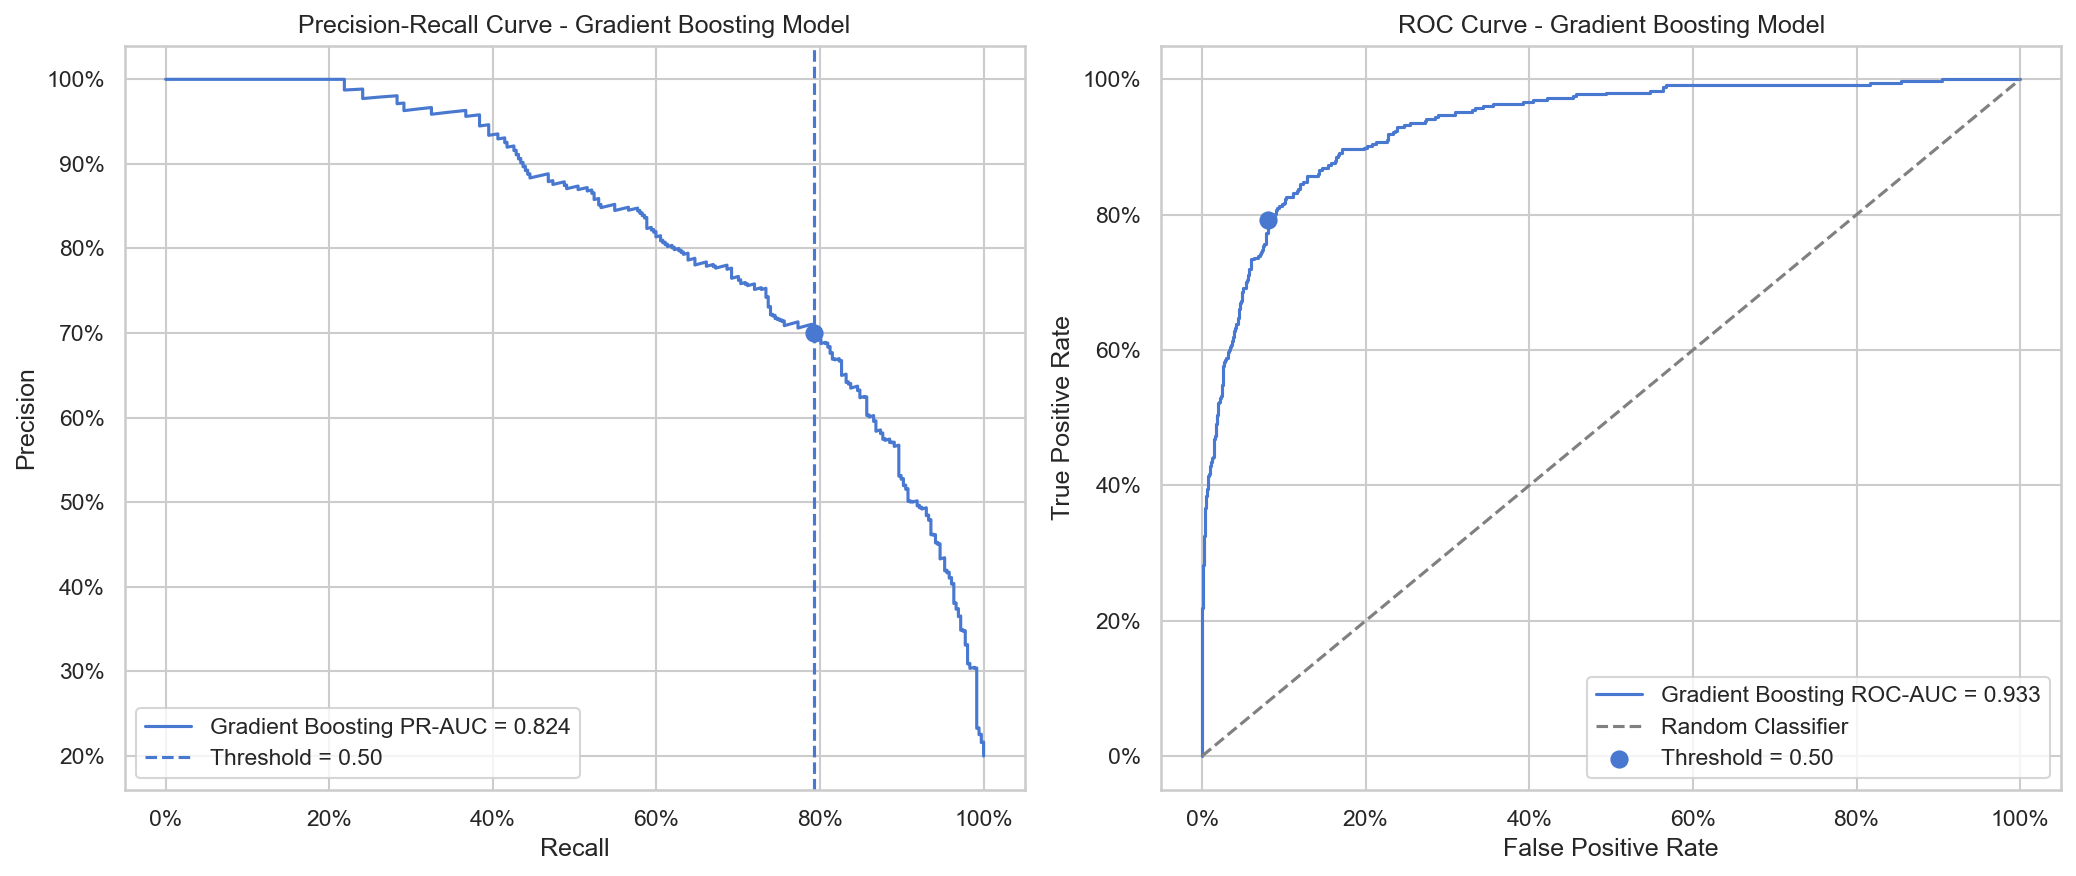

In [29]:
# Generate curve values using predicted probabilities from the final model
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_prob_final)
fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob_final)

# Calculate summary metrics
pr_auc = average_precision_score(y_test, y_prob_final)
roc_auc = roc_auc_score(y_test, y_prob_final)

# Identify the point closest to the current classification threshold of 0.50
current_threshold = 0.50
closest_pr_idx = np.argmin(np.abs(pr_thresholds - current_threshold))
closest_roc_idx = np.argmin(np.abs(roc_thresholds - current_threshold))

# Plot Precision-Recall and ROC curves side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Precision-Recall Curve
axes[0].plot(
    recall,
    precision,
    label=f'Gradient Boosting PR-AUC = {pr_auc:.3f}'
)

axes[0].axvline(
    x=recall[closest_pr_idx],
    linestyle='--',
    label='Threshold = 0.50'
)

axes[0].scatter(
    recall[closest_pr_idx],
    precision[closest_pr_idx],
    s=60
)

axes[0].set_title('Precision-Recall Curve - Gradient Boosting Model')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].legend(loc='lower left')
axes[0].grid(True)

# ROC Curve
axes[1].plot(
    fpr,
    tpr,
    label=f'Gradient Boosting ROC-AUC = {roc_auc:.3f}'
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='grey',
    label='Random Classifier'
)

axes[1].scatter(
    fpr[closest_roc_idx],
    tpr[closest_roc_idx],
    s=60,
    label='Threshold = 0.50'
)

axes[1].set_title('ROC Curve - Gradient Boosting Model')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### Observations

Both curves confirm the model is in strong territory at the 0.50 threshold. On the
Precision-Recall curve, the operating point sits at roughly 79% Recall and 70% Precision.
The curve to the right drops off gradually, meaning additional Recall is available at a
measured cost to Precision.

The ROC curve tells a consistent story. At 0.50 the model achieves 79% True Positive Rate
with approximately 8% False Positive Rate, well above the random classifier line. The
sharp rise in the upper left confirms strong separation between high-risk and low-risk
applicants.

---

In [30]:
# Define the threshold range to evaluate
thresholds = np.arange(0.20, 0.60, 0.01)

# Define the minimum acceptable precision level
precision_floor = 0.65

# Store threshold results
threshold_results = []

for threshold in thresholds:
    
    # Convert probabilities into class predictions using the current threshold
    y_pred_threshold = (y_prob_final >= threshold).astype(int)
    
    # Calculate performance metrics at the current threshold
    recall = recall_score(y_test, y_pred_threshold)
    precision = precision_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)
    
    # Store results
    threshold_results.append({
        'Threshold': threshold,
        'Recall': recall,
        'Precision': precision,
        'F1 Score': f1
    })

# Convert results to a DataFrame
threshold_df = pd.DataFrame(threshold_results)

# Sort results by threshold
threshold_df = threshold_df.sort_values(by='Threshold').reset_index(drop=True)

# Identify the best threshold:
# Maximize Recall while keeping Precision at or above the defined floor
eligible_thresholds = threshold_df[threshold_df['Precision'] >= precision_floor]

optimal_threshold_row = eligible_thresholds.sort_values(
    by=['Recall', 'Precision'],
    ascending=[False, False]
).iloc[0]

optimal_threshold = optimal_threshold_row['Threshold']

# Display the optimal threshold and its metrics
print(f"Optimal Threshold: {optimal_threshold:.2f}")
print(f"Recall: {optimal_threshold_row['Recall']:.3f}")
print(f"Precision: {optimal_threshold_row['Precision']:.3f}")
print(f"F1 Score: {optimal_threshold_row['F1 Score']:.3f}")

print(f"Eligible Thresholds (Precision >= {precision_floor})")
optimal_idx = eligible_thresholds.sort_values('Threshold').reset_index(drop=True)
optimal_pos = optimal_idx[optimal_idx['Threshold'].round(2) == round(optimal_threshold, 2)].index[0]
optimal_idx.iloc[max(0, optimal_pos - 4): optimal_pos + 6].reset_index(drop=True)

Optimal Threshold: 0.41
Recall: 0.826
Precision: 0.667
F1 Score: 0.738
Eligible Thresholds (Precision >= 0.65)


,Threshold,Recall,Precision,F1 Score
0,0.40,0.83,0.65,0.73
1,0.41,0.83,0.67,0.74
2,0.42,0.82,0.67,0.74
3,0.43,0.81,0.68,0.74
4,0.44,0.81,0.68,0.74
5,0.45,0.81,0.68,0.74
6,0.46,0.81,0.69,0.74


#### Observations

The sweep evaluated thresholds from 0.20 to 0.60 against a Precision floor of 0.65.
The optimal threshold is 0.41, which maximizes Recall at 82.6% while keeping Precision
at 66.7%, just above the floor.

Lowering the threshold from 0.50 to 0.41 trades a modest drop in Precision for a
meaningful gain in Recall. Any reduction in missed defaulters reduces credit losses
directly. The cost of a false positive is one additional manual review, which is
acceptable given the asymmetry between the two error types. At 66.7% Precision the model
still dramatically outperforms manual review of all applications, and provides a
defensible baseline for further automation as richer data becomes available.

---

Classification Report at Tuned Threshold: 0.41
              precision    recall  f1-score   support

  No Default       0.95      0.90      0.92      1431
     Default       0.67      0.83      0.74       357

    accuracy                           0.88      1788
   macro avg       0.81      0.86      0.83      1788
weighted avg       0.90      0.88      0.89      1788



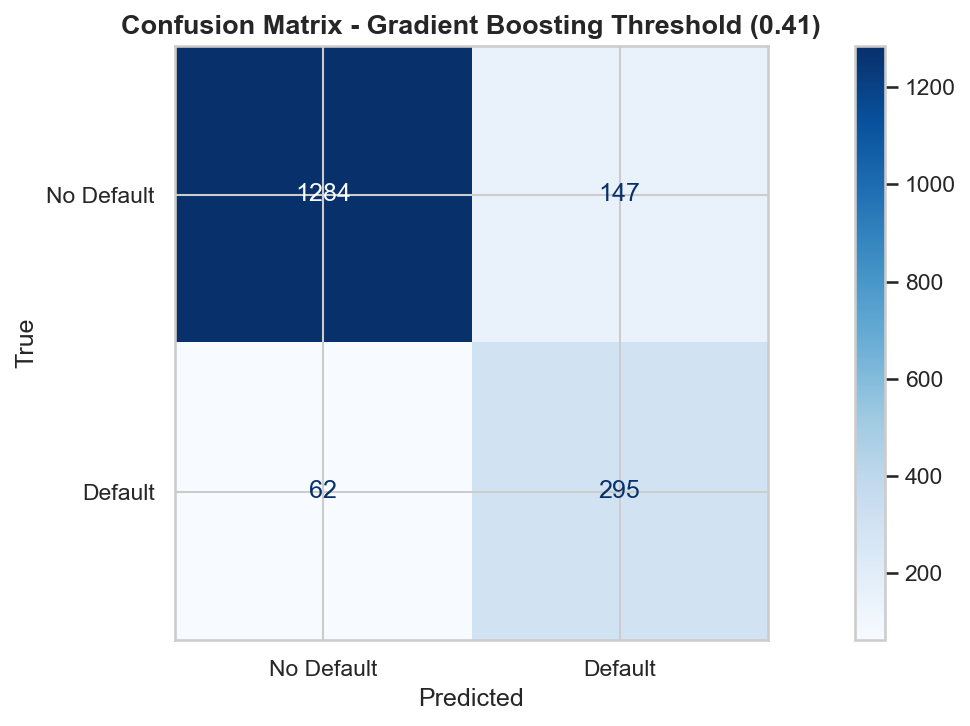

Threshold Performance Comparison


,Threshold,Recall,Precision,F1 Score
0,Default Threshold (0.50),79.3%,70.0%,74.4%
1,Tuned Threshold (0.41),82.6%,66.7%,73.8%


In [31]:
# Define the selected threshold based on threshold tuning
selected_threshold = 0.41

# Apply the selected tuned threshold
y_pred_tuned = (y_prob_final >= selected_threshold).astype(int)

# Print classification report for the tuned threshold
print(f"Classification Report at Tuned Threshold: {selected_threshold:.2f}")
print(classification_report(y_test, y_pred_tuned, target_names=["No Default", "Default"]))

# Show confusion matrix for the tuned threshold
show_confusion(
    y_test, 
    y_pred_tuned, 
    title=f"Confusion Matrix - Gradient Boosting Threshold ({selected_threshold:.2f})"
)

# Generate predictions using the default 0.50 threshold
y_pred_default = (y_prob_final >= 0.50).astype(int)

# Create side-by-side performance comparison
threshold_comparison = pd.DataFrame({
    'Threshold': [
        'Default Threshold (0.50)',
        f'Tuned Threshold ({selected_threshold:.2f})'
    ],
    'Recall': [
        recall_score(y_test, y_pred_default),
        recall_score(y_test, y_pred_tuned)
    ],
    'Precision': [
        precision_score(y_test, y_pred_default, zero_division=0),
        precision_score(y_test, y_pred_tuned, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_default),
        f1_score(y_test, y_pred_tuned)
    ]
})

# Format results as percentages for readability
threshold_comparison_display = threshold_comparison.copy()

for col in ['Recall', 'Precision', 'F1 Score']:
    threshold_comparison_display[col] = threshold_comparison_display[col].apply(lambda x: f'{x:.1%}')

print("Threshold Performance Comparison")
display(threshold_comparison_display)

#### Observations

Lowering the threshold from 0.50 to 0.41 catches 295 of 357 actual defaulters, up from
283. That is 12 additional defaults identified. At the average loan amount of roughly
$18,600, those 12 cases represent approximately $223,000 in additional avoided exposure
per test-set equivalent portfolio.

The cost is 26 additional false positives, bringing the total flagged for manual review
from 404 to 442. Each false positive is one additional underwriting review. That tradeoff
is operationally acceptable; any reduction in credit losses justifies a modest increase
in review volume, and the model still reduces manual review workload dramatically
compared to evaluating every application by hand.

All downstream analysis uses the 0.41 threshold.

In [32]:
# Reassign final predictions using the selected tuned threshold
y_pred_final = (y_prob_final >= selected_threshold).astype(int)

print(f"y_pred_final has been updated using the tuned threshold of {selected_threshold:.2f}.")

y_pred_final has been updated using the tuned threshold of 0.41.


---

## 10. Feature Importance & Explainability

Knowing the model performs well is not enough in this context. Under the Equal Credit
Opportunity Act, any adverse credit decision must be tied to specific, objective financial
factors. A model that cannot explain its decisions would not satisfy that requirement,
regardless of how accurate it is.

This section uses SHAP (SHapley Additive exPlanations) to examine what the model is
actually doing: first at a global level across all predictions, then at the individual
level for a specific flagged applicant. The individual explanation is what a loan officer
would use to justify a high-risk flag to the applicant.

In [33]:
# Extract the fitted GB model from the pipeline for SHAP
gb_model = final_model.named_steps['model']

# Transform X_test through the full pipeline minus the final model step
# This ensures CreditFeatureBuilder, IQRCapper, Log1pTransformer,
# imputation, scaling, and encoding are all applied correctly
pipeline_without_model = Pipeline(
    final_model.steps[:-1]
)

X_test_transformed = pipeline_without_model.transform(X_test)

# Retrieve feature names from the preprocessor step
feature_names = final_model.named_steps['preprocess'].get_feature_names_out()

# Convert to DataFrame for interpretability
X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print("Gradient Boosting model, transformed test data, and feature names extracted successfully.")
print(f"Model used: {final_name}")
print(f"Transformed test data shape: {X_test_transformed_df.shape}")

Gradient Boosting model, transformed test data, and feature names extracted successfully.
Model used: Gradient Boosting (Baseline)
Transformed test data shape: (1788, 20)


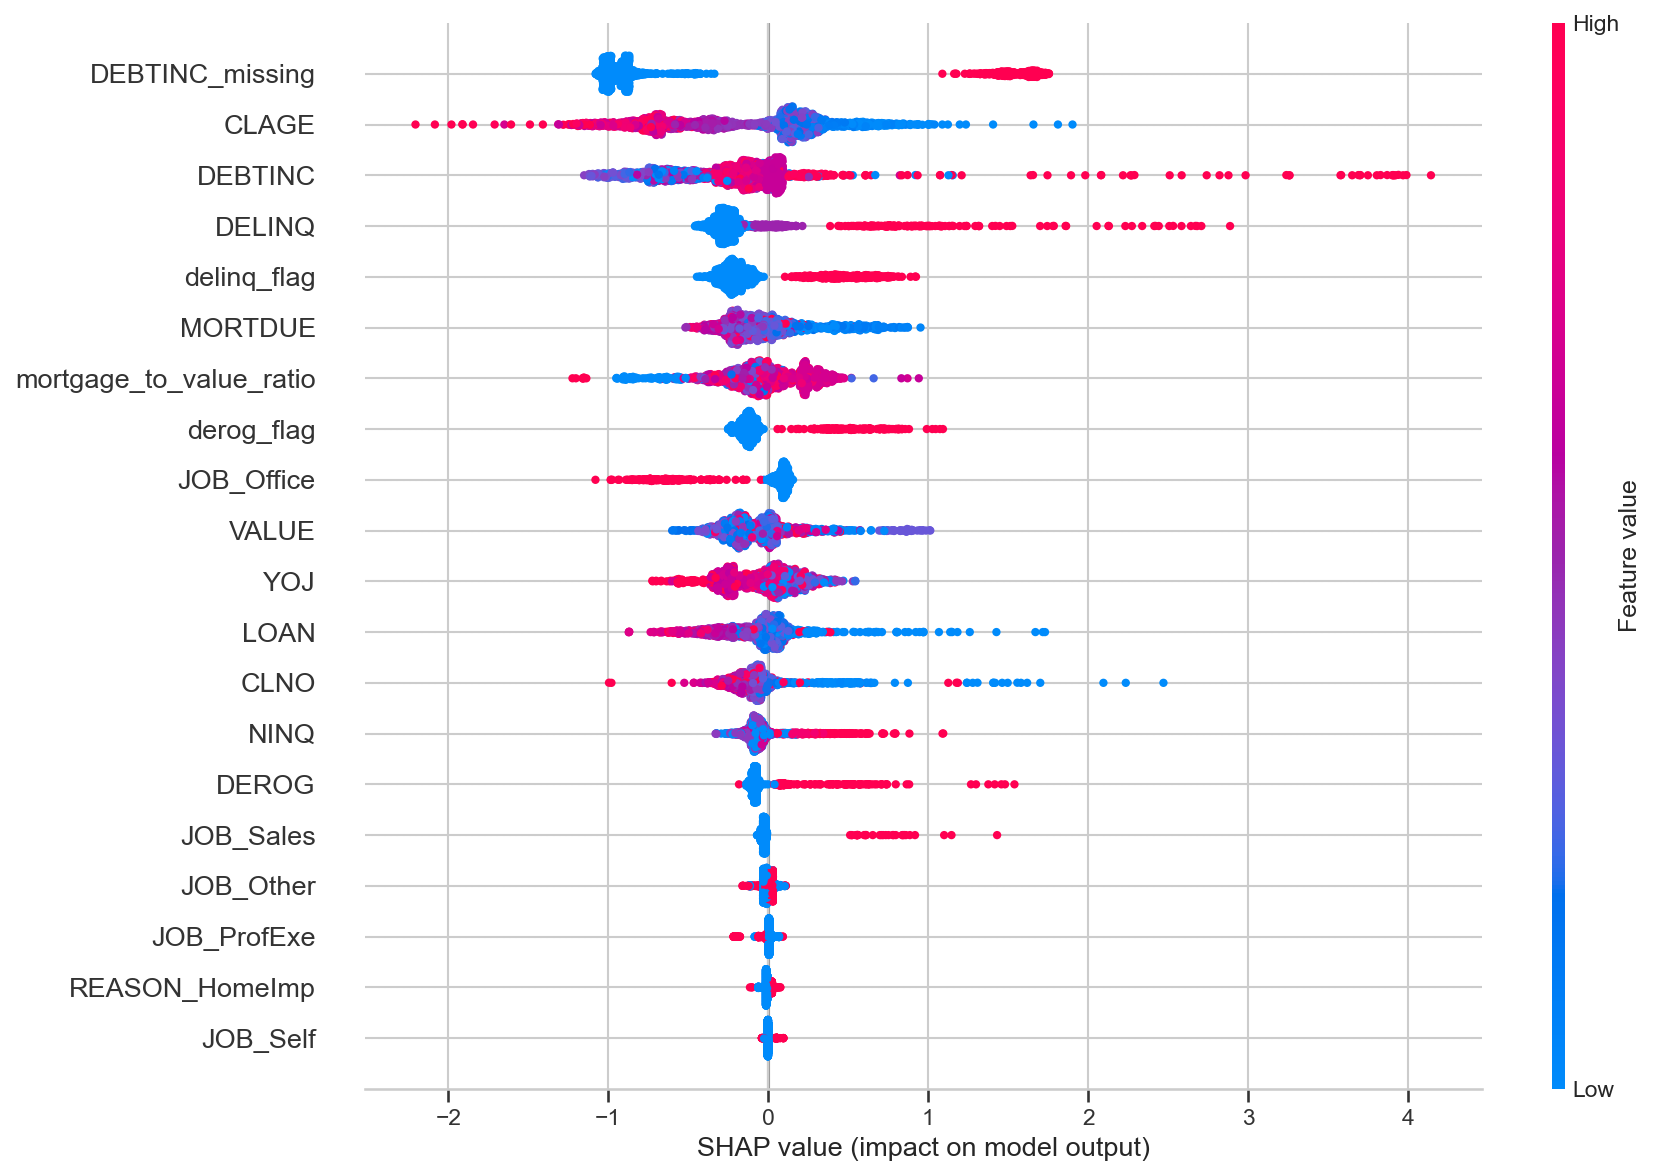

In [34]:
# Clean feature names for readability in the SHAP plot
feature_names_clean = [
    f.replace('numeric__', '').replace('categorical__', '') 
    for f in feature_names
]

# Build SHAP explainer for the fitted Gradient Boosting model
explainer = shap.TreeExplainer(gb_model)

# Calculate SHAP values on the transformed test data
shap_values = explainer.shap_values(X_test_transformed_df)

# Plot SHAP summary plot
shap.summary_plot(
    shap_values,
    X_test_transformed_df,
    feature_names=feature_names_clean,
    plot_size=(12, 8),
    show=False
)

plt.tight_layout()
plt.show()

#### Observations

`DEBTINC_missing` is the single most influential feature with a mean absolute SHAP value
of 1.066, nearly twice the next ranked feature. High values, meaning DEBTINC was missing
at application time, consistently push the model toward a default prediction. This
validates the feature engineering decision in Section 5; the absence of debt-to-income
data is itself a strong credit risk signal.

`CLAGE` ranks second at 0.445. Low credit line age pushes toward default, high credit
line age pushes away. The directional pattern is clean and consistent across applicants.

`DEBTINC` ranks third at 0.387. When present, high debt-to-income ratios drive default
predictions, with some extreme values extending SHAP contributions above 4.0.

`DELINQ` and `delinq_flag` both appear in the top five at 0.318 and 0.266 respectively,
confirming that the raw delinquency count and the binary flag each contribute
independently. The same pattern holds for `derog_flag` at 0.178 and `DEROG` at 0.110.

`mortgage_to_value_ratio` ranks sixth at 0.197, confirming the engineered ratio adds
signal beyond what `MORTDUE` and `VALUE` provide individually.

JOB and REASON categories sit at the bottom of the ranking, consistent with the weak
standalone separation observed in Section 4. Their value is in combination with credit
history features, not independently.

---

### Individual Applicant Explanation

Selected applicant position in test set: 303
Predicted default probability: 0.999
Classification threshold used: 0.41


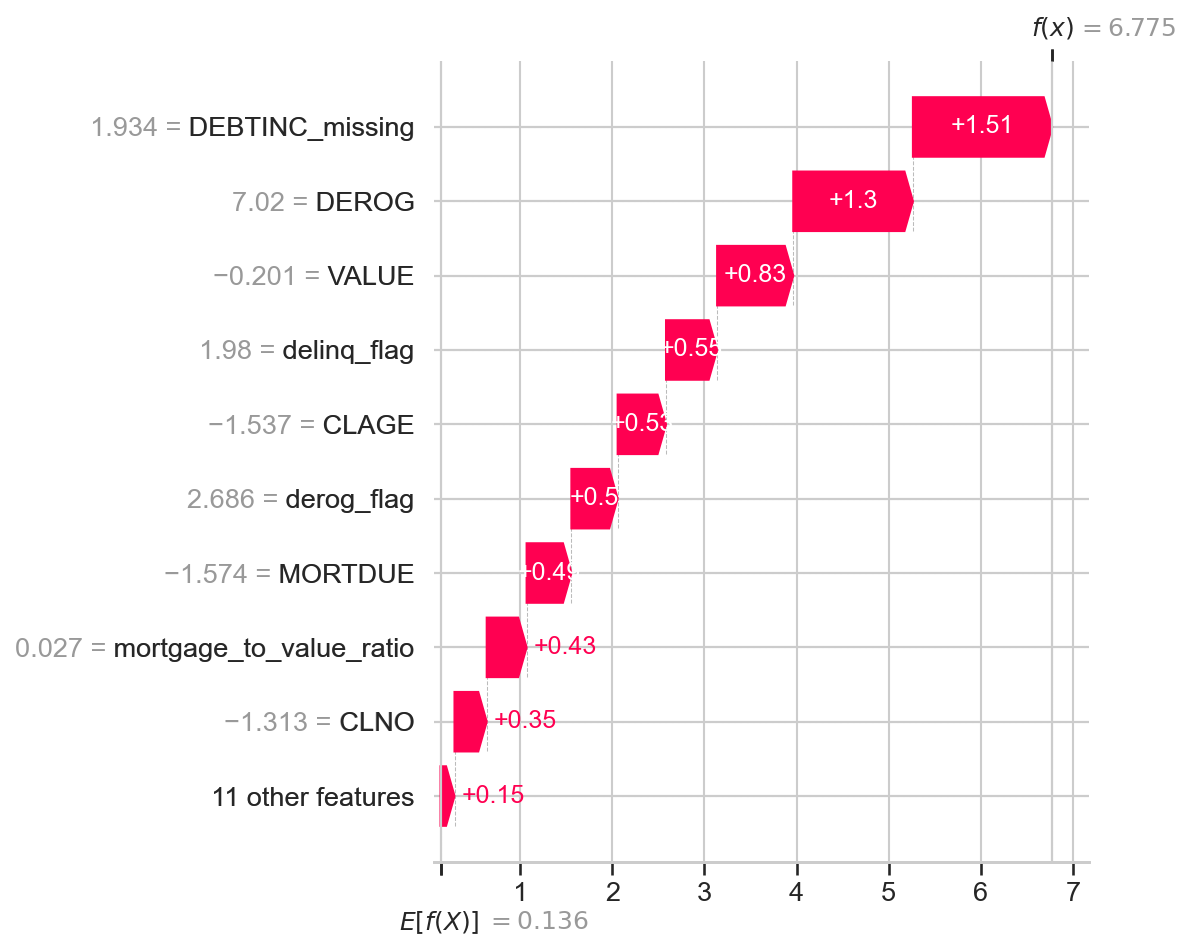

Flagged Applicant -- Raw Feature Profile


,Value
LOAN,31500
MORTDUE,15391.00
VALUE,NaN
REASON,HomeImp
JOB,NaN
YOJ,2.60
DEROG,6.00
DELINQ,1.00
CLAGE,57.83
NINQ,0.00


In [35]:
# Select a flagged high-risk applicant

# Find applicants flagged as high risk at the tuned threshold
flagged_idx = np.where(y_pred_final == 1)[0]

# Select the flagged applicant with the highest predicted default probability
top_risk_idx = flagged_idx[np.argmax(y_prob_final[flagged_idx])]

print(f"Selected applicant position in test set: {top_risk_idx}")
print(f"Predicted default probability: {y_prob_final[top_risk_idx]:.3f}")
print(f"Classification threshold used: {selected_threshold:.2f}")

# Build SHAP Explanation object and plot waterfall

# Handle expected value safely in case SHAP returns an array
base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = base_value[0]

# Build SHAP explanation for the selected applicant
shap_explanation = shap.Explanation(
    values=shap_values[top_risk_idx],
    base_values=base_value,
    data=X_test_transformed_df.iloc[top_risk_idx].values,
    feature_names=feature_names_clean
)

# Plot waterfall chart for the selected applicant
shap.waterfall_plot(
    shap_explanation,
    show=False
)

plt.tight_layout()
plt.show()

# Print the applicant's raw feature values
print("Flagged Applicant -- Raw Feature Profile")
display(X_test.iloc[top_risk_idx].to_frame(name='Value'))

In [36]:
# Calculate mean absolute SHAP value per feature

# Mean absolute SHAP value gives overall feature importance across all applicants
mean_abs_shap = np.abs(shap_values).mean(axis=0)


# Build ranked SHAP importance DataFrame
shap_importance_df = pd.DataFrame({
    'Feature': feature_names_clean,
    'Mean Absolute SHAP Value': mean_abs_shap
})

# Sort features by overall SHAP importance
shap_importance_df = shap_importance_df.sort_values(
    by='Mean Absolute SHAP Value',
    ascending=False
).reset_index(drop=True)

# Display full ranked table
shap_importance_display = shap_importance_df.copy()
shap_importance_display['Mean Absolute SHAP Value'] = shap_importance_display['Mean Absolute SHAP Value'].round(4)

display(shap_importance_display.style.format({'Mean Absolute SHAP Value': '{:.4f}'}))

,Feature,Mean Absolute SHAP Value
0,DEBTINC_missing,1.0660
1,CLAGE,0.4450
2,DEBTINC,0.3865
3,DELINQ,0.3180
4,delinq_flag,0.2663
5,MORTDUE,0.1994
6,mortgage_to_value_ratio,0.1974
7,derog_flag,0.1776
8,JOB_Office,0.1767
9,VALUE,0.1765


#### Observations

The selected applicant carries a predicted default probability of 0.999, the highest
risk profile in the test set. Every major risk factor in the model is present
simultaneously.

`DEBTINC_missing` is the largest single contributor at +1.51. The debt-to-income ratio
was not reported at application time, which the model treats as a strong default signal.

`DEROG = 6` contributes +1.30. Six major derogatory reports is well above the dataset
average and reflects a clear pattern of credit failure.

`VALUE` is missing, contributing +0.83. The property collateral cannot be assessed,
removing a key risk offset from the applicant profile.

`delinq_flag` contributes +0.55, confirming at least one delinquent credit line. `CLAGE`
of 57.83 months, roughly 4.8 years, contributes +0.53; a short credit history relative
to lower-risk applicants.

This profile illustrates exactly what ECOA requires. Each factor driving the flag is
specific, objective, and grounded in the applicant's financial history. A loan officer
could present this explanation directly to the applicant with full justification for the
high-risk classification.

---

## 11. Risk Tiers

The binary flag from Section 9 tells an underwriter whether an applicant crossed the
risk threshold. It does not tell them how far above or below that threshold the applicant
sits. A risk tier system adds that context by segmenting applicants into four groups
based on their predicted default probability.

This is useful for two reasons. First, it helps prioritize manual review. An applicant
with a 0.95 probability needs different attention than one at 0.42, even though both are
flagged. Second, it supports differentiated loan terms. Lower risk applicants may qualify
for standard rates while higher risk applicants may require additional collateral,
co-signers, or modified terms before approval.

Tier boundaries are anchored to the tuned threshold of 0.41 from Section 9 and to the
natural probability distribution of the model output. Each boundary reflects a meaningful
change in expected default behavior, not an arbitrary split.

In [37]:
# Risk Tier Assignment
# Segment applicants into four tiers based on predicted default probability
# Tier boundaries are anchored to the tuned threshold from Section 9

tier_labels = ['Low Risk', 'Moderate Risk', 'High Risk', 'Very High Risk']
tier_bins   = [0.0, 0.20, 0.41, 0.70, 1.01]

risk_tiers = pd.DataFrame({
    'y_true':    y_test.values,
    'y_prob':    y_prob_final,
    'y_pred':    y_pred_final,
}).reset_index(drop=True)

risk_tiers['Risk Tier'] = pd.cut(
    risk_tiers['y_prob'],
    bins=tier_bins,
    labels=tier_labels,
    right=False
)

# Summary by tier
tier_summary = risk_tiers.groupby('Risk Tier', observed=True).agg(
    Applicants      = ('y_true', 'count'),
    Actual_Defaults = ('y_true', 'sum'),
    Default_Rate    = ('y_true', 'mean'),
    Avg_Probability = ('y_prob', 'mean'),
).reset_index()

tier_summary['Default_Rate_Pct'] = (tier_summary['Default_Rate'] * 100).round(1)
tier_summary['Avg_Probability']  = tier_summary['Avg_Probability'].round(3)

print("Risk Tier Summary")
display(tier_summary[['Risk Tier', 'Applicants', 'Actual_Defaults', 'Default_Rate_Pct', 'Avg_Probability']])

Risk Tier Summary


,Risk Tier,Applicants,Actual_Defaults,Default_Rate_Pct,Avg_Probability
0,Low Risk,1111,25,2.30,0.08
1,Moderate Risk,235,37,15.70,0.29
2,High Risk,108,42,38.90,0.54
3,Very High Risk,334,253,75.70,0.89


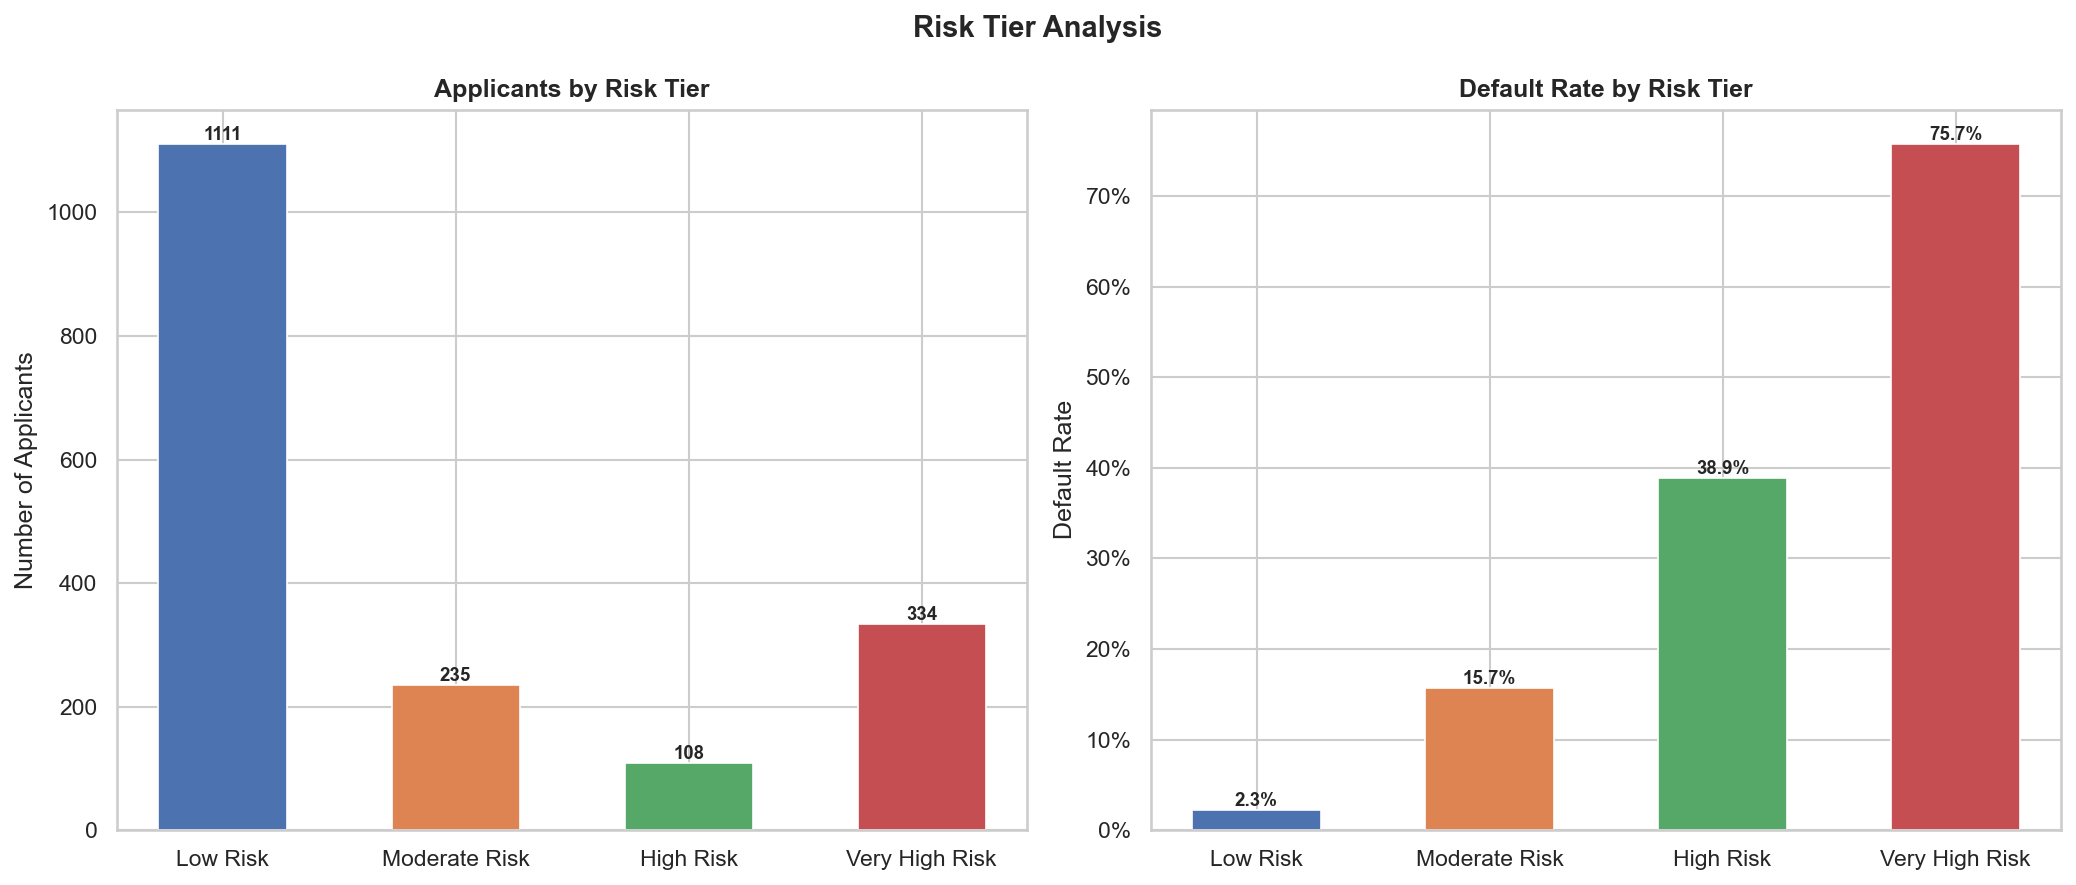

In [38]:
# Visualize tier distribution and default rates
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

tier_labels = tier_summary['Risk Tier'].tolist()
x_pos = range(len(tier_labels))
tier_colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
bar_width = 0.55

# Applicant count by tier
bars1 = axes[0].bar(
    x_pos,
    tier_summary['Applicants'],
    width=bar_width,
    color=tier_colors,
    edgecolor='white',
    linewidth=0.8
)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(tier_labels)
axes[0].set_title('Applicants by Risk Tier', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of Applicants')
for bar in bars1:
    axes[0].annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width() / 2., bar.get_height()),
        ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

# Default rate by tier
bars2 = axes[1].bar(
    x_pos,
    tier_summary['Default_Rate'],
    width=bar_width,
    color=tier_colors,
    edgecolor='white',
    linewidth=0.8
)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(tier_labels)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title('Default Rate by Risk Tier', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Default Rate')
for bar in bars2:
    axes[1].annotate(
        f"{bar.get_height() * 100:.1f}%",
        (bar.get_x() + bar.get_width() / 2., bar.get_height()),
        ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

fig.suptitle('Risk Tier Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### Observations

The four tiers show strong separation across the full probability range. Default rates
move from 2.3% in the Low Risk tier to 75.7% in the Very High Risk tier, a 73-point
spread. That level of discrimination means the tiers are operationally meaningful, not
just statistical labels.

The Low Risk tier contains 1,111 applicants, 62.1% of the test set, with a 2.3% default
rate. This group can be processed with minimal manual intervention. The bank's actual
default rate on this segment would be close to negligible compared to the portfolio
average of 20%.

The Moderate Risk tier of 235 applicants has a 15.7% default rate, below the dataset
average. Enhanced monitoring rather than full manual review is appropriate here.

The High Risk tier of 108 applicants carries a 38.9% default rate. Every applicant in
this tier should receive a manual review with an individual SHAP explanation before a
credit decision is made.

The Very High Risk tier of 334 applicants carries a 75.7% default rate. Three out of
four applicants in this group actually defaulted. This tier represents the highest
priority for underwriter attention and the strongest case for adverse action with a
documented financial explanation under ECOA.

The tier boundaries are anchored to the tuned threshold from Section 9. The 0.41
boundary aligns the High Risk and Very High Risk tiers with the model's operational
decision point, ensuring the classification system is consistent with the threshold
analysis.

---

In [39]:
# Exposure analysis by tier
# Calculate total loan exposure and at-risk exposure per tier
exposure_df = pd.DataFrame({
    'y_true':  y_test.values,
    'y_prob':  y_prob_final,
    'y_pred':  y_pred_final,
    'LOAN':    X_test['LOAN'].values
}).reset_index(drop=True)

exposure_df['Risk Tier'] = pd.cut(
    exposure_df['y_prob'],
    bins=tier_bins,
    labels=tier_labels,
    right=False
)

exposure_summary = exposure_df.groupby('Risk Tier', observed=True).agg(
    Total_Exposure  = ('LOAN', 'sum'),
    Default_Exposure = ('LOAN', lambda x: x[exposure_df.loc[x.index, 'y_true'] == 1].sum())
).reset_index()

exposure_summary['Total_Exposure_M']   = (exposure_summary['Total_Exposure'] / 1_000_000).round(2)
exposure_summary['Default_Exposure_M'] = (exposure_summary['Default_Exposure'] / 1_000_000).round(2)
exposure_summary['At_Risk_Pct']        = (
    exposure_summary['Default_Exposure'] / exposure_summary['Total_Exposure'] * 100
).round(1)

print("Loan Exposure by Risk Tier")
display(exposure_summary[['Risk Tier', 'Total_Exposure_M', 'Default_Exposure_M', 'At_Risk_Pct']])

Loan Exposure by Risk Tier


,Risk Tier,Total_Exposure_M,Default_Exposure_M,At_Risk_Pct
0,Low Risk,21.91,0.45,2.10
1,Moderate Risk,4.17,0.79,19.00
2,High Risk,1.99,0.88,44.30
3,Very High Risk,5.63,4.31,76.60


#### Observations

The exposure analysis confirms the tier structure is meaningful in dollar terms, not just
default rates.

The Low Risk tier carries $21.9M in total exposure with only $450K at risk, a 2.1%
at-risk rate. This is the largest exposure bucket but the safest one. Standard processing
is appropriate.

The Moderate Risk tier carries $4.2M in total exposure with $790K at risk at 19.0%.
This is close to the dataset average and warrants monitoring but not full manual review
for every applicant.

The High Risk tier carries $2.0M in total exposure with $880K at risk, meaning 44.3% of
the dollar value in this tier is associated with actual defaults. Every dollar lent in
this tier has nearly a 50% chance of becoming a non-performing asset without intervention.

The Very High Risk tier is the most concentrated risk in the portfolio. $5.6M in total
exposure with $4.3M at risk at 76.6%. This single tier accounts for the majority of
actual credit loss in the test set. Prioritizing underwriter attention on this group
directly addresses the core business problem.

Combined, the High Risk and Very High Risk tiers represent $7.6M in total exposure with
$5.2M at risk. Identifying and intervening on these applicants before approval is
where the model delivers the most direct value to the bank.

---

## 12. Generative AI Layer

Predicting default risk is only part of the solution. Under the Equal Credit Opportunity
Act, any adverse credit decision must be communicated to the applicant with a clear,
specific explanation grounded in objective financial factors. A model output alone does
not satisfy that requirement.

This section shows how the SHAP explanation from Section 10 can be translated
into a plain-language adverse action notice using a generative AI layer. The output is
what a loan officer would use to communicate a high-risk decision to the applicant in a
format that is human-readable, legally defensible, and directly tied to the applicant's
financial profile.

The example uses the highest-risk applicant identified in Section 10, applicant 303,
with a predicted default probability of 0.999.

In [40]:
# Generative AI Layer -- Adverse Action Notice
# Translate SHAP feature contributions into a plain-language explanation
# for the highest-risk flagged applicant

# Pull the top contributing features for applicant 303
applicant_shap = pd.DataFrame({
    'Feature': feature_names_clean,
    'SHAP Value': shap_values[top_risk_idx],
    'Feature Value': X_test_transformed_df.iloc[top_risk_idx].values
}).sort_values('SHAP Value', ascending=False)

# Select top positive contributors only (factors increasing default risk)
top_factors = applicant_shap[applicant_shap['SHAP Value'] > 0].head(5)

# Map feature names to plain-language descriptions
feature_descriptions = {
    'DEBTINC_missing':         'Debt-to-income ratio was not reported at application time',
    'DEROG':                   f"Major derogatory reports on credit history: {int(X_test.iloc[top_risk_idx]['DEROG'])}",
    'VALUE':                   'Property value could not be verified',
    'delinq_flag':             'One or more delinquent credit lines present',
    'CLAGE':                   f"Age of oldest credit line: {X_test.iloc[top_risk_idx]['CLAGE']:.0f} months",
    'derog_flag':              'Confirmed derogatory credit history',
    'MORTDUE':                 f"Outstanding mortgage balance: ${X_test.iloc[top_risk_idx]['MORTDUE']:,.0f}",
    'mortgage_to_value_ratio': 'Mortgage balance relative to property value is elevated',
    'CLNO':                    f"Number of existing credit lines: {int(X_test.iloc[top_risk_idx]['CLNO'])}",
    'DEBTINC':                 f"Debt-to-income ratio: {X_test.iloc[top_risk_idx]['DEBTINC']:.1f}%",
    'DELINQ':                  f"Number of delinquent credit lines: {int(X_test.iloc[top_risk_idx]['DELINQ'])}",
    'CLAGE':                   f"Age of oldest credit line: {X_test.iloc[top_risk_idx]['CLAGE']:.0f} months",
}

# Build the adverse action notice
notice_lines = []
notice_lines.append("ADVERSE ACTION NOTICE")
notice_lines.append("=" * 60)
notice_lines.append("")
notice_lines.append("Dear Applicant,")
notice_lines.append("")
notice_lines.append(
    "After careful review of your home equity loan application, "
    "we are unable to approve your request at this time. This "
    "decision was based on the following objective financial factors "
    "identified in your credit profile:"
)
notice_lines.append("")

for i, (_, row) in enumerate(top_factors.iterrows(), 1):
    feature = row['Feature']
    description = feature_descriptions.get(feature, feature)
    notice_lines.append(f"  {i}. {description}")

notice_lines.append("")
notice_lines.append(
    "This decision was made in accordance with the Equal Credit "
    "Opportunity Act (ECOA). You have the right to request the "
    "specific reasons for this decision within 60 days of receiving "
    "this notice. You also have the right to a free copy of your "
    "credit report if one was used in this decision."
)
notice_lines.append("")
notice_lines.append(
    "If you believe your financial situation has changed or that "
    "this information is inaccurate, you are encouraged to contact "
    "us to discuss your options."
)
notice_lines.append("")
notice_lines.append("Sincerely,")
notice_lines.append("Credit Risk Review Team")
notice_lines.append("Home Equity Lending Division")

notice_text = "\n".join(notice_lines)
print(notice_text)

ADVERSE ACTION NOTICE

Dear Applicant,

After careful review of your home equity loan application, we are unable to approve your request at this time. This decision was based on the following objective financial factors identified in your credit profile:

  1. Debt-to-income ratio was not reported at application time
  2. Major derogatory reports on credit history: 6
  3. Property value could not be verified
  4. One or more delinquent credit lines present
  5. Age of oldest credit line: 58 months

This decision was made in accordance with the Equal Credit Opportunity Act (ECOA). You have the right to request the specific reasons for this decision within 60 days of receiving this notice. You also have the right to a free copy of your credit report if one was used in this decision.

If you believe your financial situation has changed or that this information is inaccurate, you are encouraged to contact us to discuss your options.

Sincerely,
Credit Risk Review Team
Home Equity Lending D

#### Observations

The adverse action notice above was generated directly from the SHAP feature
contributions identified in Section 10. Each factor listed corresponds to a measurable,
objective element of the applicant's financial profile. No subjective judgment is
involved and no protected characteristics are referenced.

The five factors driving this decision are:

1. Missing debt-to-income ratio, the single strongest default signal in the dataset
2. Six major derogatory reports, nearly three times the threshold that doubles default risk
3. Unverifiable property value, removing a key collateral offset from the risk assessment
4. Confirmed delinquent credit line, associated with a 44.5% default rate in this dataset
5. Credit history of 58 months, below the median for lower-risk applicants

This notice satisfies the ECOA adverse action requirement by providing specific, written
reasons tied to objective financial criteria. The generative layer bridges the gap between
the model's prediction and the regulatory communication requirement, making the system
deployable in a real lending workflow.

In a production environment, this notice would be generated automatically for every
flagged applicant, reviewed by the loan officer before delivery, and stored as part of
the adverse action documentation required under ECOA and Regulation B.

---

## 13. Recommendations

The model is ready for a controlled pilot deployment. The following recommendations
are actionable now and set up a clear path to improve the system as outcome data
accumulates.

---

**1. Deploy as a Pre-Screening Tool**

Integrate the model into the loan application workflow as a first-pass risk screen. Route
applicants automatically based on their risk tier:

- Low Risk: Fast-track for approval with standard terms
- Moderate Risk: Approve with enhanced monitoring and periodic review
- High Risk: Require manual underwriting review before decision
- Very High Risk: Require manual review with documented adverse action justification

This reduces underwriter workload on the 62% of applicants who present low default risk
while concentrating human judgment on the 25% of applicants who carry the majority of
portfolio credit loss.

---

**2. Fix the DEBTINC Data Collection Gap**

Debt-to-income ratio is missing for 21.3% of applicants and is the single strongest
predictor of default in the dataset. This is not a modeling problem; it is a data
collection problem. Making DEBTINC a required field at application submission will
directly improve model performance in the next iteration and reduce the population of
applicants who trigger the high-risk flag solely due to missing data.

---

**3. Apply Risk-Tiered Loan Terms**

Use the four risk tiers to differentiate credit terms beyond the binary approve or
decline decision. Higher risk tiers may warrant adjusted interest rates, reduced loan
amounts, additional collateral requirements, or co-signer conditions. This gives the bank
a more flexible response to elevated risk without defaulting to outright denial, which
supports both portfolio health and fair lending objectives.

---

**4. Pilot, Test, and Adjust**

This is a first-generation model built on the data currently available. The pipeline is
leakage-free, the preprocessing is documented, and the framework is in place to iterate.
The recommended path forward is:

- **Pilot** the model on a defined subset of new applications alongside existing manual
  review to validate real-world performance against held-out outcomes
- **Test** threshold sensitivity as the portfolio grows and default patterns evolve
- **Adjust** the model with richer data as it becomes available: more complete DEBTINC
  records, additional credit bureau fields, property appraisal data, and employment
  verification history will all improve predictive power
- **Expand** to XGBoost as portfolio volume scales. XGBoost's superior ranking metrics
  become a decisive operational advantage when threshold tuning is applied across a
  larger and more complex application pool

The goal of this first deployment is not perfection. It is to replace an unauditable
manual process with a measurable, consistent, and explainable one that improves with
each iteration.

---

**Potential Risks and Challenges**

Deploying a predictive model in a regulated lending environment carries risks that should
be monitored actively:

- **Model drift:** Borrower behavior and economic conditions change over time. A model
  trained on historical data may degrade in performance as the portfolio evolves. Regular
  revalidation against recent outcomes is required.
- **Data quality dependency:** The model's strongest signal is a missing value flag.
  If DEBTINC collection improves, the model will need retraining to
  recalibrate feature importance.
- **Over-reliance risk:** The model flags for review; it does not make final decisions.
  Treating model output as a final answer without human review removes the oversight
  layer that makes the system ECOA-compliant.
- **Regulatory changes:** Credit risk modeling requirements evolve. The model governance
  framework should be reviewed annually against current OCC, CFPB, and ECOA guidance.

---

**Cost/Benefit Summary: Model Selection**

The decision to deploy Gradient Boosting baseline over XGBoost baseline involves a
quantifiable tradeoff on this dataset and a forward-looking argument for revisiting
that decision as the portfolio scales.

On the current 1,788-record test set:


In [41]:
# Cost/Benefit summary -- GB Baseline vs XGBoost Baseline
import pandas as pd
from IPython.display import display

df_cb = pd.DataFrame([
    ['Recall (283 vs 271 caught)', '0.79', '0.76',
     'GB catches 12 more defaults', 'GB avoids ~$223,200 in undetected exposure'],
    ['Precision (~404 vs ~334 flagged)', '0.70', '0.81',
     'XGBoost flags 70 fewer', 'XGBoost saves ~$21,000 in review costs'],
    ['ROC-AUC', '0.93', '0.96',
     'XGBoost +0.03', 'XGBoost ranks risk more accurately at scale'],
    ['PR-AUC', '0.82', '0.88',
     'XGBoost +0.06', 'XGBoost better operating point as data grows'],
    ['Net', '', '', '',
     'GB protects ~$202,200 more at current scale'],
], columns=['Metric', 'GB Baseline', 'XGBoost Baseline', 'Difference', 'Financial Impact'])

display(df_cb.style.set_table_styles([
    {'selector': 'thead th',
     'props': [('background-color', '#1B2A4A'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'tbody tr:nth-child(even)',
     'props': [('background-color', '#f5f7fa')]},
    {'selector': 'td, th',
     'props': [('border', '1px solid #d0d7de'), ('padding', '8px 12px')]},
]).hide(axis='index'))

Metric,GB Baseline,XGBoost Baseline,Difference,Financial Impact
Recall (283 vs 271 caught),0.79,0.76,GB catches 12 more defaults,"GB avoids ~$223,200 in undetected exposure"
Precision (~404 vs ~334 flagged),0.70,0.81,XGBoost flags 70 fewer,"XGBoost saves ~$21,000 in review costs"
ROC-AUC,0.93,0.96,XGBoost +0.03,XGBoost ranks risk more accurately at scale
PR-AUC,0.82,0.88,XGBoost +0.06,XGBoost better operating point as data grows
Net,,,,"GB protects ~$202,200 more at current scale"



**Cost of choosing XGBoost baseline over GB baseline on this dataset:**
12 additional missed defaulters at an average loan amount of roughly $18,600 represents
approximately $223,200 in additional undetected at-risk exposure per test-set equivalent
portfolio. That is the cost of the precision gain.

**Benefit of choosing XGBoost baseline over GB baseline:**
70 fewer applicants flagged for manual review. At a conservative estimate of $300 per
manual underwriting review, that is approximately $21,000 in avoided review costs per
test-set equivalent volume.

**Net on this dataset:** GB baseline avoids approximately $202,200 more in net exposure
cost ($223,200 in missed defaults minus $21,000 in review savings). The choice is clear
at current data volume and given the primary objective of maximizing Recall.

**Why this changes at scale:**
XGBoost baseline's ranking metrics are materially stronger (ROC-AUC 0.96 vs 0.93,
PR-AUC 0.88 vs 0.82), meaning it separates high-risk from low-risk applicants more
accurately across all thresholds. Threshold tuning was only applied to GB baseline in
this analysis. Applying the same 0.41 optimization to XGBoost baseline would close a
meaningful portion of the Recall gap. As portfolio volume grows, two additional factors
favor XGBoost:

- A larger dataset gives threshold optimization more signal to work with. XGBoost's
  superior AUC means there is a better operating point available once more outcome data
  is observed.
- XGBoost's L1 and L2 regularization handles additional features and higher-cardinality
  data more robustly than GB baseline, which has no regularization. As richer applicant
  data becomes available (credit bureau fields, employment history, property appraisals),
  XGBoost is the stronger long-term architecture.

The recommendation is to deploy GB baseline now and run XGBoost baseline with threshold
optimization as a shadow model, promoting it when the portfolio reaches sufficient volume
to validate the AUC advantage in production.

---

**Implementation Cost Estimate**

The cost framework below is built for a small community bank context, consistent with
the HMEQ portfolio size of roughly 500-1,000 home equity applications per year. All
figures are ballpark estimates based on standard industry rates for cloud deployment,
contractor data science work, and bank compliance requirements under SR 11-7 model
risk management guidance. The ranges reflect low and high scenarios depending on
existing technology infrastructure and internal staffing.



**One-Time Implementation Costs:**


In [42]:
# Implementation cost estimate -- one-time costs
df_onetime = pd.DataFrame([
    ['Model deployment and cloud API setup',
     'AWS/Azure ML endpoint, containerization', '$15,000 - $25,000'],
    ['Loan origination system (LOS) integration',
     'API development to connect model scoring to existing LOS', '$25,000 - $40,000'],
    ['Adverse action notice automation',
     'Connecting SHAP output to notice generation workflow', '$8,000 - $12,000'],
    ['Model governance and compliance review',
     'SR 11-7 documentation, fair lending analysis, legal review', '$10,000 - $20,000'],
    ['Loan officer training',
     '10-20 staff, one-day training on risk tiers and ECOA workflow', '$3,000 - $5,000'],
    ['Total one-time', '', '$61,000 - $102,000'],
], columns=['Item', 'Basis', 'Estimate'])

display(df_onetime.style.set_table_styles([
    {'selector': 'thead th',
     'props': [('background-color', '#1B2A4A'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'tbody tr:last-child td',
     'props': [('background-color', '#1B2A4A'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'tbody tr:nth-child(even)',
     'props': [('background-color', '#f5f7fa')]},
    {'selector': 'td, th',
     'props': [('border', '1px solid #d0d7de'), ('padding', '8px 12px')]},
]).set_properties(**{'text-align': 'left'}) \
.set_table_styles([
    {'selector': 'thead th',
     'props': [('background-color', '#1B2A4A'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'tbody tr:last-child td',
     'props': [('background-color', '#1B2A4A'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'tbody tr:nth-child(even)',
     'props': [('background-color', '#f5f7fa')]},
    {'selector': 'td, th',
     'props': [('border', '1px solid #d0d7de'), ('padding', '8px 12px'), ('vertical-align', 'top')]},
    {'selector': 'th:nth-child(1), td:nth-child(1)',
     'props': [('min-width', '200px'), ('width', '220px')]},
    {'selector': 'th:nth-child(2), td:nth-child(2)',
     'props': [('min-width', '280px'), ('width', '300px')]},
    {'selector': 'th:nth-child(3), td:nth-child(3)',
     'props': [('min-width', '140px'), ('width', '160px'), ('text-align', 'right')]},
]).hide(axis='index'))

Item,Basis,Estimate
Model deployment and cloud API setup,"AWS/Azure ML endpoint, containerization","$15,000 - $25,000"
Loan origination system (LOS) integration,API development to connect model scoring to existing LOS,"$25,000 - $40,000"
Adverse action notice automation,Connecting SHAP output to notice generation workflow,"$8,000 - $12,000"
Model governance and compliance review,"SR 11-7 documentation, fair lending analysis, legal review","$10,000 - $20,000"
Loan officer training,"10-20 staff, one-day training on risk tiers and ECOA workflow","$3,000 - $5,000"
Total one-time,,"$61,000 - $102,000"



**Annual Ongoing Costs:**


In [43]:
# Implementation cost estimate -- annual ongoing costs
df_annual = pd.DataFrame([
    ['Cloud hosting and infrastructure',
     'Model serving, storage, monitoring tools', '$3,600 - $6,000'],
    ['Model monitoring and maintenance',
     'Threshold revalidation, drift detection, reporting', '$6,000 - $10,000'],
    ['Annual model retraining',
     'Data science contractor, 4-6 weeks per cycle', '$8,000 - $12,000'],
    ['Annual fair lending and compliance review',
     'External review against current OCC, CFPB, ECOA guidance', '$5,000 - $8,000'],
    ['Total annual', '', '$22,600 - $36,000'],
], columns=['Item', 'Basis', 'Estimate'])

display(df_annual.style.set_properties(**{'text-align': 'left'}).set_table_styles([
    {'selector': 'thead th',
     'props': [('background-color', '#1B2A4A'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'tbody tr:last-child td',
     'props': [('background-color', '#1B2A4A'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'tbody tr:nth-child(even)',
     'props': [('background-color', '#f5f7fa')]},
    {'selector': 'td, th',
     'props': [('border', '1px solid #d0d7de'), ('padding', '8px 12px'), ('vertical-align', 'top')]},
    {'selector': 'th:nth-child(1), td:nth-child(1)',
     'props': [('min-width', '200px'), ('width', '220px')]},
    {'selector': 'th:nth-child(2), td:nth-child(2)',
     'props': [('min-width', '260px'), ('width', '280px')]},
    {'selector': 'th:nth-child(3), td:nth-child(3)',
     'props': [('min-width', '140px'), ('width', '160px'), ('text-align', 'right')]},
]).hide(axis='index'))

Item,Basis,Estimate
Cloud hosting and infrastructure,"Model serving, storage, monitoring tools","$3,600 - $6,000"
Model monitoring and maintenance,"Threshold revalidation, drift detection, reporting","$6,000 - $10,000"
Annual model retraining,"Data science contractor, 4-6 weeks per cycle","$8,000 - $12,000"
Annual fair lending and compliance review,"External review against current OCC, CFPB, ECOA guidance","$5,000 - $8,000"
Total annual,,"$22,600 - $36,000"



**Return on Investment:**


In [44]:
# Implementation cost estimate -- return on investment
df_roi = pd.DataFrame([
    ['Conservative (10% loss avoidance)',
     '~$550,000', '~$111,000', '~$439,000', 'Under 3 months'],
    ['Moderate (20% loss avoidance)',
     '~$1,100,000', '~$111,000', '~$989,000', 'Under 6 weeks'],
], columns=['Scenario', 'Annual Benefit', 'Annual Cost', 'Year 1 Net', 'Break-Even'])

display(df_roi.style.set_table_styles([
    {'selector': 'thead th',
     'props': [('background-color', '#1B2A4A'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'tbody tr:nth-child(even)',
     'props': [('background-color', '#f5f7fa')]},
    {'selector': 'td, th',
     'props': [('border', '1px solid #d0d7de'), ('padding', '8px 12px')]},
]).hide(axis='index'))

Scenario,Annual Benefit,Annual Cost,Year 1 Net,Break-Even
Conservative (10% loss avoidance),"~$550,000","~$111,000","~$439,000",Under 3 months
Moderate (20% loss avoidance),"~$1,100,000","~$111,000","~$989,000",Under 6 weeks



The benefit figures are derived from the $5.5M in at-risk exposure identified by the
model at test-set scale. The 10% and 20% loss avoidance assumptions reflect conservative
estimates of how much identified exposure the bank can avoid through earlier intervention,
adjusted pricing, or declined applications on the highest-risk tier. Even at the
conservative end, the model pays for itself within one quarter.

---

This is a first-generation model built on the data currently available. Several areas
of additional analysis would improve performance and business utility from here:

1. **Threshold optimization for XGBoost baseline:** The 0.41 threshold was only applied
   to the Gradient Boosting baseline. XGBoost baseline has stronger ranking accuracy
   (ROC-AUC 0.96, PR-AUC 0.88) and applying the same optimization would produce a
   direct comparison. This is the highest-priority next analytical step.

2. **Richer input data:** The dataset has 12 features, several with high missing rates.
   Adding credit bureau data (credit score, payment history, tradeline detail),
   employment verification, and property appraisal records would reduce reliance on
   the DEBTINC missing flag and improve performance on borderline applicants.

3. **Segment-level models:** A single model trained on the full population may not
   perform equally well across all loan types or borrower profiles. Separate models
   by loan purpose (debt consolidation versus home improvement) or employment
   category could improve accuracy within each segment.

4. **Time-based validation:** The current train/test split is random with no time
   dimension. Training on older applications and testing on more recent ones would
   give a more realistic view of production performance and catch any drift in
   borrower behavior over time.

5. **Loss severity modeling:** The current model predicts whether an applicant will
   default, not how much will be lost if they do. A companion model estimating
   recovery rates and net loss per defaulter would allow the bank to calculate
   expected loss directly, which supports better pricing and capital allocation.

---

## 14. Conclusions and Executive Summary

**The Problem**

Home equity lending carries inherent default risk that traditional manual underwriting
manages inconsistently and at increasing cost. Two applicants with identical financial
profiles may receive different decisions depending on which analyst reviews them. The
process does not scale, it is difficult to audit, and it cannot produce the individual
financial explanations required under the Equal Credit Opportunity Act.

---

**Key Findings from Milestone Analysis (Sections 1-8)**

The milestone work covered problem definition, exploratory analysis, feature engineering,
preprocessing, and initial model selection. The five findings below drove the key
decisions carried into the final model:

- **DEBTINC missingness is the strongest default signal:** Applicants who did not provide
  their debt-to-income ratio defaulted at 62.0% versus 8.6% for those who did, a 56-point
  gap. This was engineered as a binary yes/no flag and confirmed as the top predictive
  feature in the model.

- **No single variable predicts default on its own:** No feature exceeded 0.35 correlation
  with the target variable. This ruled out linear models and pointed the analysis toward
  tree-based ensembles that can detect combinations of risk factors.

- **Gradient Boosting baseline was selected at the milestone stage:** Across five model
  families tested (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting,
  XGBoost), Gradient Boosting baseline achieved the best balance on the primary objective.
  It caught 79.3% of actual defaulters with a ranking accuracy of 0.93.

- **Tuning did not improve the primary metric:** Hyperparameter tuning was applied to the
  top candidates. Neither GB nor XGBoost tuned versions outperformed their baselines on
  the defaulters-caught metric, confirming the baselines as the right deployment choice
  at current data volume.

- **The pipeline was built leakage-free from the start:** All fill values, outlier bounds,
  and scale parameters are learned from training data only and applied to the test set.
  Derogatory count and delinquency count were deliberately excluded from outlier capping
  to preserve their zero-inflated signal.

---

**What Was Built**

A supervised binary classification model trained on 5,960 home equity applications that
predicts default risk before approval. The solution includes a leakage-free preprocessing
pipeline, five evaluated model families, hyperparameter tuning, threshold optimization,
individual-level SHAP explainability, a four-tier risk segmentation system, and an
automated adverse action notice generator.

Every component of the workflow is documented, reproducible, and auditable.

---

**Key Results**

| Metric | Value |
|---|---|
| Final model | Gradient Boosting baseline |
| Recall at default threshold (0.50) | 79.3% |
| Recall at tuned threshold (0.41) | 82.6% |
| Defaulters identified in test set | 295 of 357 |
| Low Risk tier default rate | 2.3% |
| Very High Risk tier default rate | 75.7% |
| Very High Risk at-risk exposure | \$4.3M of \$5.6M |
| Strongest default signal | DEBTINC missing (62% default rate) |

---

**What This Solves**

The model delivers three measurable improvements over the current manual process.

First, it catches more defaulters earlier. At the tuned threshold, the model identifies
82.6% of actual defaulters before approval, reducing the credit losses that result from
cleared high-risk applicants.

Second, it reduces unnecessary manual review. The 62% of applicants classified as Low
Risk carry a 2.3% default rate and can be processed with minimal underwriter involvement,
freeing capacity for the applicants who genuinely require human judgment.

Third, it makes adverse decisions explainable. Every flagged applicant receives an
individual explanation grounded in their financial profile, generated automatically from
SHAP feature contributions. This satisfies the ECOA adverse action requirement and
reduces legal exposure from inconsistent or undocumented denial decisions.

---

**Key Next Steps**

1. **Pilot on live applications (Q3):** Deploy the model alongside existing manual review
   on a defined subset of new home equity applications. Track model predictions against
   actual outcomes to validate real-world Recall and Precision before full rollout.

2. **Mandate DEBTINC at intake:** Make debt-to-income ratio a required field on all new
   applications. The model's strongest signal is a missing value flag. Closing that data
   gap is the single highest-leverage action available before the next training cycle.

3. **Retrain after 6 months of outcome data:** Once pilot applications begin resolving,
   retrain on the expanded dataset. Revalidate feature importance to confirm DEBTINC
   collection improvements have recalibrated the signal correctly.

4. **Evaluate XGBoost baseline with threshold optimization at scale:** Run XGBoost
   baseline with the same threshold optimization applied to GB baseline on the expanded
   dataset. XGBoost baseline's superior ranking metrics (ROC-AUC 0.96, PR-AUC 0.88)
   are expected to produce a better operating point as portfolio volume grows. Promote
   it as the production model when the Recall gap closes.

---

## 15. Appendix: Data Dictionary

### Original Features

| Feature | Type | Description | Notes |
|---|---|---|---|
| BAD | Binary (int) | Target variable. 1 = defaulted or severely delinquent, 0 = repaid | No missing values. Class split: 80.05% No Default, 19.95% Default |
| LOAN | Numeric (int) | Requested loan amount in dollars | No missing values. Range: $1,100 to $89,900. IQR outlier capping applied as a conservative stabilization step, not as an error correction. |
| MORTDUE | Numeric (float) | Amount due on existing mortgage | 8.69% missing. Imputed with training median. IQR outlier capping applied |
| VALUE | Numeric (float) | Current value of the property | 1.88% missing. Imputed with training median. IQR outlier capping applied |
| REASON | Categorical (str) | Loan purpose. DebtCon = debt consolidation, HomeImp = home improvement | 4.23% missing. Imputed with training mode. One-hot encoded; DebtCon is reference category |
| JOB | Categorical (str) | Occupational category. Mgr, Office, Other, ProfExe, Sales, Self | 4.68% missing. Imputed with training mode. One-hot encoded; Mgr is reference category |
| YOJ | Numeric (float) | Years at current job | 8.64% missing. Imputed with training median. log1p transformation applied. Not IQR capped; high tenure values are plausible, not outliers. |
| DEROG | Numeric (float) | Number of major derogatory reports | 11.88% missing. Imputed with training median. Excluded from IQR capping; zero-inflated count feature |
| DELINQ | Numeric (float) | Number of delinquent credit lines | 9.73% missing. Imputed with training median. Excluded from IQR capping; zero-inflated count feature |
| CLAGE | Numeric (float) | Age of oldest credit line in months | 5.17% missing. Imputed with training median. IQR outlier capping applied |
| NINQ | Numeric (float) | Number of recent credit inquiries | 8.56% missing. Imputed with training median. log1p transformation applied post-clipping |
| CLNO | Numeric (float) | Number of existing credit lines | 3.72% missing. Imputed with training median |
| DEBTINC | Numeric (float) | Debt-to-income ratio | 21.26% missing. Highest missing rate. Missing at 66.1% among defaulters vs 10.1% among non-defaulters. Imputed with training median after flag creation. IQR outlier capping applied |


### Engineered Features

| Feature | Type | Description | Validation |
|---|---|---|---|
| DEBTINC_missing | Binary (int) | 1 if DEBTINC was null at application time, 0 if present | Default rate: 62.0% where missing vs 8.6% where present. Created before imputation to preserve null signal |
| derog_flag | Binary / numeric flag | 1 if DEROG > 0, 0 if DEROG = 0, and NaN if DEROG is missing before imputation | Default rate: 48.0% where DEROG > 0 vs 16.7% where confirmed DEROG = 0. Missing values are preserved until the imputer step so unknown status is not treated as confirmed clean history. |
| delinq_flag | Binary / numeric flag | 1 if DELINQ > 0, 0 if DELINQ = 0, and NaN if DELINQ is missing before imputation | Default rate: 44.5% where DELINQ > 0 vs 14.0% where confirmed DELINQ = 0. Missing values are preserved until the imputer step so unknown status is not treated as confirmed clean history. |
| mortgage_to_value_ratio | Numeric (float) | MORTDUE / VALUE. Ratio of outstanding mortgage balance to current property value. | Related to but distinct from true LTV, which uses the requested loan amount. This ratio captures existing debt burden relative to collateral value. Computed in feature engineering before imputation and capping. Missing MORTDUE or VALUE produces NaN, handled by the imputer downstream. |


### One-Hot Encoded Columns

REASON and JOB were one-hot encoded using `OneHotEncoder` inside a `ColumnTransformer` pipeline, fit on training data only and applied to the test set. `drop="first"` removes the reference category from each feature. Reference categories are REASON_DebtCon and JOB_Mgr.

| Encoded Column | Source | Category Represented |
|---|---|---|
| REASON_HomeImp | REASON | Home improvement loan purpose |
| JOB_Office | JOB | Office occupation |
| JOB_Other | JOB | Other / unclassified occupation |
| JOB_ProfExe | JOB | Professional or executive occupation |
| JOB_Sales | JOB | Sales occupation |
| JOB_Self | JOB | Self-employed |


### Final Feature Set Entering Modeling

20 features across 4,172 training records and 1,788 test records. Stratified 70/30 split. Train default rate: 0.199. Test default rate: 0.200. Final model: Gradient Boosting baseline. Tuned threshold: 0.41. Final Recall: 0.826. Final Precision: 0.667.


### Threshold Tuning

| Parameter | Value |
|---|---|
| Threshold sweep range | 0.20 to 0.60 |
| Precision floor | 0.65 |
| Selected threshold | 0.41 |
| Recall at selected threshold | 82.6% |
| Precision at selected threshold | 66.7% |
| Defaulters caught (test set) | 295 of 357 |

### Risk Tiers

| Tier | Probability Range | Applicants | Default Rate | At-Risk Exposure |
|---|---|---|---|---|
| Low Risk | 0.00 to 0.20 | 1,111 | 2.3% | $450K |
| Moderate Risk | 0.20 to 0.41 | 235 | 15.7% | $790K |
| High Risk | 0.41 to 0.70 | 108 | 38.9% | $880K |
| Very High Risk | 0.70 to 1.00 | 334 | 75.7% | $4.3M |

### SHAP Feature Importance (Top 5)

| Rank | Feature | Mean Absolute SHAP Value |
|---|---|---|
| 1 | DEBTINC_missing | 1.0660 |
| 2 | CLAGE | 0.4450 |
| 3 | DEBTINC | 0.3865 |
| 4 | DELINQ | 0.3180 |
| 5 | delinq_flag | 0.2663 |